# Детекция и сегментация планктона без эталонной разметки

**RetinaNet · Faster R-CNN · GrabCut · SAM 2.1**

Работа выполнена на предоставленном наборе из 189 изображений. Исследование
аугментаций использует одну фиксированную выборку из 24 снимков для обеих моделей.
Обучение и дообучение не выполняются. Сохранённые таблицы, изображения и маски
позволяют проверить результаты без повторного инференса.

Четыре группы: **RetinaNet / оригиналы**, **RetinaNet / аугментации**,
**Faster R-CNN / оригиналы**, **Faster R-CNN / аугментации**.
В исходной формулировке после слов «четыре группы экспериментов» список отсутствует;
здесь явно принята факторная схема «2 модели × 2 условия».

**Важно:** COCO не содержит класса «планктон». Названия предсказанных классов
показываются буквально и не являются определением вида организма. Число рамок и
confidence не измеряют точность. mAP, Precision, Recall и истинный IoU масок не
рассчитываются: эталонной разметки нет.

## 0. Запуск и протокол

При `RUN_EXPERIMENTS=False` ячейки читают уже сохранённые результаты.
Для полного пересчёта сначала установите зависимости по README, подключите архив
через `scripts/import_data.py`, скачайте SAM 2.1 и задайте `RUN_EXPERIMENTS=True`.
Полный исходный код ниже встроен в Notebook; те же функции находятся в `src/`.

Для каждой модели: FP32, batch=1, одинаковое ограничение длинной стороны 1024,
внутренний resize 640/1024, NMS=0.5, отчётный score≥0.25. Дополнительно сохранены
кандидаты score≥0.05 и числа рамок при 0.10/0.50. Три прогрева и три измерения
на каждую пару «снимок–вариант». Перед/после измерений CUDA синхронизируется.
Время включает подготовку тензора, передачу на GPU, преобразования модели,
forward, NMS и возврат на CPU; чтение файлов, аугментации и рисование исключены.
Порядок пар перемешан фиксированным seed и одинаков для обеих моделей.

In [1]:
from pathlib import Path
import os
RUN_EXPERIMENTS = False
DATA_DIR = Path(os.environ.get('PLANKTON_DATA_DIR', 'data'))
CHECKPOINT = Path(os.environ.get('PLANKTON_SAM_CHECKPOINT', 'checkpoints/sam2.1_hiera_tiny.pt'))
os.environ.setdefault('TORCH_HOME', str(Path('checkpoints/torch').resolve()))
from IPython.display import display, Image as DisplayImage, Markdown
def show_figure(path, width=1150):
    display(DisplayImage(filename=str(path), width=width))

In [2]:
def unpack_results(root):
    import zipfile
    root=Path(root).resolve()
    restored=0
    for archive in sorted((root/'results_archives').glob('*.zip')):
        with zipfile.ZipFile(archive) as z:
            for member in z.infolist():
                if member.is_dir(): continue
                target=(root/member.filename).resolve()
                if not target.is_relative_to(root/'results'):
                    raise ValueError(f'Unsafe archive member: {member.filename}')
                if target.exists(): continue
                target.parent.mkdir(parents=True,exist_ok=True)
                target.write_bytes(z.read(member))
                restored+=1
    return restored

if not RUN_EXPERIMENTS:
    print("Restored image artifacts:", unpack_results(Path.cwd()))

Restored image artifacts: 0


In [3]:
"""Reproducible, annotation-free microscopy experiments. No training is performed."""
from __future__ import annotations

import argparse
import gc
import hashlib
import json
import os
import platform
import random
import time
from pathlib import Path

import cv2
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
from scipy.optimize import linear_sum_assignment
import torch
import torchvision
from torchvision.models.detection import (
    retinanet_resnet50_fpn_v2, RetinaNet_ResNet50_FPN_V2_Weights,
    fasterrcnn_resnet50_fpn_v2, FasterRCNN_ResNet50_FPN_V2_Weights,
)

ROOT = Path.cwd()
RESULTS = ROOT / 'results'
SEED = 20261112
CONF = 0.25
LONG_SIDE = 1024
REPEATS = 3
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
VARIANTS = [
    ('original', {}),
    ('brightness_1.15', {'brightness': 1.15}),
    ('brightness_1.35', {'brightness': 1.35}),
    ('contrast_0.8', {'contrast': 0.8}),
    ('contrast_0.5', {'contrast': 0.5}),
    ('noise_5', {'noise_sigma': 5}),
    ('noise_20', {'noise_sigma': 20}),
    ('blur_0.8', {'blur_sigma': 0.8}),
    ('blur_2', {'blur_sigma': 2.0}),
    ('gamma_0.7', {'gamma': 0.7}),
    ('gamma_1.5', {'gamma': 1.5}),
    ('hflip', {'geometry': 'hflip'}),
    ('rot90', {'geometry': 'rot90_ccw'}),
]

In [4]:
def setup():
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    torch.set_num_threads(min(4, os.cpu_count() or 1))
    cv2.setNumThreads(1)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False
    for p in ['tables', 'figures', 'detections', 'masks', 'segmentation', 'originals']:
        (RESULTS / p).mkdir(parents=True, exist_ok=True)

def dump(obj, path):
    Path(path).write_text(json.dumps(obj, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')

def read_rgb(path):
    with Image.open(path) as im:
        return np.asarray(ImageOps.exif_transpose(im).convert('RGB')).copy()

def resize_working(im):
    h, w = im.shape[:2]
    scale = min(1.0, LONG_SIDE / max(h, w))
    return cv2.resize(im, (round(w * scale), round(h * scale)), interpolation=cv2.INTER_AREA)

def category(name):
    if name.startswith('202502'):
        return 'multi_object_fields'
    if name.startswith('Bosmina cf longirostris Sackhalin'):
        return 'bosmina_series'
    return 'other_specimens'

def analyse_data(data_dir):
    rows = []
    paths = sorted(p for p in Path(data_dir).rglob('*') if p.suffix.lower() in {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff'})
    if len({p.name for p in paths}) != len(paths):
        raise ValueError('Dataset contains duplicate basenames; rename before running.')
    for i, path in enumerate(paths):
        im = read_rgb(path)
        small = resize_working(im)
        gray = cv2.cvtColor(small, cv2.COLOR_RGB2GRAY).astype(float)
        p5, p95 = np.percentile(gray, [5, 95])
        # Spatial illumination proxy: variability of cell medians, not a ground-truth background mask.
        tile_medians = [np.median(t) for stripe in np.array_split(gray, 4) for t in np.array_split(stripe, 4, axis=1)]
        rows.append(dict(image_id=f'img_{i:03d}', filename=path.name, group=category(path.name),
                         width=im.shape[1], height=im.shape[0], megapixels=im.shape[0]*im.shape[1]/1e6,
                         mean_gray=float(gray.mean()), rms_contrast=float(gray.std()),
                         p95_minus_p5=float(p95-p5), spatial_median_std=float(np.std(tile_medians)),
                         clipped_dark_fraction=float((gray<=1).mean()), clipped_light_fraction=float((gray>=254).mean()),
                         sha256=hashlib.sha256(path.read_bytes()).hexdigest()))
    df = pd.DataFrame(rows)
    df.to_csv(RESULTS / 'tables/dataset_inventory.csv', index=False)
    # Deterministic contrast-stratified exploratory sample, selected BEFORE predictions.
    selected = []
    for group, n in [('multi_object_fields', 12), ('bosmina_series', 6), ('other_specimens', 6)]:
        part = df[df.group == group].sort_values(['rms_contrast', 'filename'])
        selected.append(part.iloc[np.linspace(0, len(part)-1, min(n,len(part))).round().astype(int)])
    sample = pd.concat(selected).reset_index(drop=True)
    sample.to_csv(RESULTS / 'tables/sample_manifest.csv', index=False)
    fig, axes = plt.subplots(4, 6, figsize=(18, 12))
    for ax, row in zip(axes.ravel(), sample.itertuples()):
        im = resize_working(read_rgb(next(p for p in paths if p.name == row.filename)))
        Image.fromarray(im).save(RESULTS / 'originals' / f'{row.image_id}.jpg', quality=92)
        ax.imshow(im); ax.set_title(f'{row.image_id} | {row.width}x{row.height}\nRMS={row.rms_contrast:.1f}', fontsize=9); ax.axis('off')
    fig.suptitle('Fixed sample: 24 / 189 images; contrast-stratified within three source groups')
    fig.tight_layout(); fig.savefig(RESULTS / 'figures/dataset_overview.jpg', dpi=130); plt.close(fig)
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
    axes[0].hist(df.megapixels, bins=15); axes[0].set_xlabel('Image area, megapixels')
    axes[1].hist(df.rms_contrast, bins=15); axes[1].set_xlabel('Grayscale RMS contrast, 0..255')
    axes[2].scatter(df.mean_gray, df.spatial_median_std, s=15); axes[2].set_xlabel('Mean intensity'); axes[2].set_ylabel('Spatial median std (proxy)')
    fig.tight_layout(); fig.savefig(RESULTS / 'figures/dataset_statistics.png', dpi=140); plt.close(fig)
    return df, sample

## 1. Исходные данные

Инвентаризация охватывает все 189 снимков: размеры, среднюю яркость, RMS-контраст,
диапазон P95–P5, доли отсечённых пикселей и неоднородность медиан по сетке 4×4.
Последний показатель — лишь пространственная характеристика изображения,
поскольку истинная маска фона отсутствует. Объекты могут влиять на эту оценку.

Выборка формируется **до инференса**: 12 кадров серии с цифровыми именами,
6 снимков серии Bosmina и 6 остальных. В каждой группе берутся равномерные
позиции по ранжированному RMS-контрасту. Это разведочная выборка с охватом
контрастности, а не случайная оценка всего датасета. Кадры одной серии могут
быть зависимы. Фрагменты `obj/class/conf` в именах не используются как разметка.

,width,height,megapixels,mean_gray,rms_contrast,p95_minus_p5
count,189.00,189.00,189.00,189.00,189.00,189.00
mean,2176.41,1681.23,3.84,174.37,36.86,112.12
std,529.65,360.34,1.72,29.24,16.98,53.64
min,482.00,572.00,0.34,94.56,12.08,15.00
25%,2048.00,1536.00,3.15,168.00,24.52,77.00
50%,2048.00,1536.00,3.15,180.64,33.13,106.00
75%,2592.00,1944.00,5.04,190.03,45.55,143.00
max,3584.00,2748.00,9.85,220.19,93.86,255.00


,image_id,filename,group,rms_contrast
0,img_036,20250213135317232.jpg,multi_object_fields,12.08
1,img_005,20250213131707578.jpg,multi_object_fields,14.97
2,img_057,20250213140037676.jpg,multi_object_fields,17.30
3,img_019,20250213132044082.jpg,multi_object_fields,18.07
4,img_061,20250213140135600.jpg,multi_object_fields,19.02
5,img_042,20250213135610304.jpg,multi_object_fields,20.39
6,img_052,20250213135821844.jpg,multi_object_fields,23.75
7,img_038,20250213135452821.jpg,multi_object_fields,26.34
8,img_030,20250213132415074.jpg,multi_object_fields,27.90
9,img_040,20250213135550645.jpg,multi_object_fields,31.48


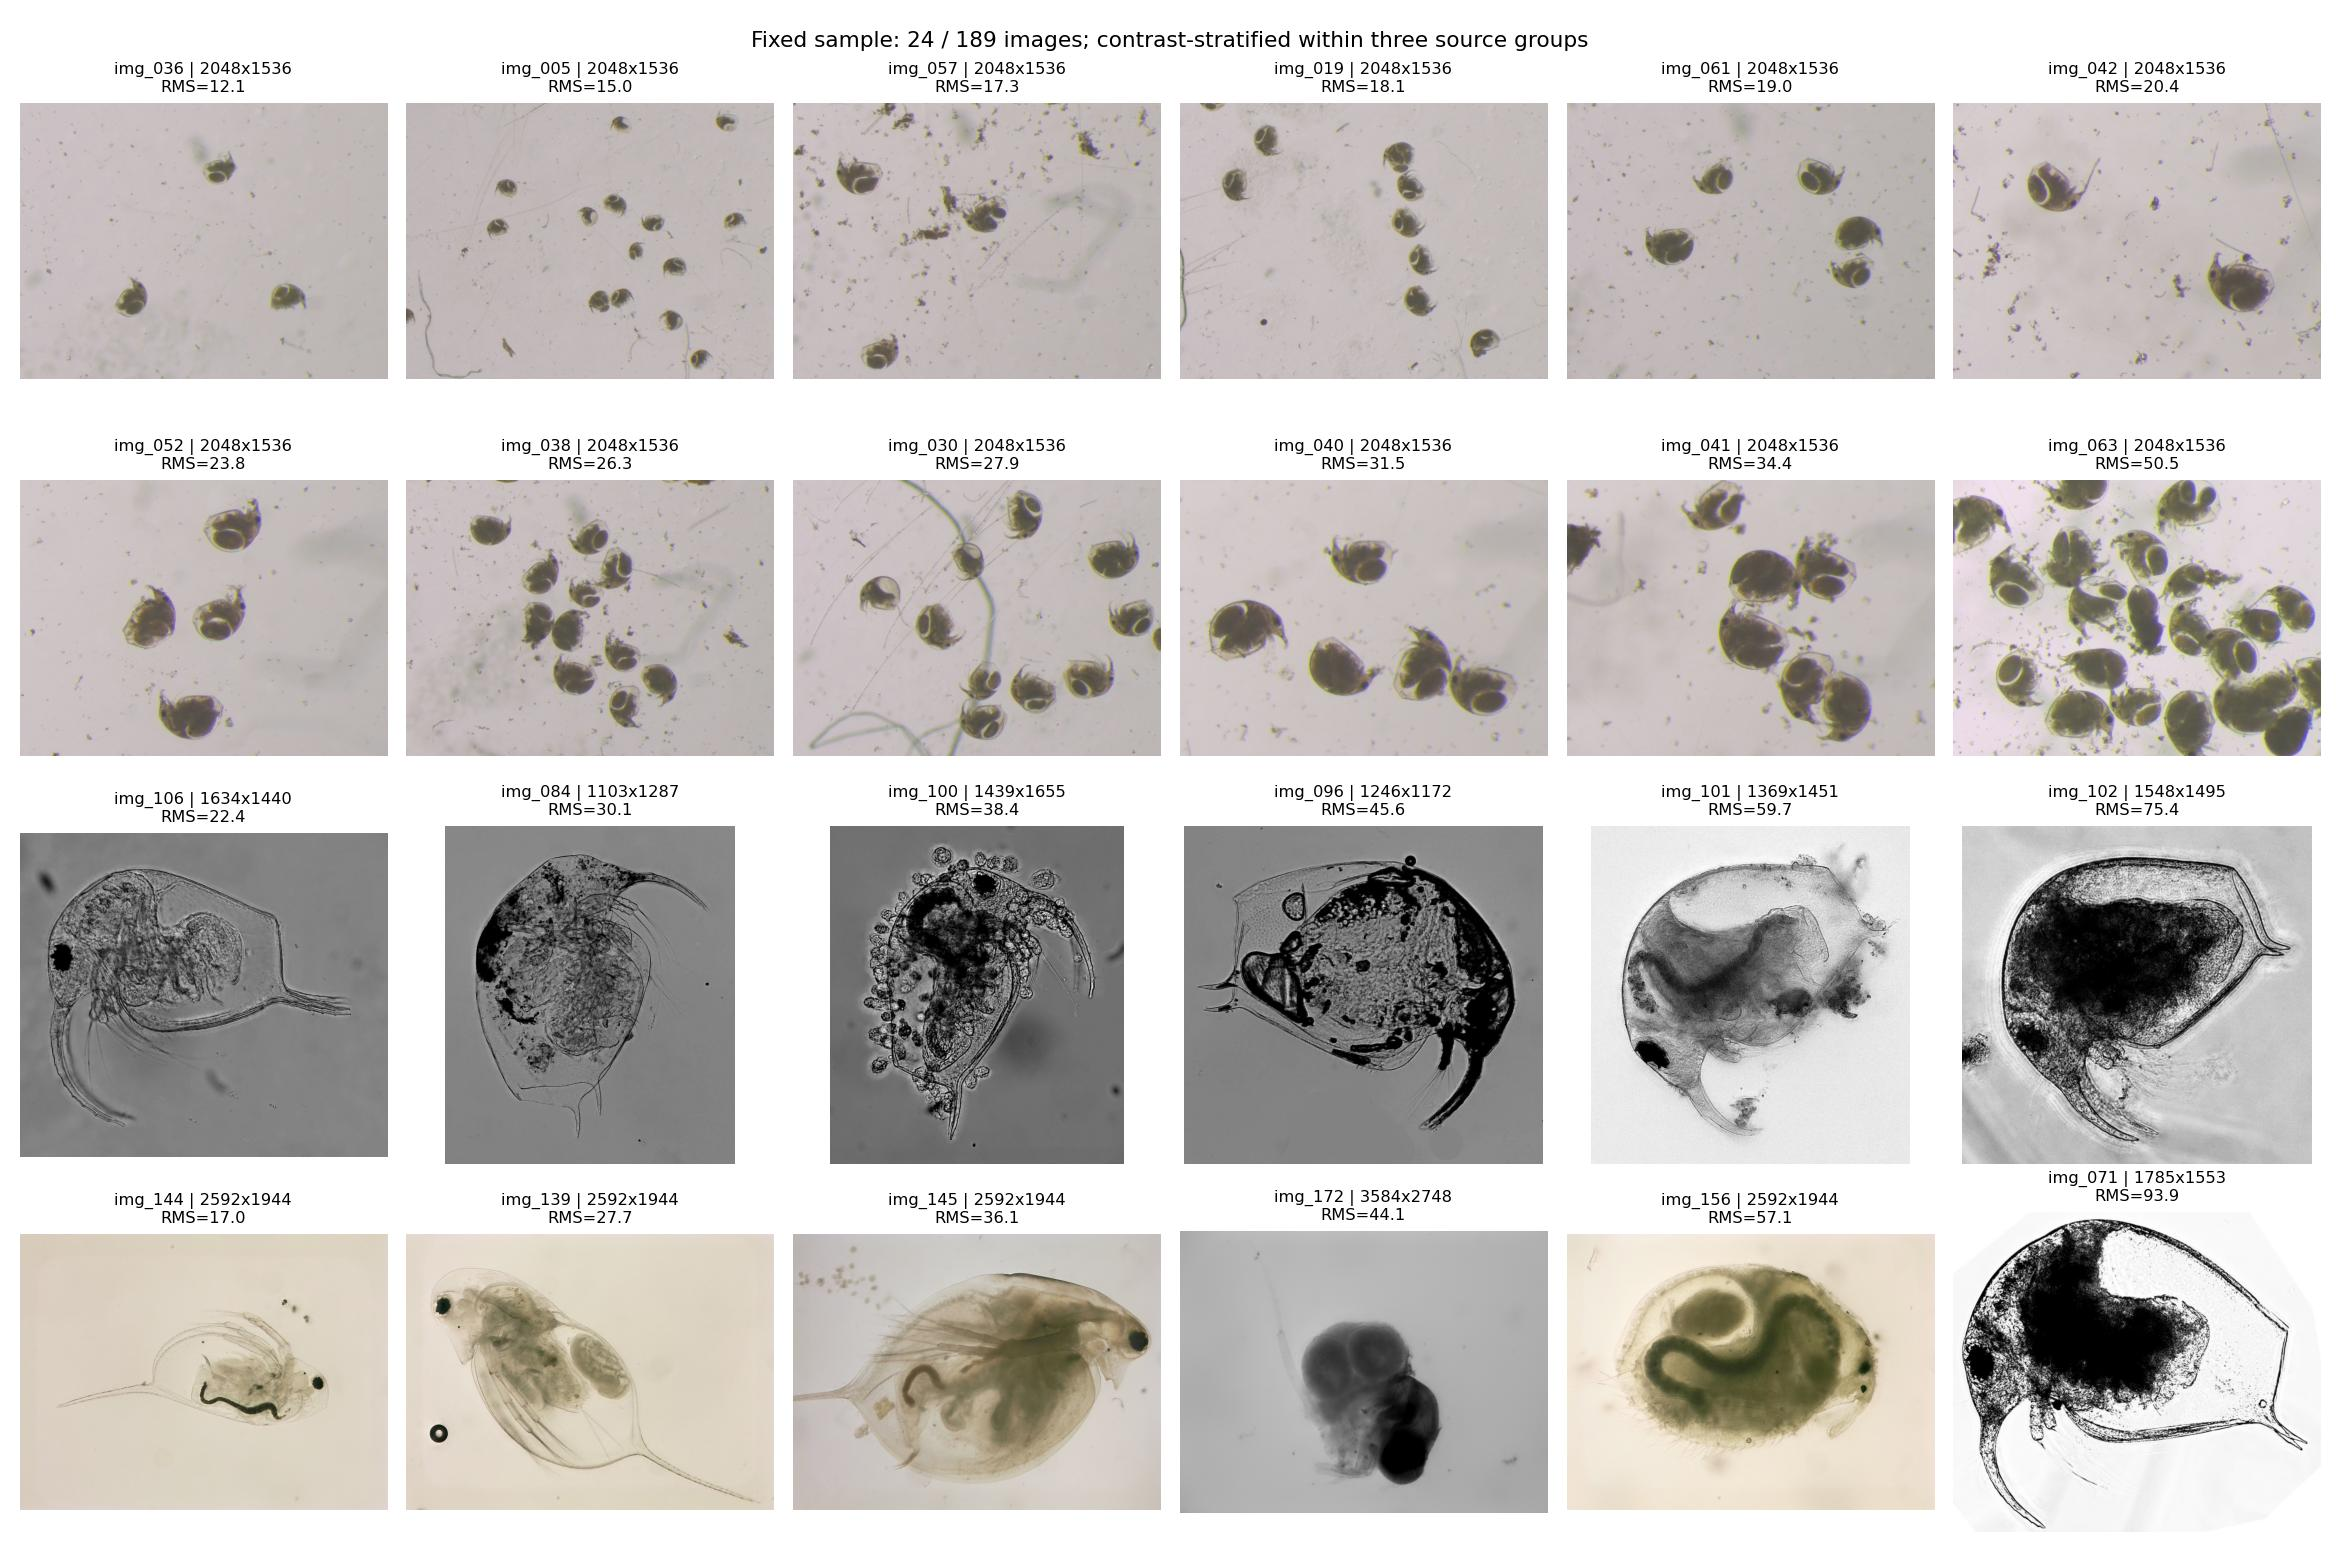

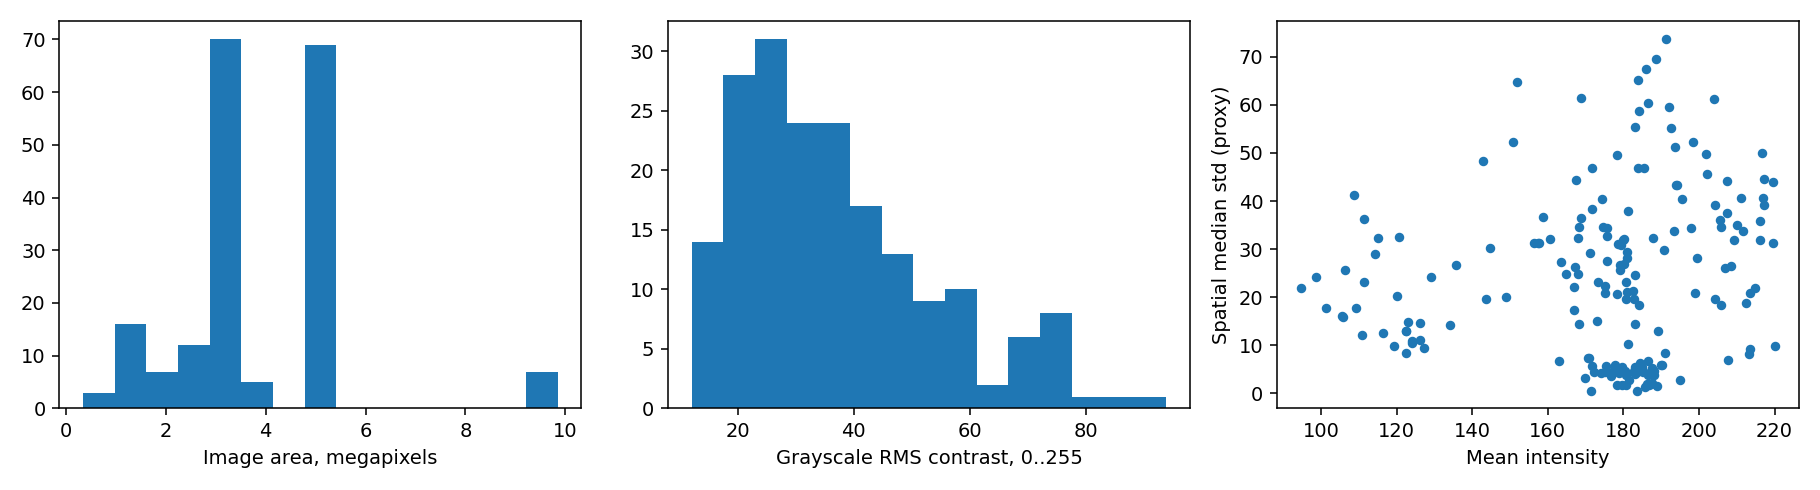

In [5]:
setup()
if RUN_EXPERIMENTS:
    inventory, sample = analyse_data(DATA_DIR)
else:
    inventory = pd.read_csv(RESULTS / 'tables/dataset_inventory.csv')
    sample = pd.read_csv(RESULTS / 'tables/sample_manifest.csv')
display(inventory[['width','height','megapixels','mean_gray','rms_contrast','p95_minus_p5']].describe().round(2))
display(sample[['image_id','filename','group','rms_contrast']].round(2))
show_figure(RESULTS / 'figures/dataset_overview.jpg')
show_figure(RESULTS / 'figures/dataset_statistics.png')

## 2. Аугментации

Реализовано шесть семейств: яркость (×1.15, ×1.35), контраст (×0.8, ×0.5
относительно среднего канала), независимый гауссов шум (σ=5, 20 в шкале 0–255),
гауссово размытие (σ=0.8, 2 пикселя), гамма (γ=0.7, 1.5), отражение и поворот
на 90° против часовой стрелки. Итого 12 вариантов + оригинал.
Шум детерминирован по seed, идентификатору снимка и имени преобразования.
Комбинированных преобразований нет, чтобы разделить их влияние.

Умеренные фотометрические изменения моделируют различия освещения. Сильное
осветление приводит к клиппингу; низкий контраст, шум и размытие скрывают
щетинки, прозрачные края и внутренние структуры. Гамма изменяет тональные
отношения и не является физической калибровкой микроскопа. Поворот на 90° и
отражение сохраняют пиксели без интерполяции и допустимы для задачи локализации
при произвольной ориентации препарата. Отражение нужно исключить, если важна
биологическая асимметрия. Масштабирование при подготовке до 1024 уже ограничивает
сохранение мелких признаков; метрические размеры без калибровки не оцениваются.

In [6]:
def augment(im, name, image_id):
    params = dict(VARIANTS)[name]
    x = im.astype(np.float32)
    if 'brightness' in params: x *= params['brightness']
    if 'contrast' in params: x = (x - x.mean(axis=(0,1), keepdims=True)) * params['contrast'] + x.mean(axis=(0,1), keepdims=True)
    if 'noise_sigma' in params:
        seed = int.from_bytes(hashlib.sha256(f'{SEED}:{image_id}:{name}'.encode()).digest()[:8], 'little')
        x += np.random.default_rng(seed).normal(0, params['noise_sigma'], x.shape)
    if 'blur_sigma' in params: x = cv2.GaussianBlur(x, (0,0), params['blur_sigma'])
    if 'gamma' in params: x = 255.0 * np.power(x/255.0, params['gamma'])
    if name == 'hflip': x = x[:, ::-1]
    if name == 'rot90': x = np.rot90(x)
    return np.ascontiguousarray(np.clip(x, 0, 255).round().astype(np.uint8))

def augmentation_gallery(sample):
    # Both a multi-object field and a fine-structure specimen; all tested intensity levels.
    for row in [sample.iloc[4], sample.iloc[15], sample.iloc[-1]]:
        im = read_rgb(RESULTS / 'originals' / f'{row.image_id}.jpg')
        fig, axes = plt.subplots(3, 5, figsize=(16, 10))
        for ax, (name, _) in zip(axes.ravel(), VARIANTS):
            ax.imshow(augment(im, name, row.image_id)); ax.set_title(name); ax.axis('off')
        for ax in axes.ravel()[len(VARIANTS):]: ax.axis('off')
        fig.suptitle(f'Augmentations | {row.image_id}'); fig.tight_layout()
        fig.savefig(RESULTS / 'figures' / f'augmentations_{row.image_id}.jpg', dpi=120); plt.close(fig)
    dump(dict(VARIANTS), RESULTS / 'augmentation_parameters.json')

,variant,parameters
0,original,{}
1,brightness_1.15,{'brightness': 1.15}
2,brightness_1.35,{'brightness': 1.35}
3,contrast_0.8,{'contrast': 0.8}
4,contrast_0.5,{'contrast': 0.5}
5,noise_5,{'noise_sigma': 5}
6,noise_20,{'noise_sigma': 20}
7,blur_0.8,{'blur_sigma': 0.8}
8,blur_2,{'blur_sigma': 2.0}
9,gamma_0.7,{'gamma': 0.7}


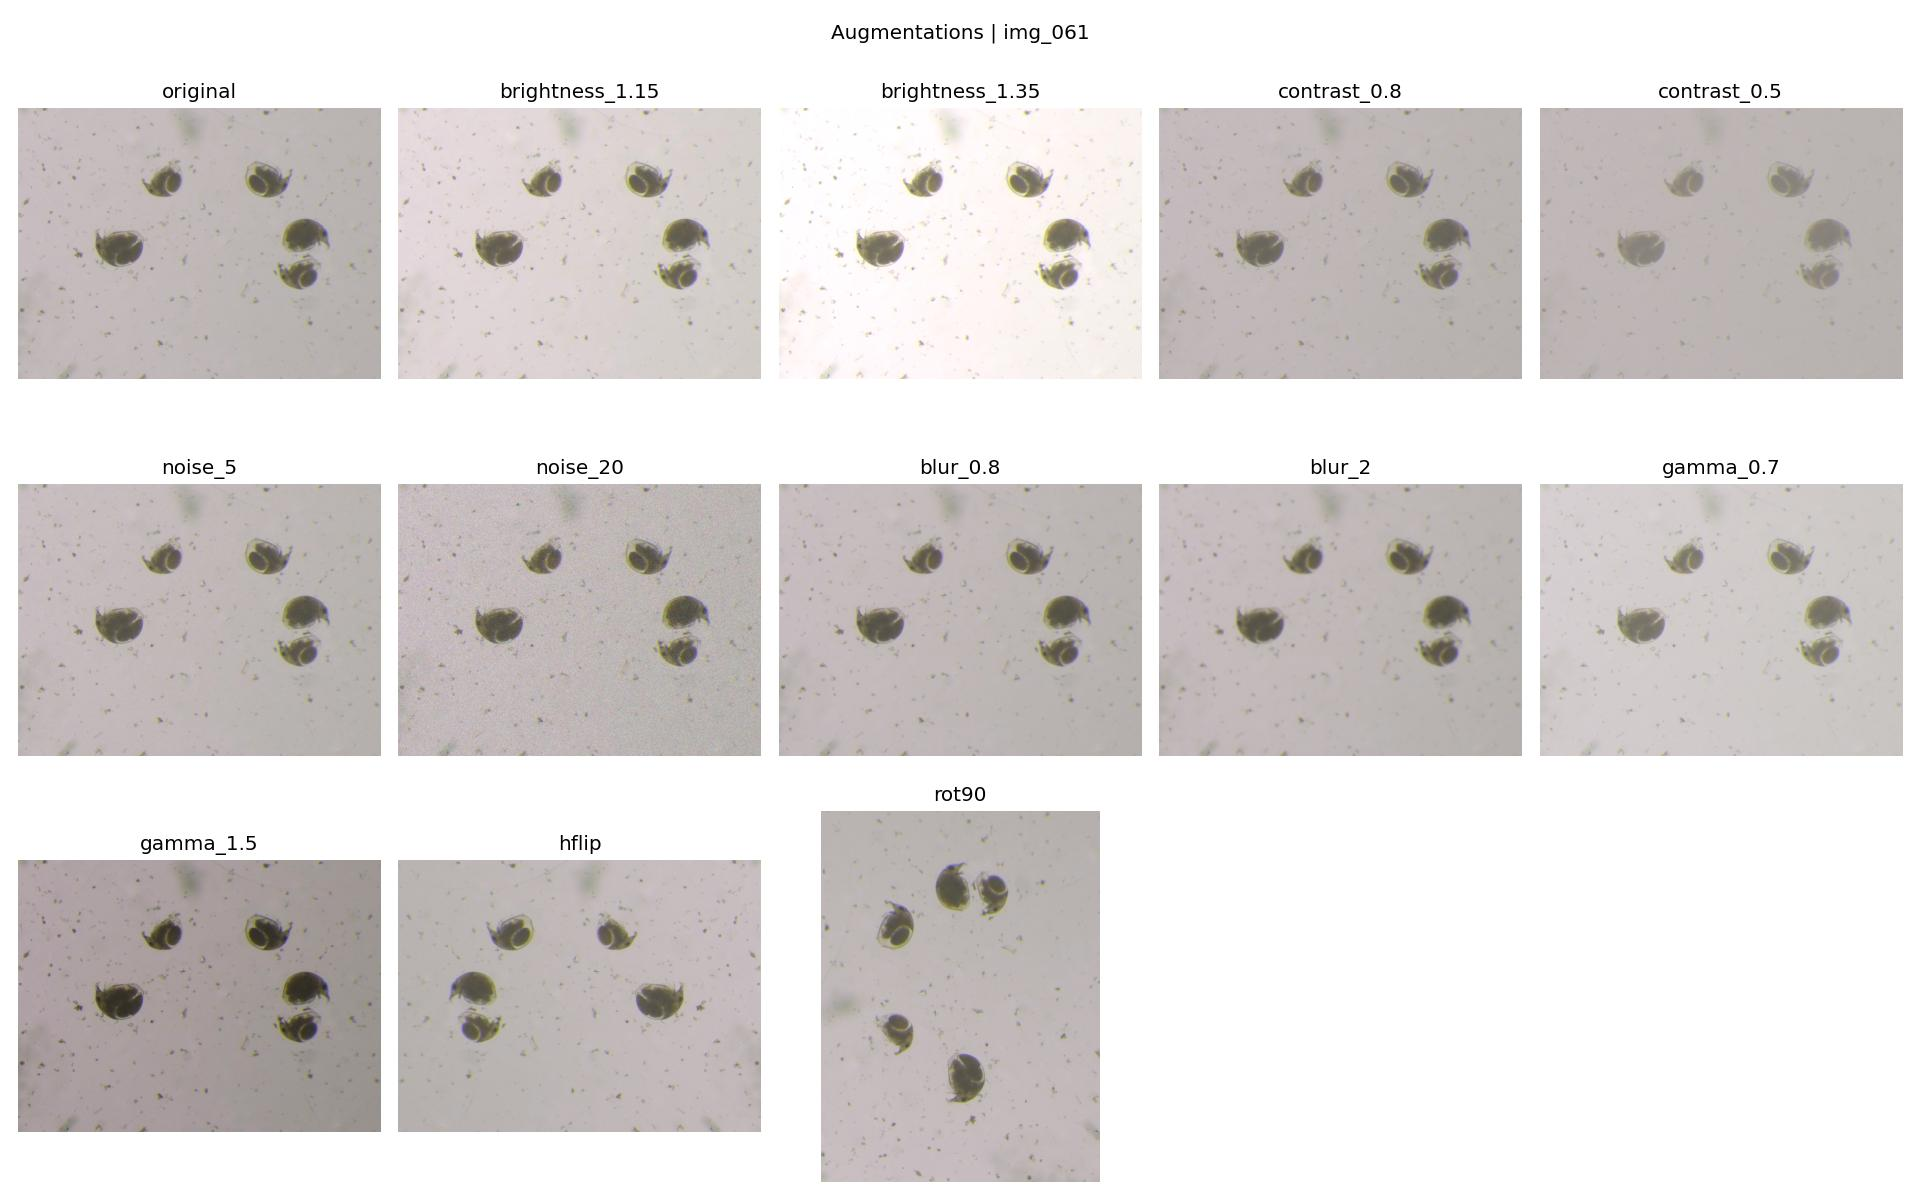

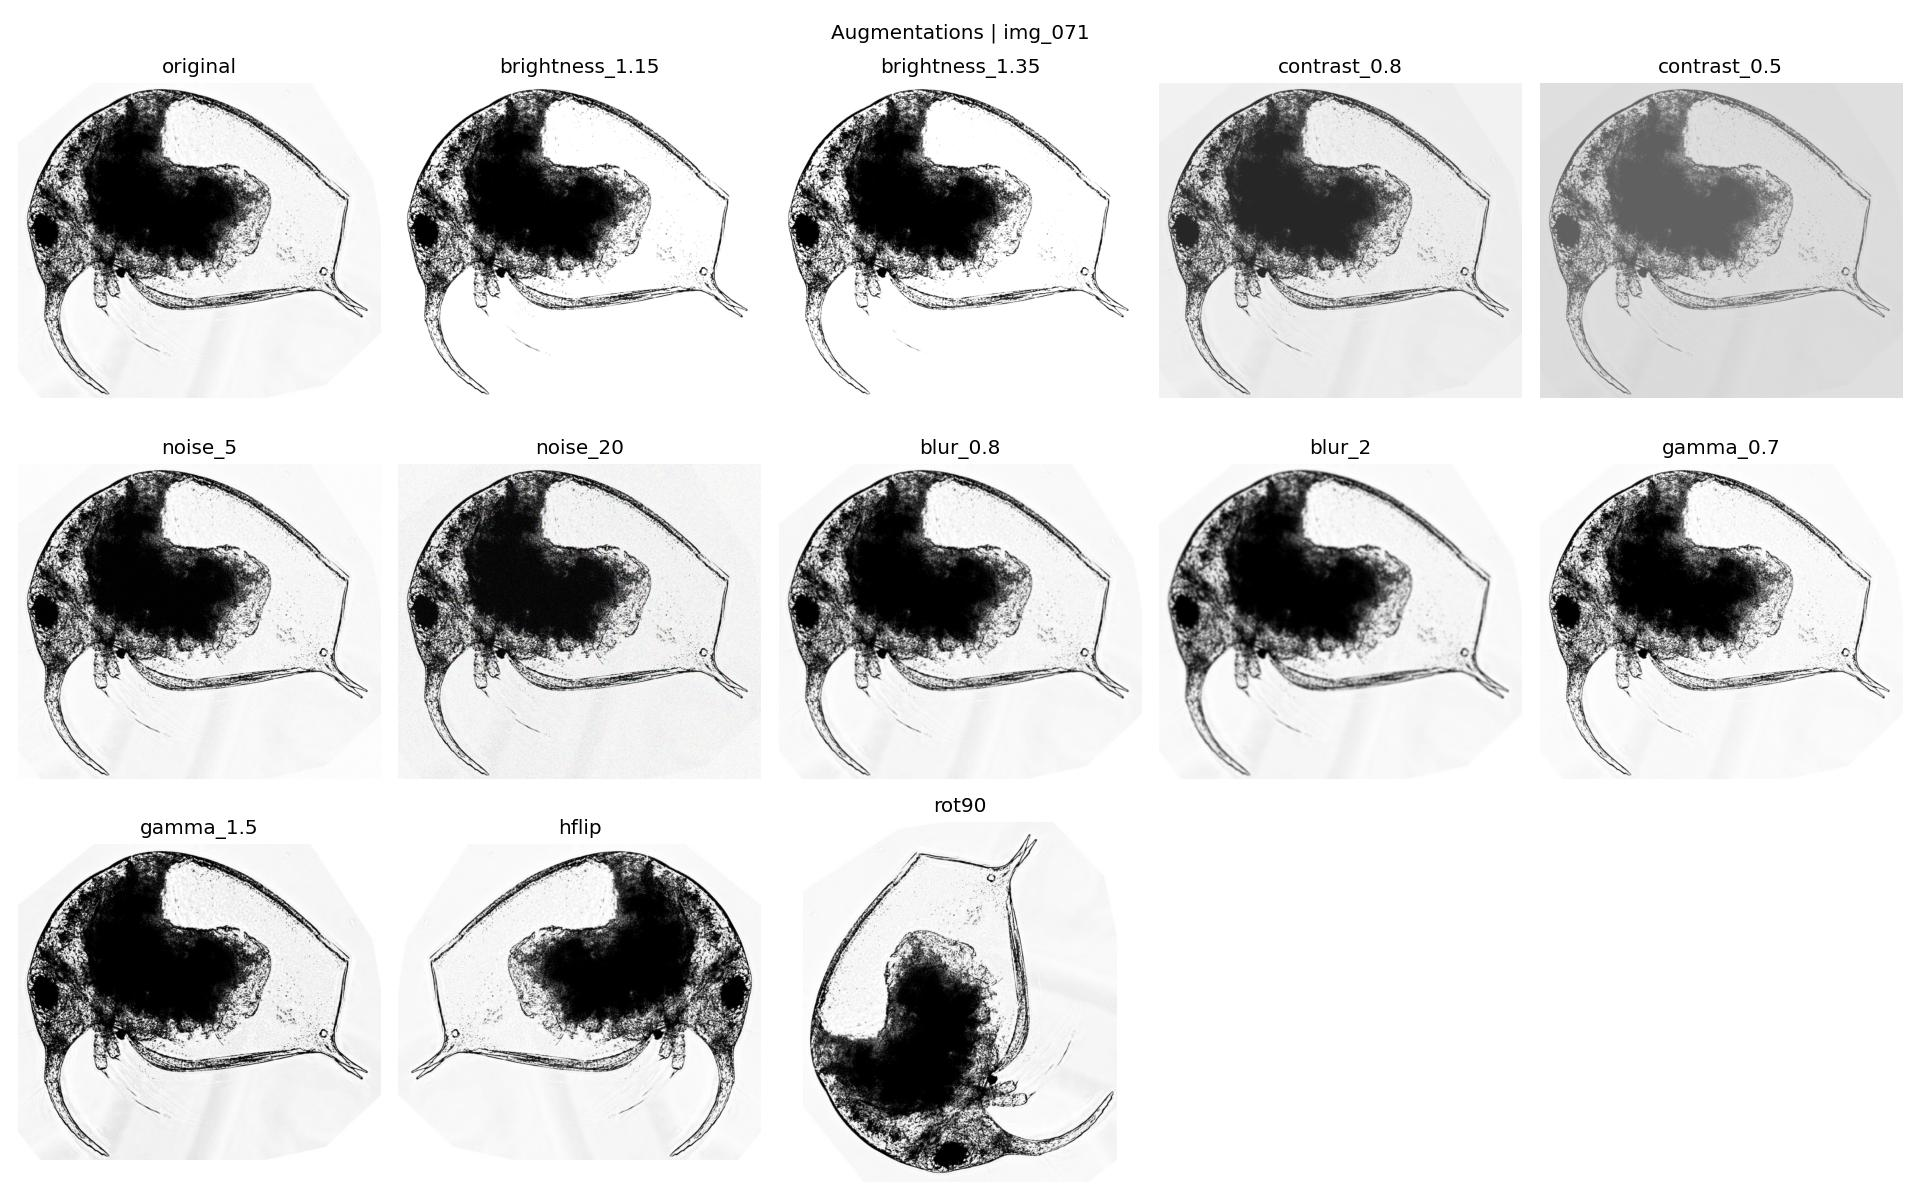

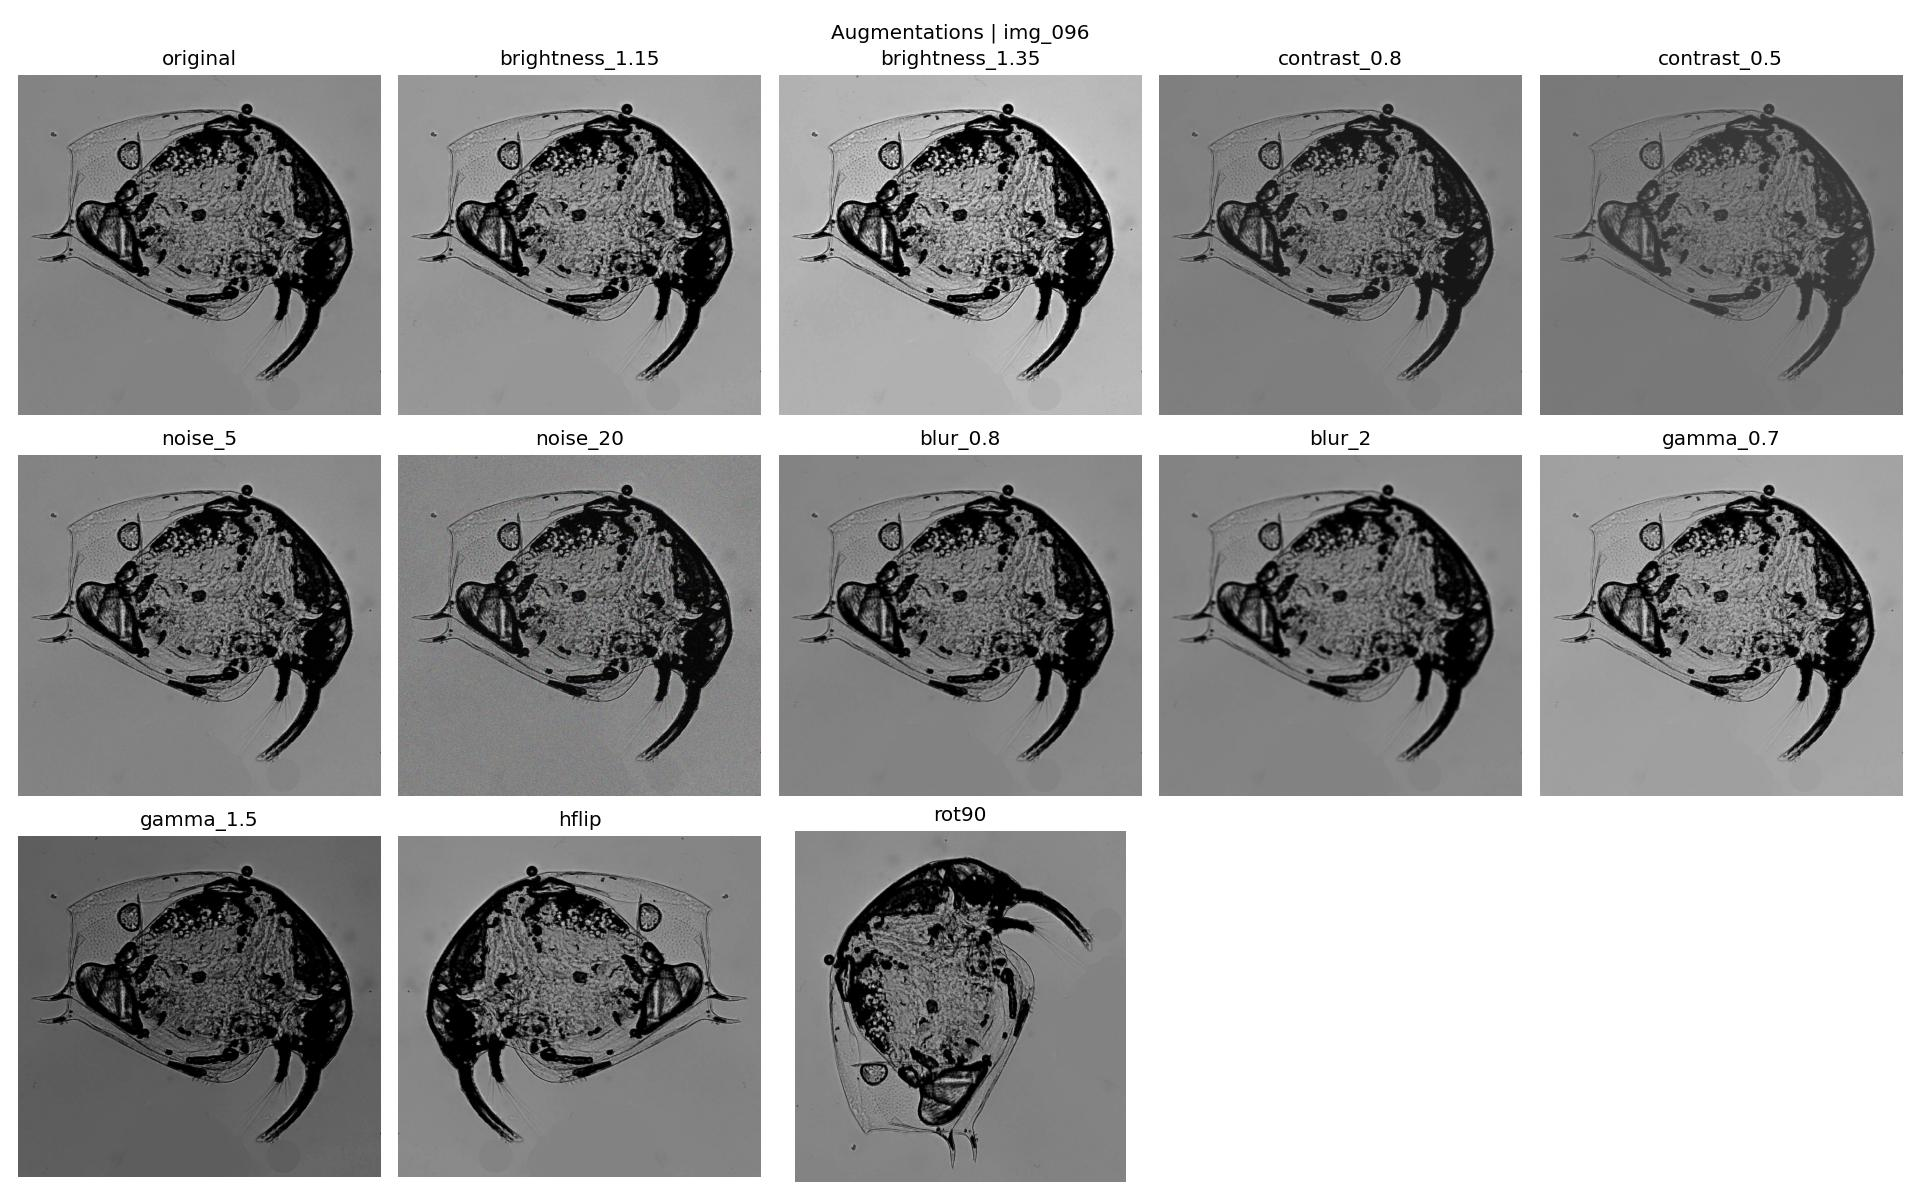

In [7]:
if RUN_EXPERIMENTS: augmentation_gallery(sample)
display(pd.DataFrame([dict(variant=n, parameters=str(p)) for n,p in VARIANTS]))
for path in sorted((RESULTS / 'figures').glob('augmentations_*.jpg')):
    show_figure(path)

## 3. Выбор детекторов и геометрическая устойчивость

**RetinaNet ResNet-50/FPN v2** — одноэтапный anchor-based детектор. На уровнях
пирамиды признаков плотные головы сразу предсказывают классы и уточнения рамок.
Focal Loss при исходном обучении уменьшает вклад многочисленных лёгких
отрицательных примеров. **Faster R-CNN ResNet-50/FPN v2** — двухэтапная модель:
RPN предлагает области, затем RoIAlign и отдельная голова классифицируют и
уточняют предложения. Одинаковое семейство backbone/FPN и одна библиотека
уменьшают различия, не связанные со схемой детекции. Рецепты предобучения
всё же различаются; сравнение не изолирует единственный архитектурный фактор.

Обе модели используют официальные `COCO_V1`, без обучения на этих снимках.
Выбор обусловлен воспроизводимостью, многомасштабными признаками и возможностью
честно сопоставить две схемы. Термин «современные методы» здесь реализован через
актуальные поддерживаемые реализации v2 и SAM 2.1; модели не объявляются SOTA
для микроскопии.

Перед сравнением рамки отражений и поворотов переводятся в координаты исходного
рабочего холста. Сопоставление class-agnostic, взаимно однозначное, IoU≥0.5;
оптимизация сначала максимизирует число допустимых пар, затем сумму IoU.
Считаются доля сохранившихся рамок, IoU совпавших рамок, смещение центров,
нормированное диагональю, и согласованность COCO-меток. При отсутствии исходных
рамок устойчивость **не определена**, а не равна 100%. Эти числа описывают
самосогласованность предсказаний, а не правильность обнаружения организма.

In [8]:
def inverse_boxes(boxes, variant, width, height):
    """Map continuous xyxy edges back to the unaugmented working canvas."""
    b = np.asarray(boxes, dtype=float).reshape(-1,4).copy()
    if variant == 'hflip':
        b = b[:, [2,1,0,3]] * np.array([-1,1,-1,1]) + np.array([width,0,width,0])
    elif variant == 'rot90':
        # CCW: (x,y)->(y,W-x); inverse x=W-y', y=x'.
        b = np.stack([width-b[:,3], b[:,0], width-b[:,1], b[:,2]], axis=1)
    return b

def iou_matrix(a, b):
    a = np.asarray(a, float).reshape(-1,4); b = np.asarray(b, float).reshape(-1,4)
    lo = np.maximum(a[:,None,:2], b[None,:,:2]); hi = np.minimum(a[:,None,2:], b[None,:,2:])
    inter = np.maximum(hi-lo,0).prod(axis=2)
    area_a = np.maximum(a[:,2:]-a[:,:2],0).prod(axis=1)
    area_b = np.maximum(b[:,2:]-b[:,:2],0).prod(axis=1)
    return inter / np.maximum(area_a[:,None]+area_b[None,:]-inter,1e-9)

def match_stability(original, augmented, width, height):
    a = [p for p in original if p['score']>=CONF]; b = [p for p in augmented if p['score']>=CONF]
    if not a or not b:
        return dict(baseline_count=len(a), augmented_count=len(b), matched=0,
                    retained_fraction=(0.0 if a else None), mean_matched_iou=None,
                    center_shift_diagonal=None, label_agreement=None)
    m = iou_matrix([p['box_base'] for p in a], [p['box_base'] for p in b])
    # Lexicographic objective: maximize # eligible matches, then total IoU.
    valid = m >= 0.5
    objective = valid.astype(float) * (min(m.shape)+1) + np.where(valid,m,0)
    ri, ci = linear_sum_assignment(-objective)
    pairs = [(int(i),int(j)) for i,j in zip(ri,ci) if valid[i,j]]
    shifts = [np.linalg.norm((np.array(a[i]['box_base'][:2])+a[i]['box_base'][2:])/2 -
                             (np.array(b[j]['box_base'][:2])+b[j]['box_base'][2:])/2) / np.hypot(width,height) for i,j in pairs]
    return dict(baseline_count=len(a), augmented_count=len(b), matched=len(pairs),
                retained_fraction=len(pairs)/len(a), mean_matched_iou=float(np.mean([m[i,j] for i,j in pairs])) if pairs else None,
                center_shift_diagonal=float(np.mean(shifts)) if pairs else None,
                label_agreement=float(np.mean([a[i]['label_id']==b[j]['label_id'] for i,j in pairs])) if pairs else None)

def draw_detection(im, preds, title, path):
    fig, ax = plt.subplots(figsize=(8,6))
    ax.imshow(im)
    kept = [p for p in preds if p['score']>=CONF]
    for p in kept:
        x1,y1,x2,y2=p['box_aug']
        ax.add_patch(plt.Rectangle((x1,y1),x2-x1,y2-y1,fill=False,color='#f04438',lw=1.5))
        ax.text(x1,y1, f"{p['label']} {p['score']:.2f}", color='white', fontsize=7,
                bbox=dict(facecolor='#a00000',alpha=.8,edgecolor='none'))
    ax.set_title(f'{title} | n={len(kept)} | threshold={CONF}'); ax.axis('off')
    fig.tight_layout(); fig.savefig(path,dpi=110); plt.close(fig)

def sync():
    if DEVICE == 'cuda': torch.cuda.synchronize()

def build_detector(name):
    common = dict(min_size=640, max_size=1024)
    if name == 'retinanet':
        w = RetinaNet_ResNet50_FPN_V2_Weights.COCO_V1
        model = retinanet_resnet50_fpn_v2(weights=w, score_thresh=.05, nms_thresh=.5,
                                         detections_per_img=100, **common)
    elif name == 'fasterrcnn':
        w = FasterRCNN_ResNet50_FPN_V2_Weights.COCO_V1
        model = fasterrcnn_resnet50_fpn_v2(weights=w, box_score_thresh=.05, box_nms_thresh=.5,
                                          box_detections_per_img=100, **common)
    else: raise ValueError(name)
    return model.to(DEVICE).eval(), w

def run_detection(data_dir, sample, model_name):
    model, weights = build_detector(model_name)
    paths = {p.name:p for p in Path(data_dir).rglob('*') if p.is_file()}
    first = resize_working(read_rgb(paths[sample.iloc[0].filename]))
    warm = torch.from_numpy(first).permute(2,0,1).float().div(255).to(DEVICE)
    with torch.inference_mode():
        for _ in range(3): model([warm])
    sync()
    del warm
    raw, runs, stability = [], [], []
    tasks = [(r, name) for r in sample.itertuples() for name,_ in VARIANTS]
    random.Random(SEED).shuffle(tasks)  # Same order for both detectors; avoid intensity/time confounding.
    by_image = {}
    for step, (row, name) in enumerate(tasks):
        im0 = resize_working(read_rgb(paths[row.filename]))
        h,w = im0.shape[:2]
        im = augment(im0, name, row.image_id)
        times=[]
        for repeat in range(REPEATS):
            sync(); start=time.perf_counter()
            tensor=torch.from_numpy(im).permute(2,0,1).float().div(255).to(DEVICE)
            with torch.inference_mode(): output=model([tensor])[0]
            result={k:v.detach().cpu().numpy() for k,v in output.items()}
            sync(); times.append((time.perf_counter()-start)*1000)
        boxes = result['boxes']; back=inverse_boxes(boxes,name,w,h)
        preds=[]
        for idx,(box,base,score,label) in enumerate(zip(boxes,back,result['scores'],result['labels'])):
            p=dict(image_id=row.image_id, model=model_name, variant=name, detection_id=idx,
                   score=float(score), label_id=int(label), label=weights.meta['categories'][int(label)],
                   box_aug=box.tolist(),box_base=base.tolist(),
                   box_original=(base*np.array([row.width/w,row.height/h,row.width/w,row.height/h])).tolist())
            preds.append(p); raw.append(p)
        by_image[(row.image_id,name)]=preds
        runs.append(dict(image_id=row.image_id,model=model_name,variant=name,group='original' if name=='original' else 'augmented',
                         width=im.shape[1],height=im.shape[0],n_detections=sum(p['score']>=CONF for p in preds),
                         inference_ms=float(np.median(times)),inference_min_ms=min(times),inference_max_ms=max(times),
                         time_rep1_ms=times[0],time_rep2_ms=times[1],time_rep3_ms=times[2],
                         n_at_010=sum(p['score']>=.1 for p in preds),n_at_050=sum(p['score']>=.5 for p in preds)))
        draw_detection(im,preds,f'{model_name} | {row.image_id} | {name}',
                       RESULTS/'detections'/f'{model_name}_{row.image_id}_{name}.jpg')
        if step%12==0: print(f'{model_name}: {step+1}/{len(tasks)}',flush=True)
        # Incremental checkpoint, so an interrupted run still has verifiable completed records.
        if step%24==0:
            pd.DataFrame(runs).to_csv(RESULTS/'tables'/f'runs_{model_name}.csv',index=False)
    for row in sample.itertuples():
        im=resize_working(read_rgb(paths[row.filename]));h,w=im.shape[:2]
        for name,_ in VARIANTS[1:]:
            stability.append(dict(image_id=row.image_id,model=model_name,variant=name,
                                  **match_stability(by_image[(row.image_id,'original')],by_image[(row.image_id,name)],w,h)))
    dump(raw,RESULTS/f'predictions_{model_name}.json')
    pd.DataFrame(runs).to_csv(RESULTS/'tables'/f'runs_{model_name}.csv',index=False)
    pd.DataFrame(stability).to_csv(RESULTS/'tables'/f'stability_{model_name}.csv',index=False)
    dump(dict(model=model_name,weights=str(weights),url=weights.url,
              parameters=sum(p.numel() for p in model.parameters()),device=DEVICE,
              min_size=640,max_size=1024,internal_score_threshold=.05,report_threshold=CONF,nms=.5,
              precision='float32',batch_size=1,warmup=3,repeats=REPEATS),RESULTS/f'model_{model_name}.json')
    del model, output, tensor
    gc.collect()
    if DEVICE=='cuda':torch.cuda.empty_cache()

def summarize_detection():
    runs=pd.concat([pd.read_csv(RESULTS/'tables'/f'runs_{n}.csv') for n in ['retinanet','fasterrcnn']])
    stability=pd.concat([pd.read_csv(RESULTS/'tables'/f'stability_{n}.csv') for n in ['retinanet','fasterrcnn']])
    summary=runs.groupby(['model','group']).agg(images=('image_id','nunique'),variants=('variant','nunique'),
              image_variant_pairs=('image_id','size'),total_detections=('n_detections','sum'),
              detections_per_image=('n_detections','mean'),zero_detection_fraction=('n_detections',lambda x:float((x==0).mean())),
              median_ms=('inference_ms','median'),p90_ms=('inference_ms',lambda x:x.quantile(.9)),mean_ms=('inference_ms','mean')).reset_index()
    summary.to_csv(RESULTS/'tables/detection_four_groups.csv',index=False)
    byvar=runs.groupby(['model','variant']).agg(detections_per_image=('n_detections','mean'),median_ms=('inference_ms','median')).reset_index()
    stabvar=stability.groupby(['model','variant']).agg(retained_fraction=('retained_fraction','mean'),
               mean_matched_iou=('mean_matched_iou','mean'),mean_center_shift=('center_shift_diagonal','mean'),
               matched=('matched','sum'),baseline_boxes=('baseline_count','sum')).reset_index()
    byvar.merge(stabvar,on=['model','variant'],how='left').to_csv(RESULTS/'tables/detection_by_augmentation.csv',index=False)
    runs.to_csv(RESULTS/'tables/detection_runs.csv',index=False)
    stability.to_csv(RESULTS/'tables/detection_stability.csv',index=False)
    fig,axes=plt.subplots(1,2,figsize=(14,4))
    for model in ['retinanet','fasterrcnn']:
        s=byvar[byvar.model==model].set_index('variant').reindex([n for n,_ in VARIANTS])
        axes[0].plot(range(len(s)),s.detections_per_image,marker='o',label=model)
        t=stabvar[stabvar.model==model].set_index('variant').reindex([n for n,_ in VARIANTS[1:]])
        axes[1].plot(range(len(t)),t.retained_fraction,marker='o',label=model)
    for ax,names,ylabel in [(axes[0],[n for n,_ in VARIANTS],'Mean detections / image'),(axes[1],[n for n,_ in VARIANTS[1:]],'Retained baseline boxes (IoU >= 0.5)')]:
        ax.set_xticks(range(len(names)),names,rotation=60,ha='right');ax.set_ylabel(ylabel);ax.legend();ax.grid(alpha=.2)
    fig.tight_layout();fig.savefig(RESULTS/'figures/detection_comparison.png',dpi=150);plt.close(fig)
    return summary

def environment_record():
    import importlib.metadata as md
    names=['torch','torchvision','numpy','pandas','opencv-python','matplotlib','scipy','Pillow','SAM-2','hydra-core','nbformat','nbclient']
    packages={n:md.version(n) for n in names if md.packages_distributions()}
    record=dict(seed=SEED,python=platform.python_version(),platform=platform.platform(),device=DEVICE,
                gpu=torch.cuda.get_device_name(0) if DEVICE=='cuda' else None,cuda=torch.version.cuda,
                cpu_threads=torch.get_num_threads(),opencv_threads=cv2.getNumThreads(),packages=packages,
                timing='Synchronized wall clock; CPU uint8 -> float tensor, H2D, model preprocessing, forward, NMS, D2H. Excludes image IO, augmentations, figures and model loading.',
                selection='24 contrast-stratified images: 12 multi-object fields, 6 Bosmina series, 6 other specimens; no prediction-based selection.',
                sam2_commit='2b90b9f5ceec907a1c18123530e92e794ad901a4')
    dump(record,RESULTS/'environment.json')

,model,group,images,variants,image_variant_pairs,total_detections,detections_per_image,zero_detection_fraction,median_ms,p90_ms,mean_ms
0,fasterrcnn,augmented,24,12,288,1052,3.653,0.014,111.934,115.504,111.449
1,fasterrcnn,original,24,1,24,96,4.000,0.000,112.105,117.292,111.950
2,retinanet,augmented,24,12,288,841,2.920,0.080,59.297,62.795,58.709
3,retinanet,original,24,1,24,72,3.000,0.042,59.326,61.721,58.608


,model,variant,detections_per_image,median_ms,retained_fraction,mean_matched_iou,mean_center_shift,matched,baseline_boxes
0,fasterrcnn,blur_0.8,3.500,112.013,0.800,0.935,0.007,73.0,96.0
1,fasterrcnn,blur_2,2.208,110.573,0.537,0.923,0.013,41.0,96.0
2,fasterrcnn,brightness_1.15,3.625,112.429,0.813,0.948,0.005,74.0,96.0
3,fasterrcnn,brightness_1.35,3.583,111.422,0.671,0.923,0.010,58.0,96.0
4,fasterrcnn,contrast_0.5,2.458,111.337,0.521,0.933,0.008,44.0,96.0
5,fasterrcnn,contrast_0.8,3.458,112.592,0.726,0.963,0.005,69.0,96.0
6,fasterrcnn,gamma_0.7,3.417,112.005,0.785,0.944,0.005,71.0,96.0
7,fasterrcnn,gamma_1.5,4.542,112.488,0.895,0.941,0.007,83.0,96.0
8,fasterrcnn,hflip,3.958,112.783,0.760,0.912,0.010,72.0,96.0
9,fasterrcnn,noise_20,3.708,112.139,0.515,0.888,0.014,53.0,96.0


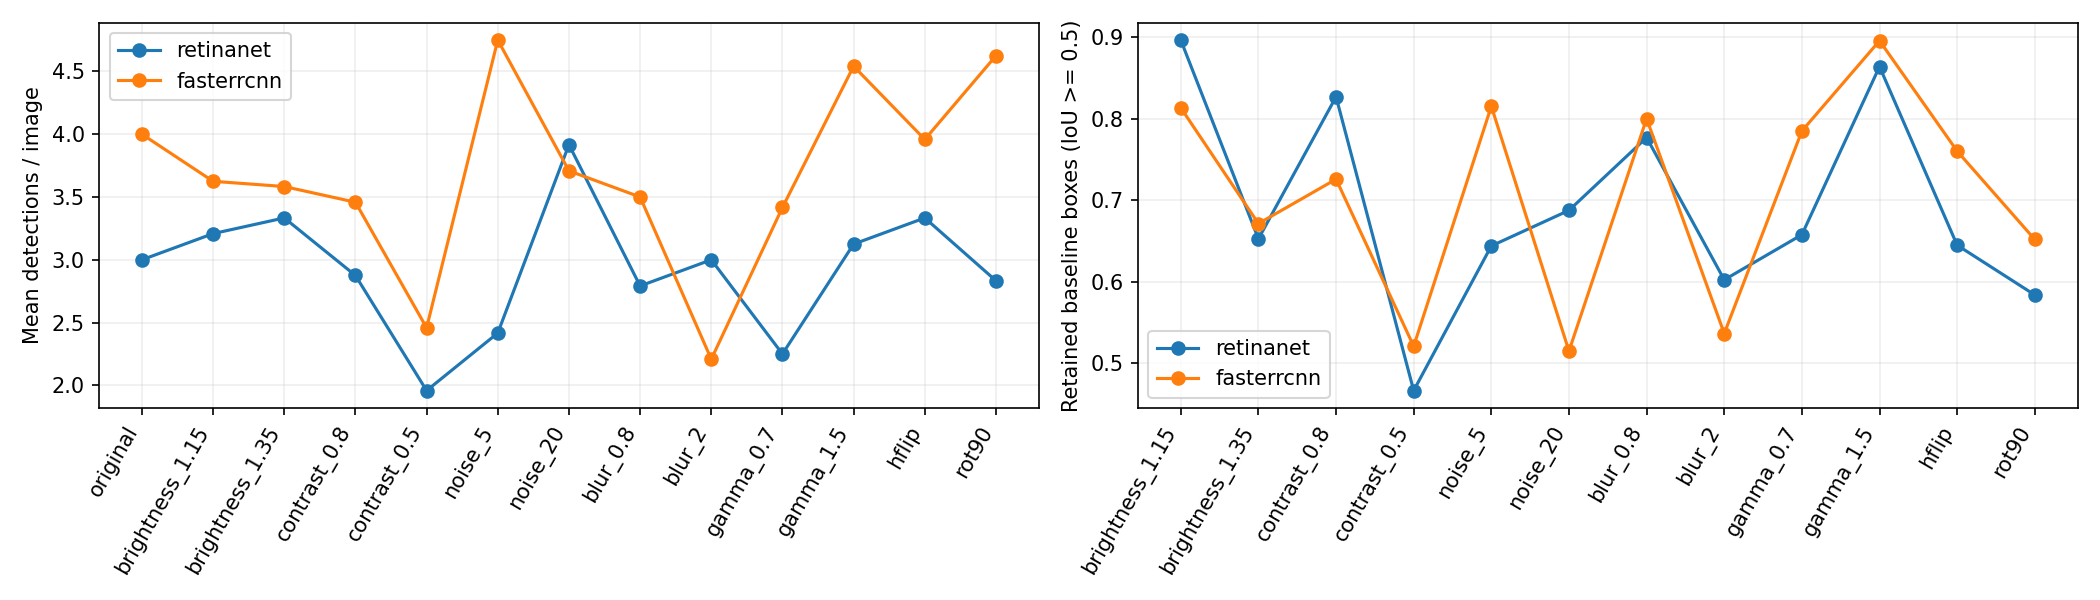

In [9]:
if RUN_EXPERIMENTS:
    environment_record()
    for model_name in ['retinanet', 'fasterrcnn']:
        run_detection(DATA_DIR, sample, model_name)
    summarize_detection()
display(pd.read_csv(RESULTS / 'tables/detection_four_groups.csv').round(3))
display(pd.read_csv(RESULTS / 'tables/detection_by_augmentation.csv').round(3))
show_figure(RESULTS / 'figures/detection_comparison.png')

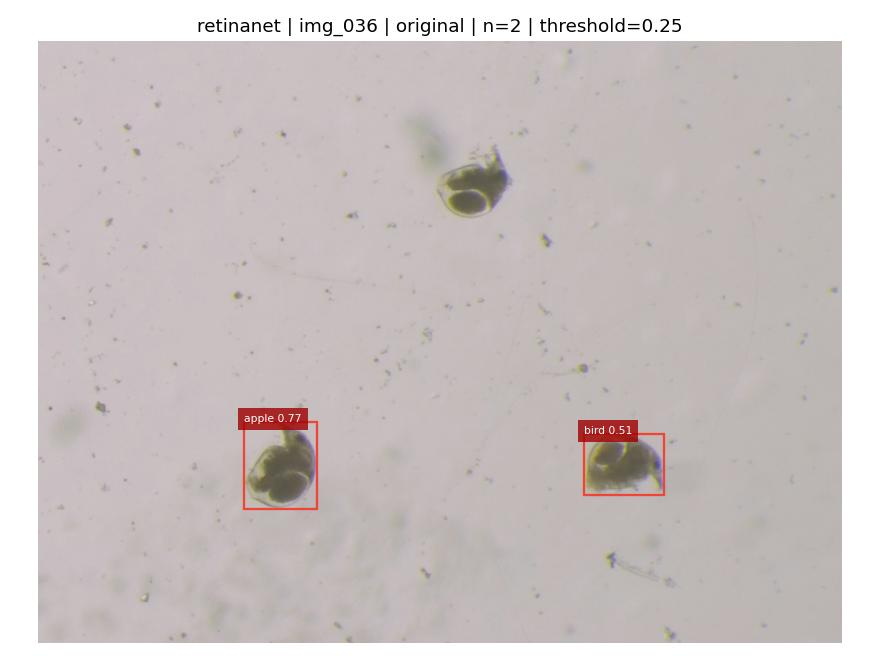

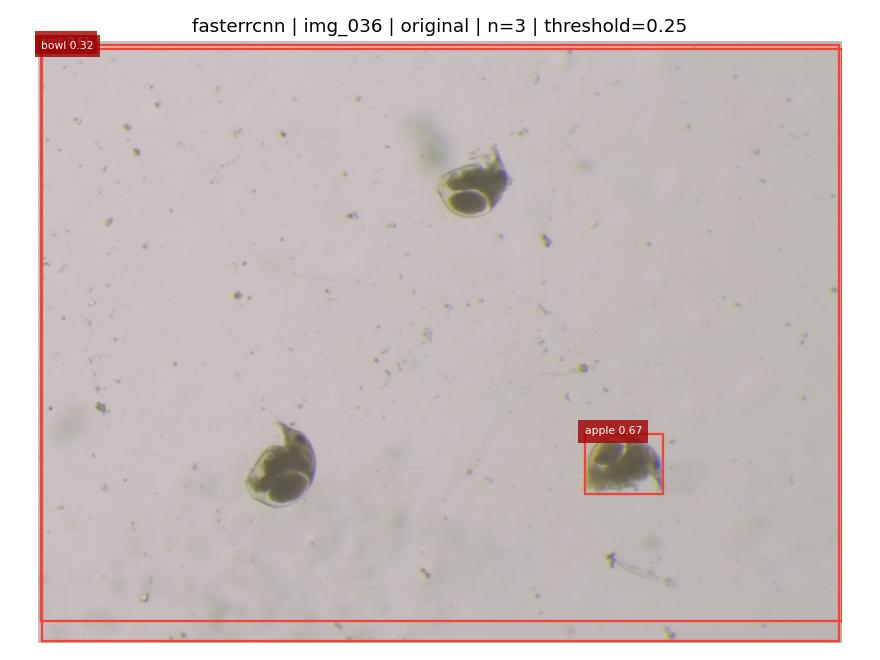

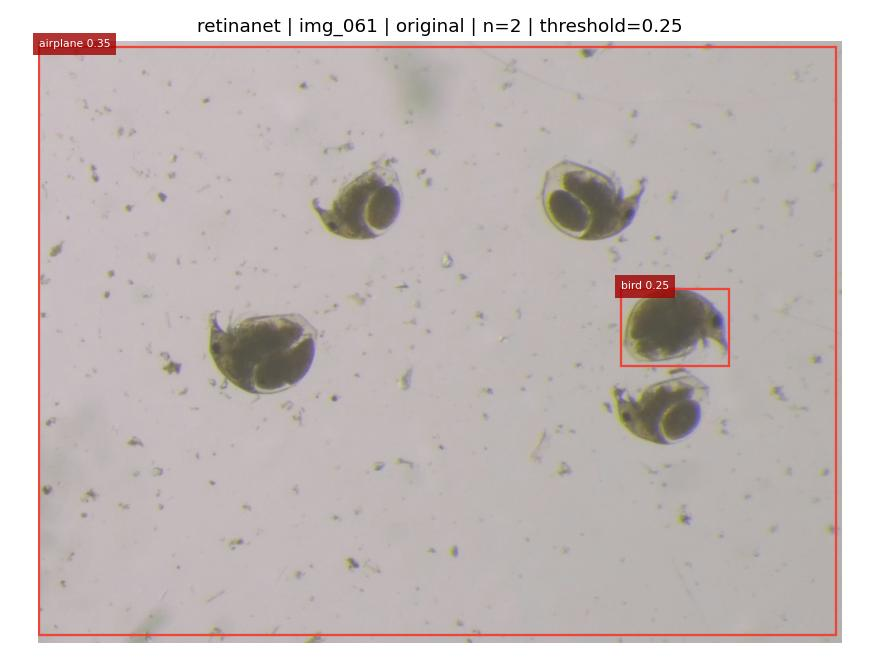

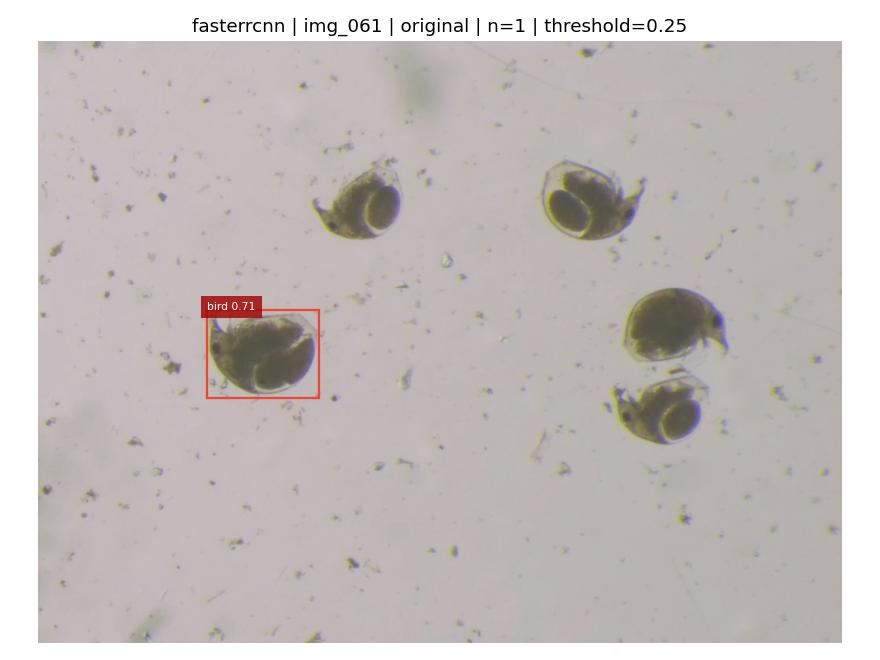

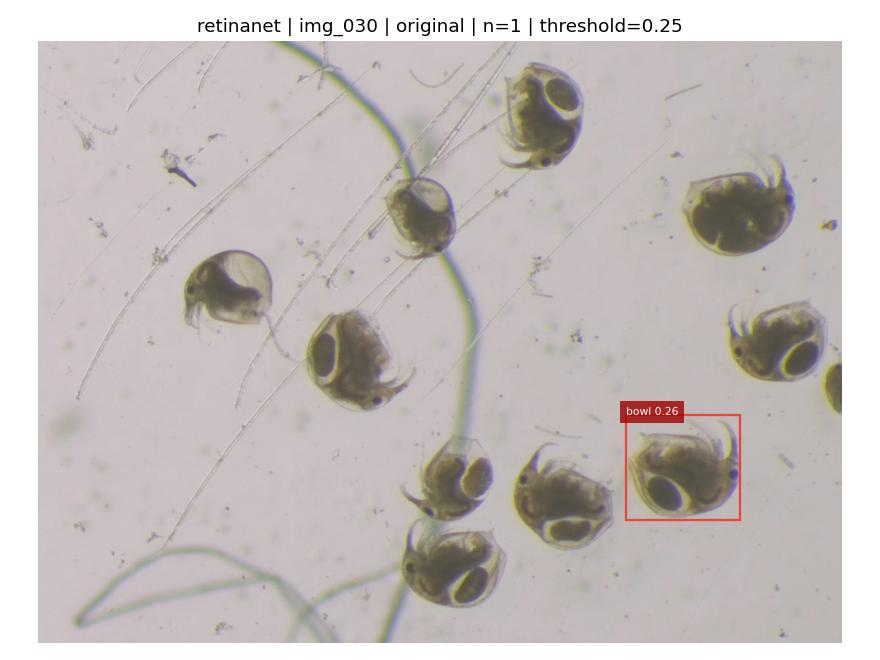

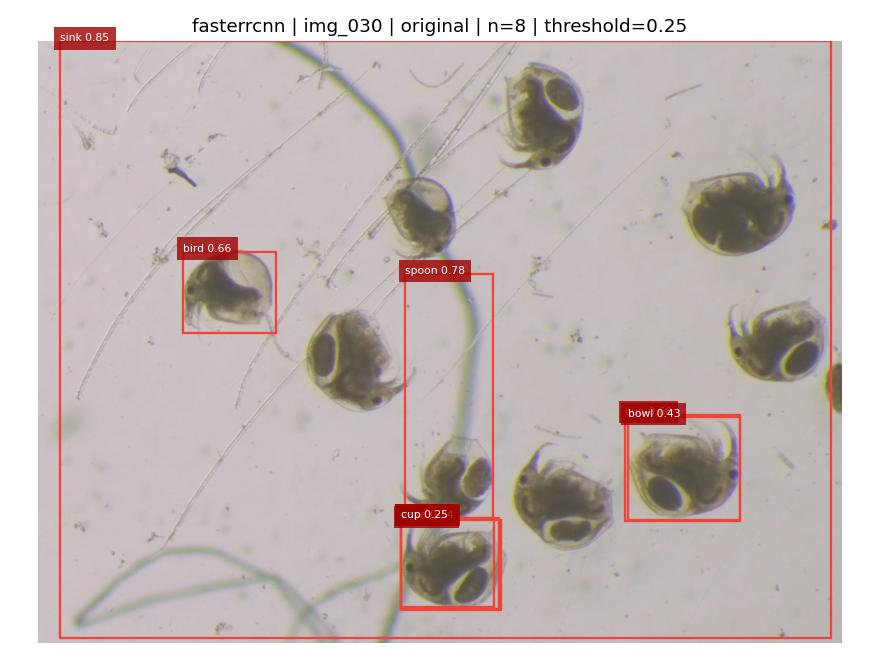

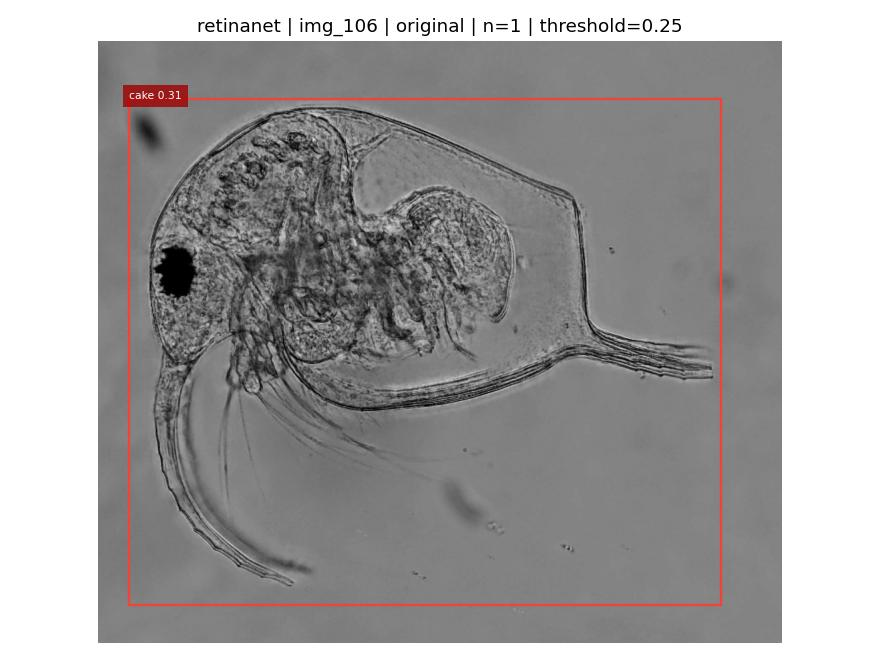

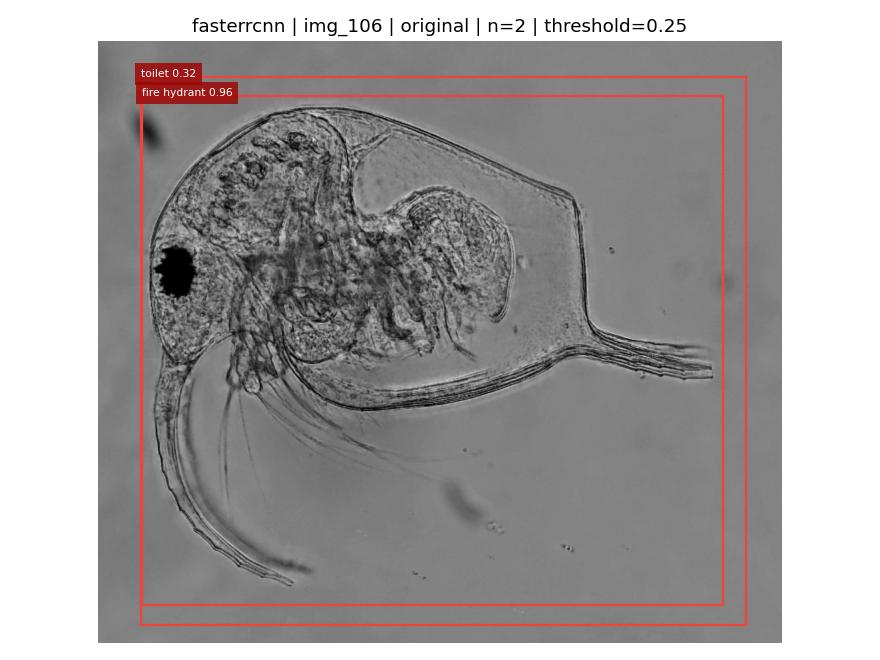

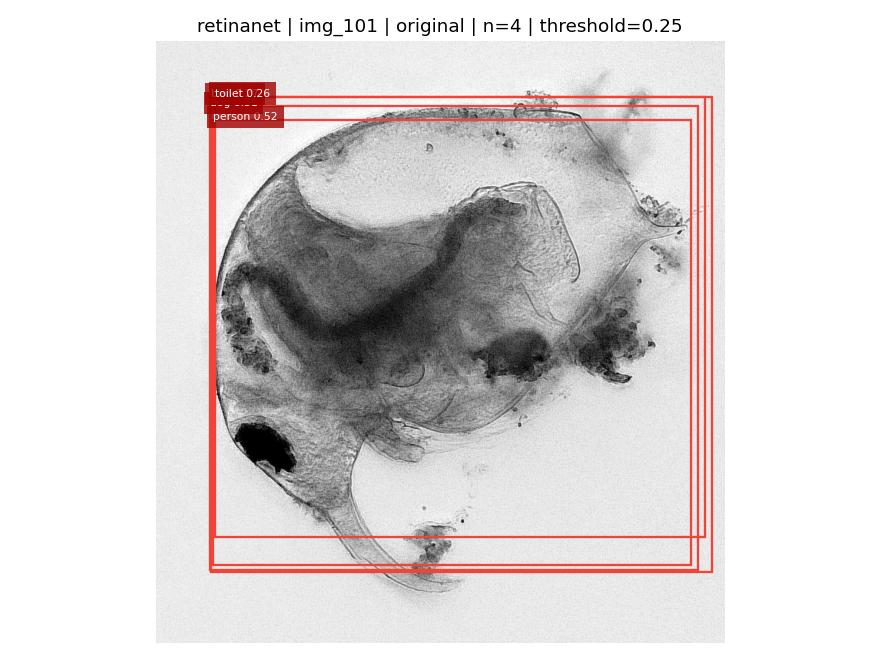

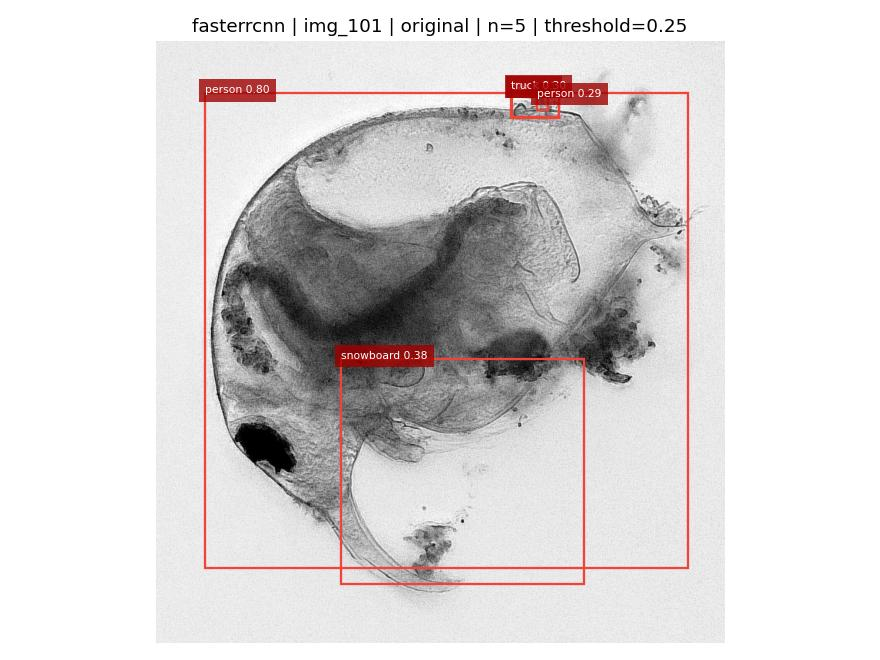

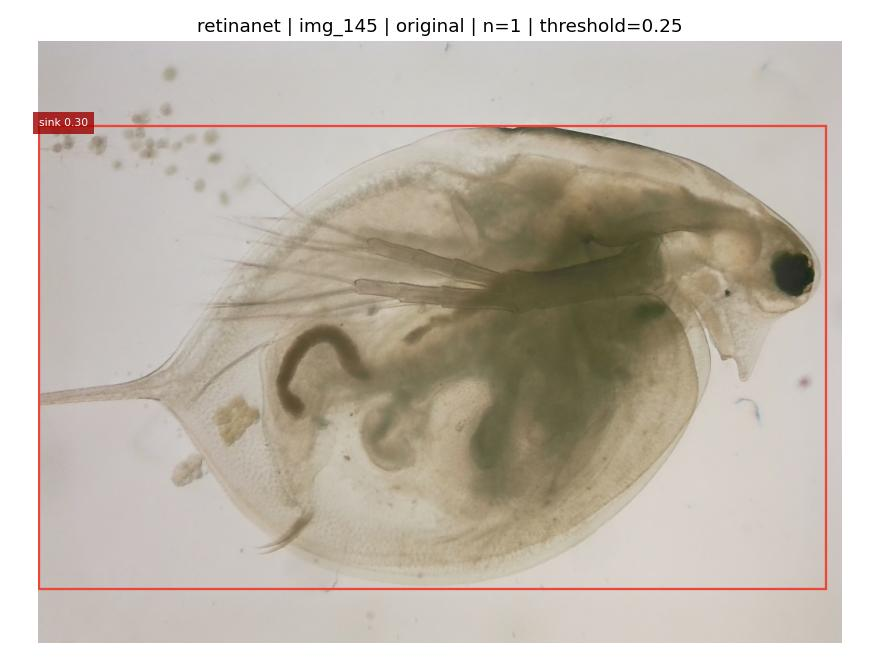

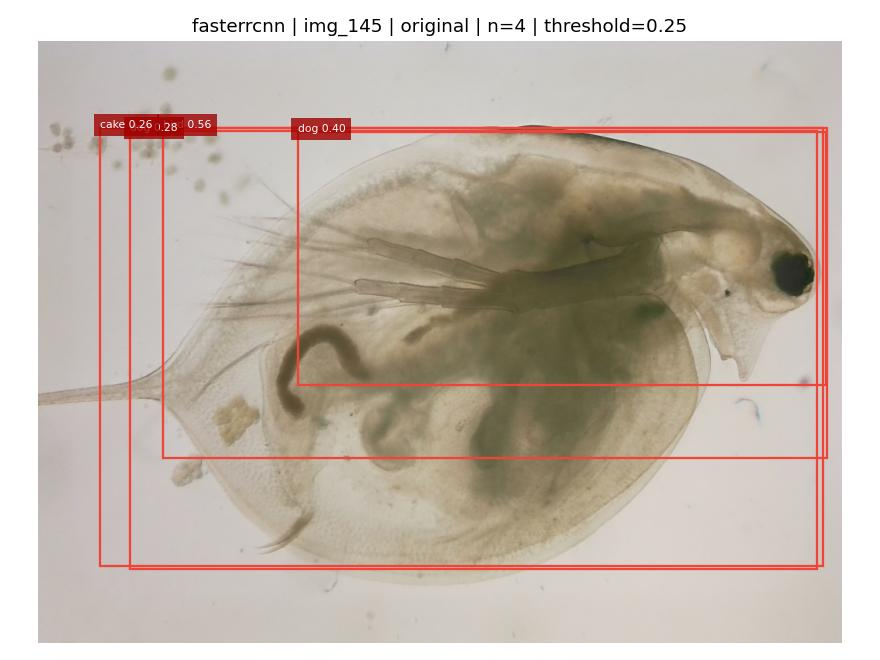

In [10]:
# Show the same six baseline images for both detectors, including failures.
for image_id in sample.image_id.iloc[::4]:
    for model in ['retinanet','fasterrcnn']:
        show_figure(RESULTS / 'detections' / f'{model}_{image_id}_original.jpg', width=750)

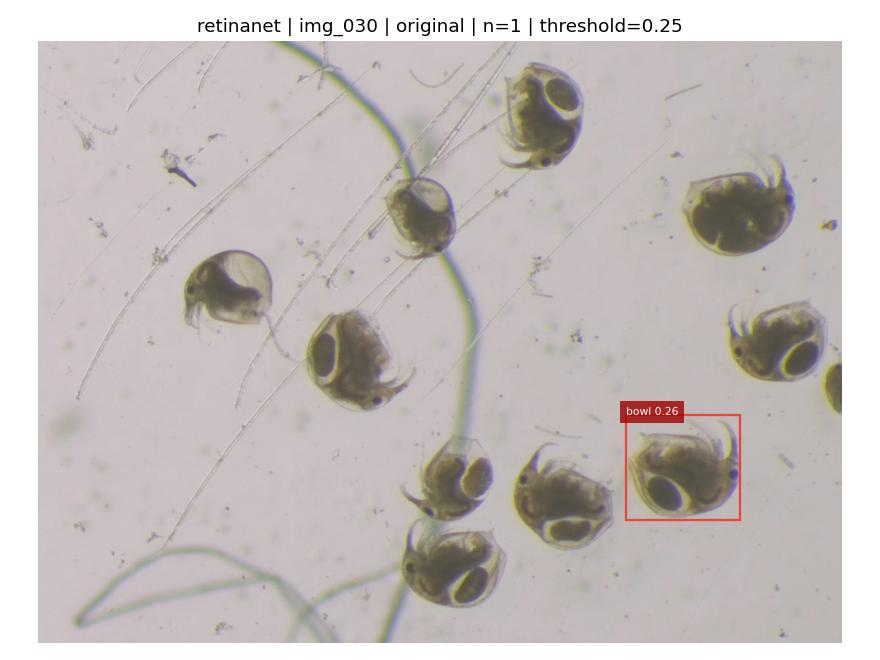

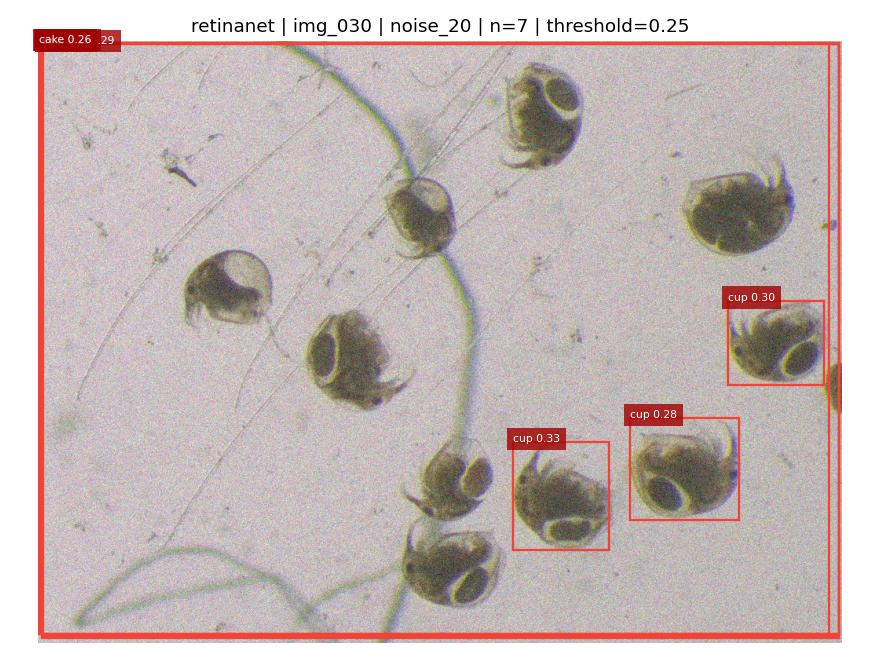

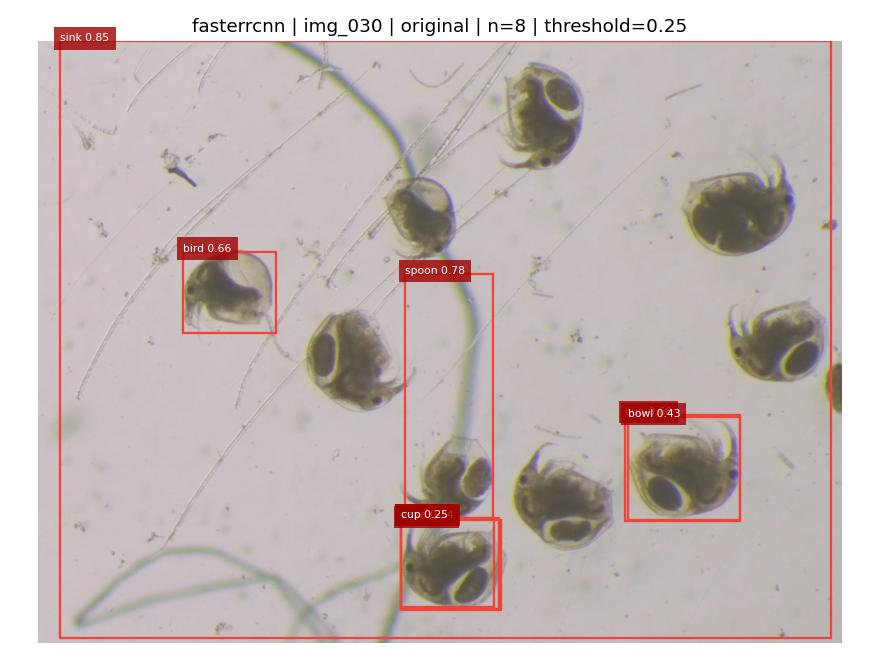

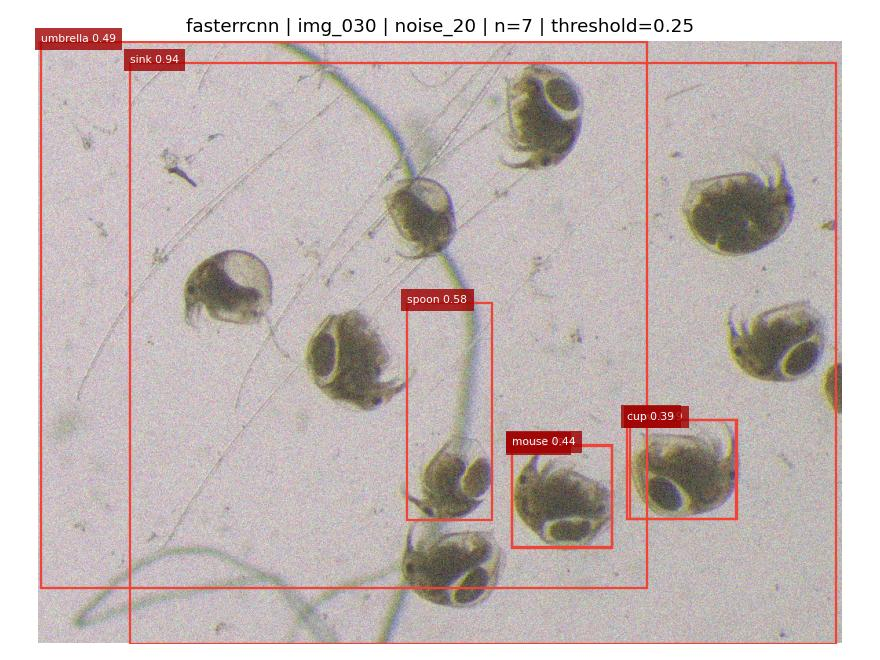

In [11]:
# A noise stress test: more detections can include full-frame false regions.
for model in ['retinanet','fasterrcnn']:
    for variant in ['original','noise_20']:
        show_figure(RESULTS / 'detections' / f'{model}_img_030_{variant}.jpg', width=750)

## 4. Сегментация с одинаковыми box prompts

GrabCut моделирует распределения цветов переднего плана/фона и уточняет разрез
графа за пять итераций. Всё вне заданного прямоугольника считается фоном, поэтому
слишком тесная рамка необратимо обрезает выступающие структуры.
SAM 2.1 Hiera Tiny использует предобученный кодировщик изображения и декодер
масок с пространственной подсказкой. Используется оригинальная реализация Meta,
`multimask_output=False`, без дообучения. Расширение для CUDA-постобработки
отключено; удаление дыр и мелких компонент не применяется.

Основная демонстрационная схема: каждый второй снимок фиксированной выборки,
не более двух рамок Faster R-CNN с наибольшим score≥0.25. Выбор рамок смещён к
наиболее уверенным предсказаниям и не является оценкой всех объектов. Сам выбор
Faster R-CNN для этой демонстрации не доказывает его превосходства; итоговый
вывод опирается на таблицы и просмотр ошибок.

Оба метода получают **одни и те же целочисленные рамки**; оставляется граница
фона в один пиксель для GrabCut. Файл `segmentation_prompts.json` хранит и
запрошенную, и фактическую рамку. При использовании ручных рамок они помечены
`manual_demo`, имеют причину и анализируются отдельно. Для первых двух
автоматических рамок дополнительно исследуется сужение/расширение на 25%.
Два дополнительных случая `overlap_case` выбраны после визуального просмотра
на `img_041`, чтобы проверить объединение/разделение касающихся организмов.
Их статистика отделена от 22 основных рамок и четырёх вариантов их размера.
Всего сохранено 28 пар масок, без ручных подсказок.

Маски сохраняются отдельно для каждого экземпляра, в рабочем и исходном
разрешении. Последнее получается nearest-neighbor масштабированием и не
восстанавливает потерянные тонкие детали. Маски разных объектов могут
пересекаться. Наличие нескольких рамок не обеспечивает разделения перекрытий.

Время SAM включает кодирование всего изображения **для каждой рамки**, декодер
и получение маски на CPU; отдельно сохранены время encoder/decoder.
На практике embedding можно переиспользовать для нескольких рамок одного
снимка. GrabCut работает на CPU, SAM — на GPU; это сравнение выбранных
реализаций на данном оборудовании, а не чистой вычислительной сложности.

In [12]:
def clip_box(box, w, h):
    x1,y1,x2,y2=box
    # Keep at least a 1 px known-background border for GrabCut, then give EXACTLY this box to SAM.
    x1,y1=max(1,int(np.floor(x1))),max(1,int(np.floor(y1)))
    x2,y2=min(w-1,int(np.ceil(x2))),min(h-1,int(np.ceil(y2)))
    if x2-x1<3 or y2-y1<3: raise ValueError('Degenerate prompt')
    return [x1,y1,x2,y2]

def make_prompts(sample, manual_path=None):
    predictions=json.loads((RESULTS/'predictions_fasterrcnn.json').read_text(encoding='utf-8'))
    prompts=[]
    # Predeclared subset: every second sample; at most two highest-confidence baseline boxes.
    for row in sample.iloc[::2].itertuples():
        preds=[p for p in predictions if p['image_id']==row.image_id and p['variant']=='original' and p['score']>=CONF]
        for p in sorted(preds,key=lambda p:-p['score'])[:2]:
            prompts.append(dict(image_id=row.image_id,source='fasterrcnn',box=p['box_base'],
                                detection_id=p['detection_id'],confidence=p['score'],coco_label=p['label'],variant='base'))
    if manual_path and Path(manual_path).exists():
        manual=json.loads(Path(manual_path).read_text(encoding='utf-8'))
        for p in manual:
            assert p.get('source')=='manual_demo' and p.get('reason'), 'Manual prompts must be explicitly identified.'
        prompts.extend(manual)
    # Sensitivity to imprecise prompts: not a separate model-quality benchmark.
    for p in prompts[:2]:
        b=np.array(p['box']);center=(b[:2]+b[2:])/2;half=(b[2:]-b[:2])/2
        for name,factor in [('tight_0.75',.75),('loose_1.25',1.25)]:
            q={**p,'variant':name,'box':np.r_[center-half*factor,center+half*factor].tolist()}
            prompts.append(q)
    # Post-hoc qualitative overlap cases, kept separate from the predeclared base benchmark.
    # RetinaNet covers the touching pair; Faster R-CNN localizes its left member.
    for model,det_id in [('retinanet',0),('fasterrcnn',4)]:
        candidates=json.loads((RESULTS/f'predictions_{model}.json').read_text(encoding='utf-8'))
        matches=[p for p in candidates if p['image_id']=='img_041' and p['variant']=='original' and p['detection_id']==det_id and p['score']>=CONF]
        if len(matches)==1:
            p=matches[0]
            prompts.append(dict(image_id=p['image_id'],source=model,box=p['box_base'],detection_id=det_id,
                                confidence=p['score'],coco_label=p['label'],variant='overlap_case',
                                selection_note='Post-hoc qualitative case chosen after visual inspection of touching organisms; not part of the base timing summary.'))
    for i,p in enumerate(prompts): p['prompt_id']=f'prompt_{i:03d}'
    return prompts

def grabcut(im, box):
    x1,y1,x2,y2=box
    mask=np.zeros(im.shape[:2],np.uint8)
    bg=np.zeros((1,65),np.float64);fg=np.zeros((1,65),np.float64)
    cv2.setRNGSeed(SEED)
    cv2.grabCut(im,mask,(x1,y1,x2-x1,y2-y1),bg,fg,5,cv2.GC_INIT_WITH_RECT)
    return (mask==cv2.GC_FGD)|(mask==cv2.GC_PR_FGD)

def overlay(im, mask, color=(0,195,135)):
    result=im.copy()
    result[mask]=(result[mask].astype(float)*.55+np.array(color)*.45).astype(np.uint8)
    contours,_=cv2.findContours(mask.astype(np.uint8),cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(result,contours,-1,(255,60,30),1)
    return result

def render_comparison(im, box, masks, timings, prompt, agreement, path):
    a,b=masks['GrabCut'],masks['SAM2']
    fig,axes=plt.subplots(2,3,figsize=(13,8),layout='constrained')
    views=[(im,'Original'),(im,'Identical box prompt'),(a,'GrabCut binary mask'),
           (b,'SAM 2.1 binary mask'),(overlay(im,a),f"GrabCut | {timings['GrabCut']:.0f} ms"),
           (overlay(im,b),f"SAM 2.1 | {timings['SAM2']:.0f} ms")]
    for ax,(view,title) in zip(axes.ravel(),views):
        ax.imshow(view,cmap='gray' if view.ndim==2 else None,vmin=0,vmax=1 if view.ndim==2 else 255)
        ax.set_title(title,fontsize=12,pad=9);ax.axis('off')
    x1,y1,x2,y2=box
    axes[0,1].add_patch(plt.Rectangle((x1,y1),x2-x1,y2-y1,fill=False,color='red',lw=2))
    agreement_text=f'{agreement:.3f}' if agreement is not None else 'NA'
    fig.suptitle(f"{prompt['prompt_id']} | {prompt['image_id']} | {prompt['source']} | {prompt['variant']} | agreement IoU={agreement_text}",fontsize=13)
    fig.savefig(path,dpi=125);plt.close(fig)

def segment(data_dir, checkpoint, manual_path=None, resume=False):
    from sam2.build_sam import build_sam2
    from sam2.sam2_image_predictor import SAM2ImagePredictor
    sample=pd.read_csv(RESULTS/'tables/sample_manifest.csv')
    prompts=make_prompts(sample,manual_path)
    if not prompts:raise RuntimeError('No detector prompts; explicitly supply manual_demo boxes.')
    paths={p.name:p for p in Path(data_dir).rglob('*') if p.is_file()}
    model=build_sam2('configs/sam2.1/sam2.1_hiera_t.yaml',str(checkpoint),device=DEVICE,apply_postprocessing=False)
    predictor=SAM2ImagePredictor(model,max_hole_area=0,max_sprinkle_area=0)
    rows=[];used=[];previous={}
    if resume and (RESULTS/'tables/segmentation_runs.csv').exists():
        rows=pd.read_csv(RESULTS/'tables/segmentation_runs.csv').to_dict('records')
        previous={p['prompt_id']:p for p in json.loads((RESULTS/'segmentation_prompts.json').read_text())}
    # Full image encoder and decoder warmup; not included in measurements.
    first=resize_working(read_rgb(paths[sample.iloc[0].filename]))
    with torch.inference_mode():
        predictor.set_image(first)
        predictor.predict(box=np.array([1,1,first.shape[1]-1,first.shape[0]-1]),multimask_output=False)
    for i,p in enumerate(prompts):
        row=sample[sample.image_id==p['image_id']].iloc[0]
        original=read_rgb(paths[row.filename]);im=resize_working(original);h,w=im.shape[:2]
        box=clip_box(p['box'],w,h);p={**p,'box_requested':p['box'],'box':box,'working_width':w,'working_height':h}
        used.append(p)
        existing=[r for r in rows if r['prompt_id']==p['prompt_id']]
        if existing:
            assert len(existing)==2 and {r['method'] for r in existing}=={'GrabCut','SAM2'}
            old=previous[p['prompt_id']]
            assert all(old[k]==p[k] for k in ['image_id','source','variant','box']), 'Cannot resume with changed prompts'
            continue
        masks={};timings={};errors={}
        for method in ['GrabCut','SAM2']:
            ts=[];encoder_times=[];decoder_times=[];quality=None
            for repeat in range(3):
                sync();start=time.perf_counter()
                try:
                    if method=='GrabCut': mask=grabcut(im,box)
                    else:
                        with torch.inference_mode():
                            # Recompute embedding per prompt to make per-instance standalone latency explicit.
                            predictor.set_image(im);sync();encoded=time.perf_counter()
                            out,quality,_=predictor.predict(box=np.array(box),multimask_output=False)
                            sync();decoded=time.perf_counter()
                        mask=out[0].astype(bool)
                        encoder_times.append((encoded-start)*1000);decoder_times.append((decoded-encoded)*1000)
                    sync();ts.append((time.perf_counter()-start)*1000)
                except (cv2.error,RuntimeError) as e:
                    errors[method]=str(e);mask=np.zeros((h,w),bool);ts.append((time.perf_counter()-start)*1000)
                    break
            masks[method]=mask
            timings[method]=float(np.median(ts))
            mask_name=f"{p['prompt_id']}_{method.lower()}"
            Image.fromarray(mask.astype(np.uint8)*255).save(RESULTS/'masks'/f'{mask_name}.png')
            native=cv2.resize(mask.astype(np.uint8),(original.shape[1],original.shape[0]),interpolation=cv2.INTER_NEAREST)
            Image.fromarray(native*255).save(RESULTS/'masks'/f'{mask_name}_native.png')
            Image.fromarray(overlay(im,mask)).save(RESULTS/'segmentation'/f'{mask_name}_overlay.jpg',quality=90)
            x1,y1,x2,y2=box
            inside=np.zeros_like(mask);inside[y1:y2,x1:x2]=True
            rows.append(dict(prompt_id=p['prompt_id'],image_id=p['image_id'],source=p['source'],prompt_variant=p['variant'],
                             method=method,median_ms=timings[method],min_ms=min(ts),max_ms=max(ts),repeats=len(ts),
                             encoder_ms=float(np.median(encoder_times)) if encoder_times else None,
                             decoder_ms=float(np.median(decoder_times)) if decoder_times else None,
                             mask_area_px=int(mask.sum()),area_fraction=float(mask.mean()),
                             foreground_outside_box=int((mask&~inside).sum()),
                             sam_predicted_iou=float(np.ravel(quality)[0]) if quality is not None else None,
                             error=errors.get(method,''),box=json.dumps(box)))
        a,b=masks['GrabCut'],masks['SAM2'];union=(a|b).sum()
        agreement=float((a&b).sum()/union) if union else None
        for r in rows[-2:]:r['method_agreement_iou']=agreement
        render_comparison(im,box,masks,timings,p,agreement,RESULTS/'segmentation'/f"{p['prompt_id']}_comparison.jpg")
        print(f"Segmentation {i+1}/{len(prompts)}: {p['image_id']} {p['source']} {p['variant']}",flush=True)
        pd.DataFrame(rows).to_csv(RESULTS/'tables/segmentation_runs.csv',index=False)
    dump(used,RESULTS/'segmentation_prompts.json')
    df=pd.DataFrame(rows)
    df.groupby(['method','source','prompt_variant']).agg(prompts=('prompt_id','size'),median_ms=('median_ms','median'),
       empty_masks=('mask_area_px',lambda s:int((s==0).sum())),mean_area_fraction=('area_fraction','mean'),
       median_agreement_iou=('method_agreement_iou','median')).reset_index().to_csv(RESULTS/'tables/segmentation_summary.csv',index=False)
    dump(dict(model='SAM 2.1 Hiera Tiny',config='configs/sam2.1/sam2.1_hiera_t.yaml',
       checkpoint=Path(checkpoint).name,device=DEVICE,precision='float32',multimask_output=False,
       postprocessing=False,grabcut_iterations=5,repeats=3,
       timing='GrabCut: CPU, full working image. SAM2: GPU when available, includes set_image encoder for EACH box plus prompt decoder and mask transfer. Image IO/plotting excluded. Encoder can be reused for boxes of the same image.'),RESULTS/'segmentation_config.json')
    del model,predictor;gc.collect()
    if DEVICE=='cuda':torch.cuda.empty_cache()

,method,source,prompt_variant,prompts,median_ms,empty_masks,mean_area_fraction,median_agreement_iou
0,GrabCut,fasterrcnn,base,22,2455.868,0,0.185,0.849
1,GrabCut,fasterrcnn,loose_1.25,2,23838.854,0,0.291,0.753
2,GrabCut,fasterrcnn,overlap_case,1,1190.808,0,0.029,0.853
3,GrabCut,fasterrcnn,tight_0.75,2,10709.793,0,0.175,0.411
4,GrabCut,retinanet,overlap_case,1,1247.894,0,0.052,0.963
5,SAM2,fasterrcnn,base,22,115.750,0,0.213,0.849
6,SAM2,fasterrcnn,loose_1.25,2,114.253,0,0.488,0.753
7,SAM2,fasterrcnn,overlap_case,1,115.198,0,0.025,0.853
8,SAM2,fasterrcnn,tight_0.75,2,115.336,0,0.004,0.411
9,SAM2,retinanet,overlap_case,1,116.668,0,0.052,0.963


,prompt_id,image_id,source,prompt_variant,method,median_ms,min_ms,max_ms,repeats,encoder_ms,decoder_ms,mask_area_px,area_fraction,foreground_outside_box,sam_predicted_iou,error,box,method_agreement_iou
0,prompt_000,img_036,fasterrcnn,base,GrabCut,1138.776,1125.477,1157.315,3,NaN,NaN,6009,0.008,0,NaN,NaN,"[695, 500, 797, 578]",0.942
1,prompt_000,img_036,fasterrcnn,base,SAM2,120.146,112.562,159.252,3,98.735,20.549,5714,0.007,0,0.964,NaN,"[695, 500, 797, 578]",0.942
2,prompt_001,img_036,fasterrcnn,base,GrabCut,32369.041,32283.533,32426.623,3,NaN,NaN,397209,0.505,0,NaN,NaN,"[3, 5, 1021, 765]",0.483
3,prompt_001,img_036,fasterrcnn,base,SAM2,117.819,115.900,321.212,3,99.352,17.581,761638,0.968,8925,0.990,NaN,"[3, 5, 1021, 765]",0.483
4,prompt_002,img_057,fasterrcnn,base,GrabCut,18334.632,18267.216,18700.976,3,NaN,NaN,51203,0.065,0,NaN,NaN,"[6, 9, 1023, 746]",0.053
5,prompt_002,img_057,fasterrcnn,base,SAM2,114.720,114.317,425.866,3,98.671,18.651,694569,0.883,17836,0.868,NaN,"[6, 9, 1023, 746]",0.053
6,prompt_003,img_057,fasterrcnn,base,GrabCut,1108.409,1104.812,1115.114,3,NaN,NaN,9584,0.012,0,NaN,NaN,"[119, 133, 249, 259]",0.937
7,prompt_003,img_057,fasterrcnn,base,SAM2,121.426,116.439,331.152,3,100.146,18.245,9818,0.012,14,0.958,NaN,"[119, 133, 249, 259]",0.937
8,prompt_004,img_061,fasterrcnn,base,GrabCut,1093.786,1091.078,1100.409,3,NaN,NaN,11365,0.014,0,NaN,NaN,"[214, 342, 358, 455]",0.960
9,prompt_004,img_061,fasterrcnn,base,SAM2,122.443,120.247,385.674,3,99.961,19.577,11136,0.014,0,0.976,NaN,"[214, 342, 358, 455]",0.960


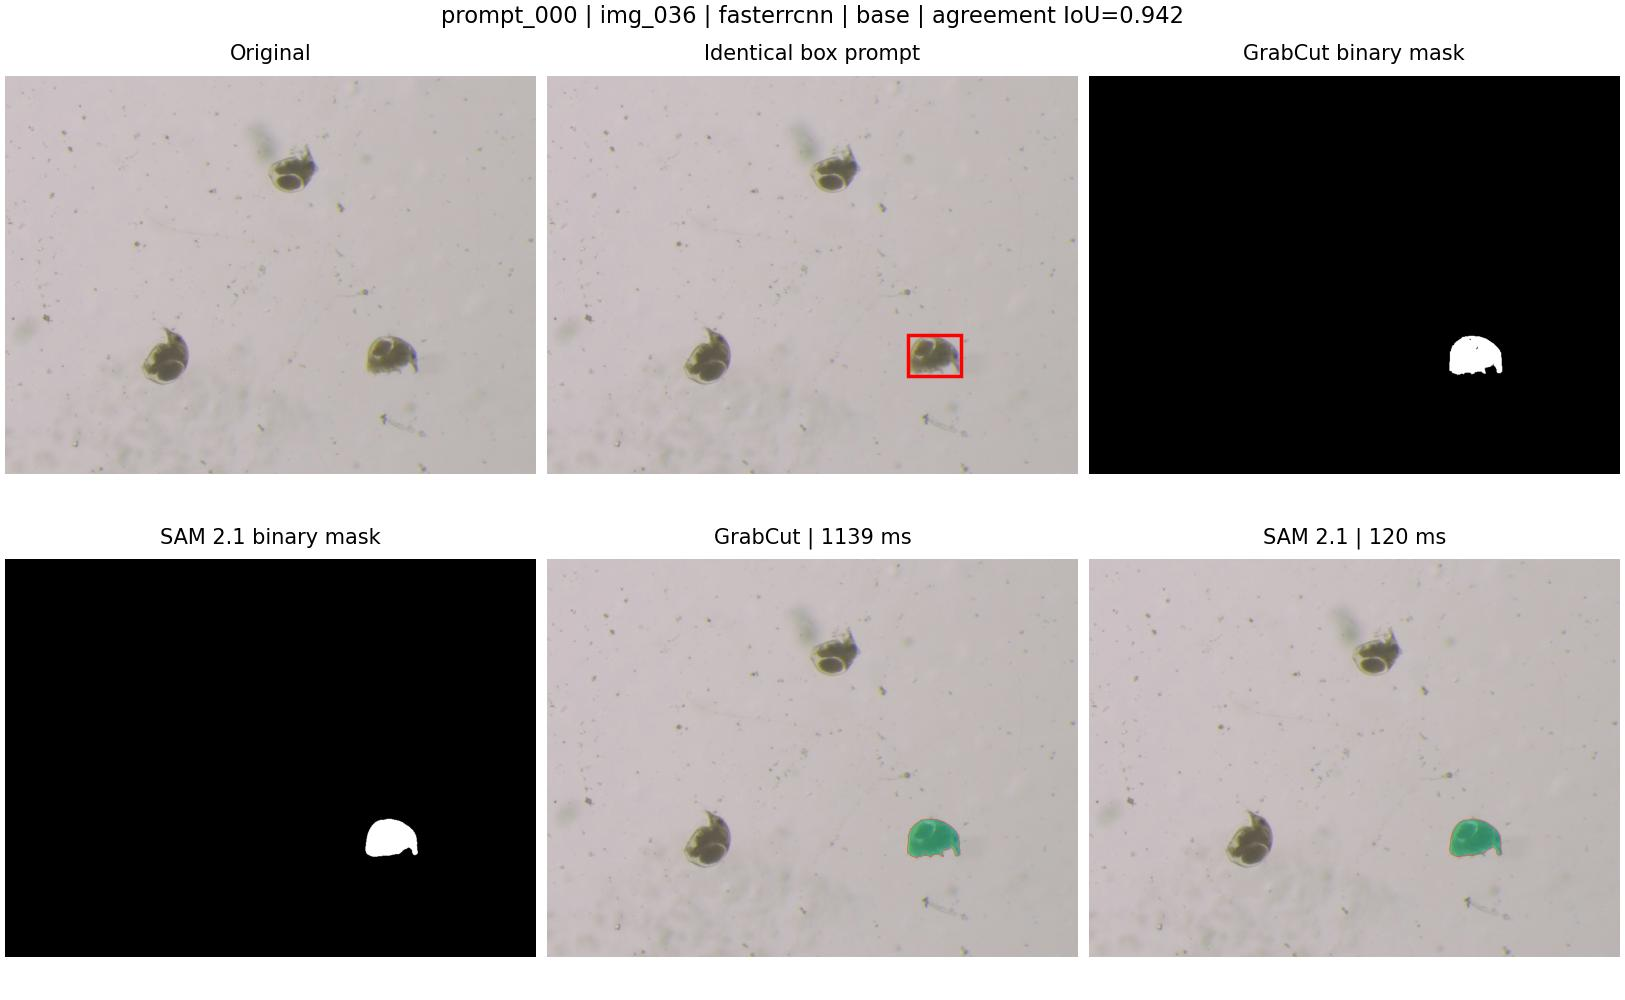

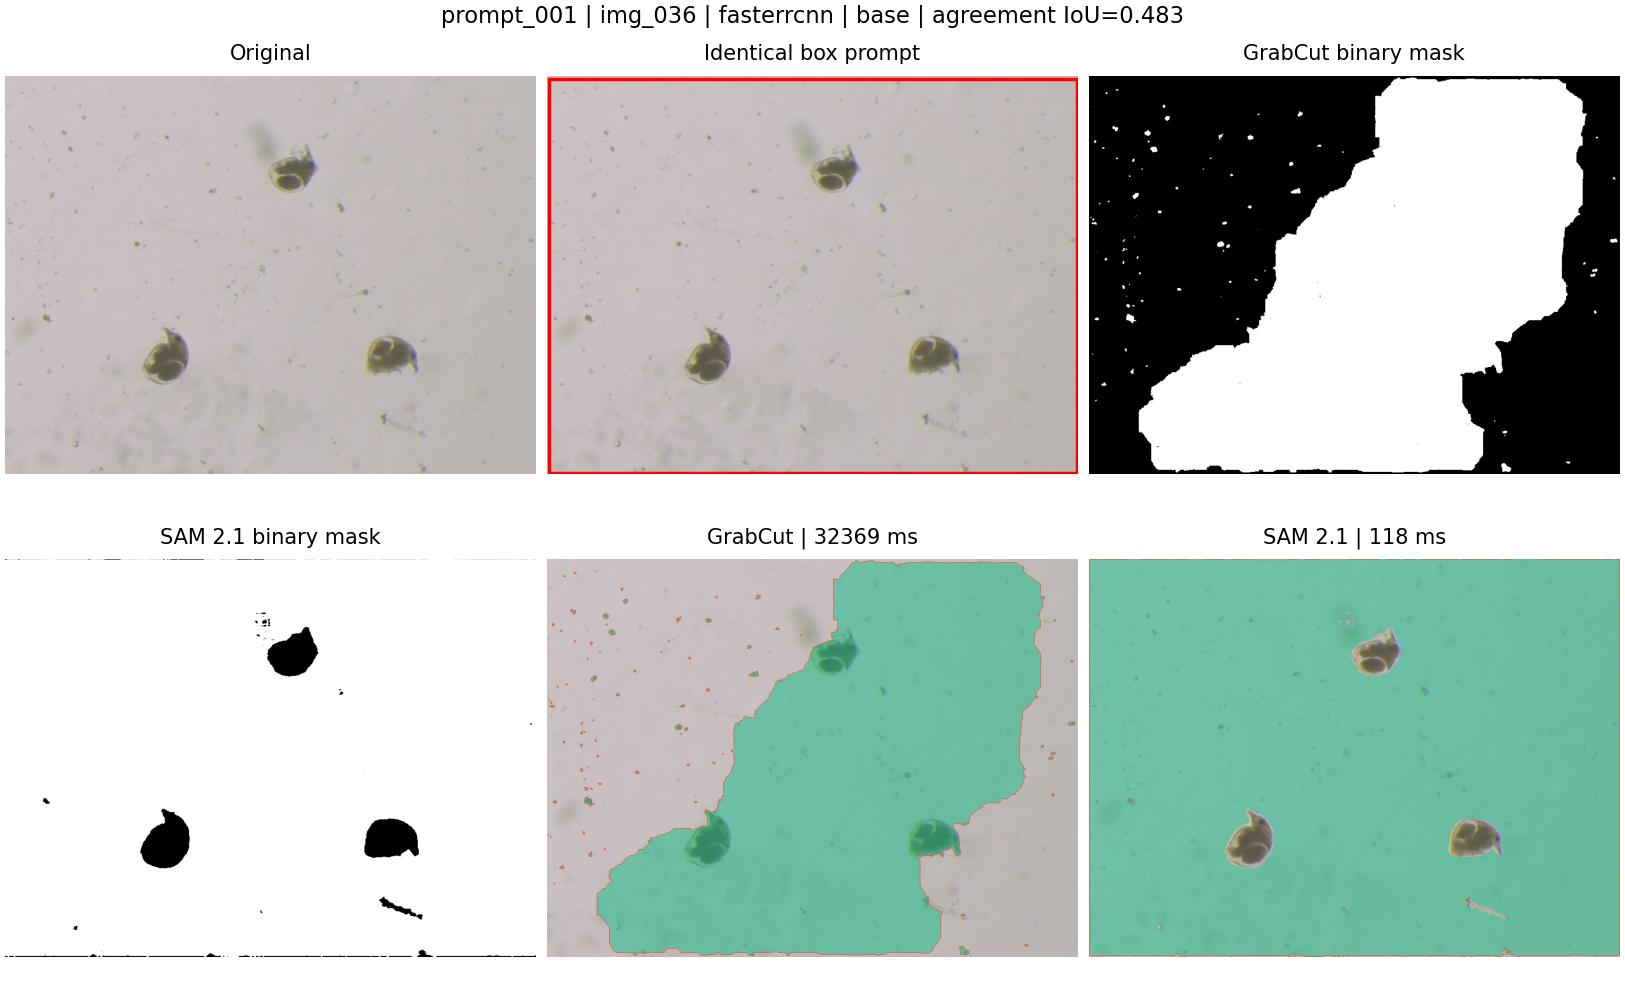

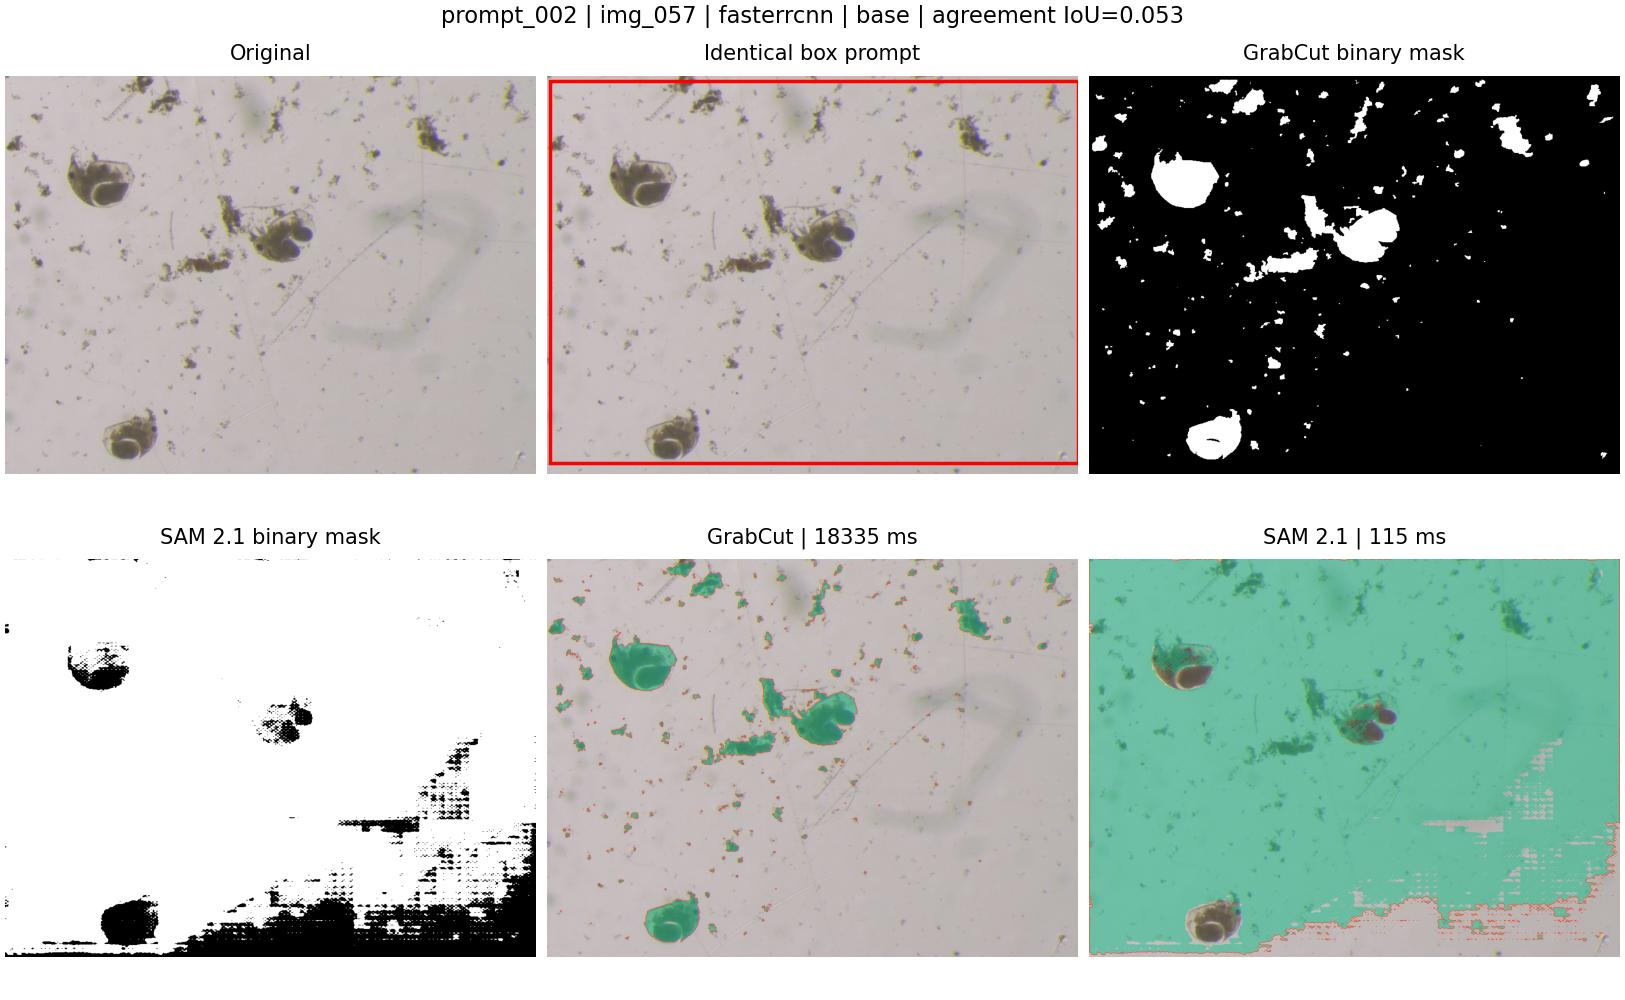

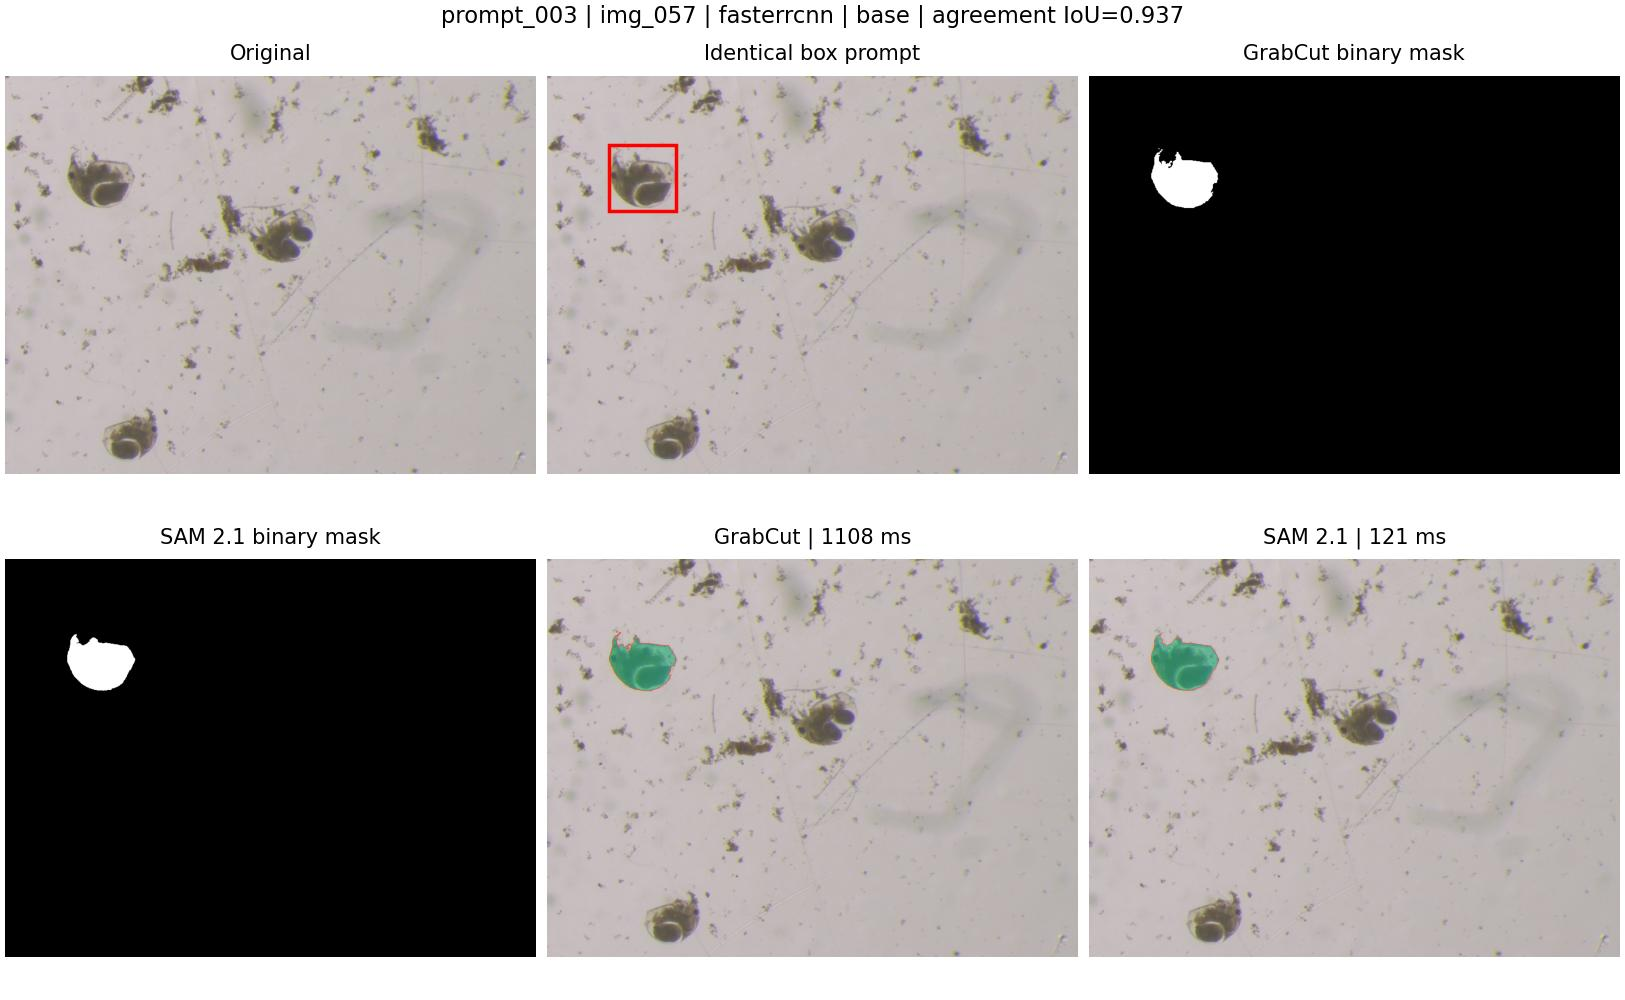

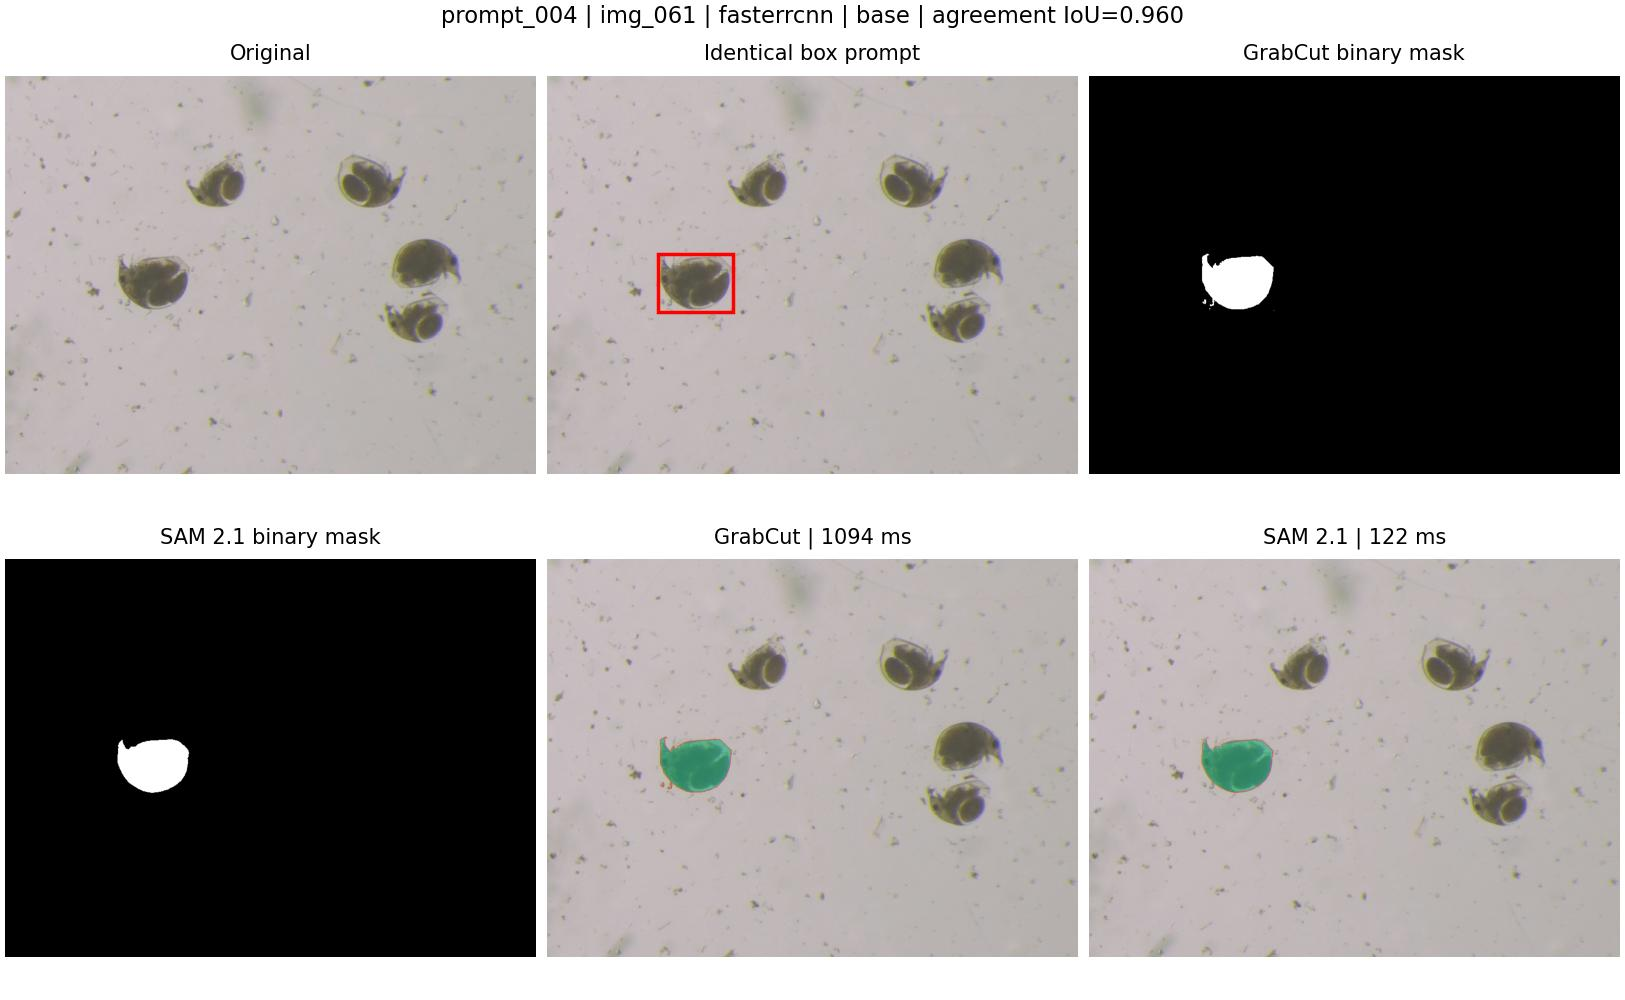

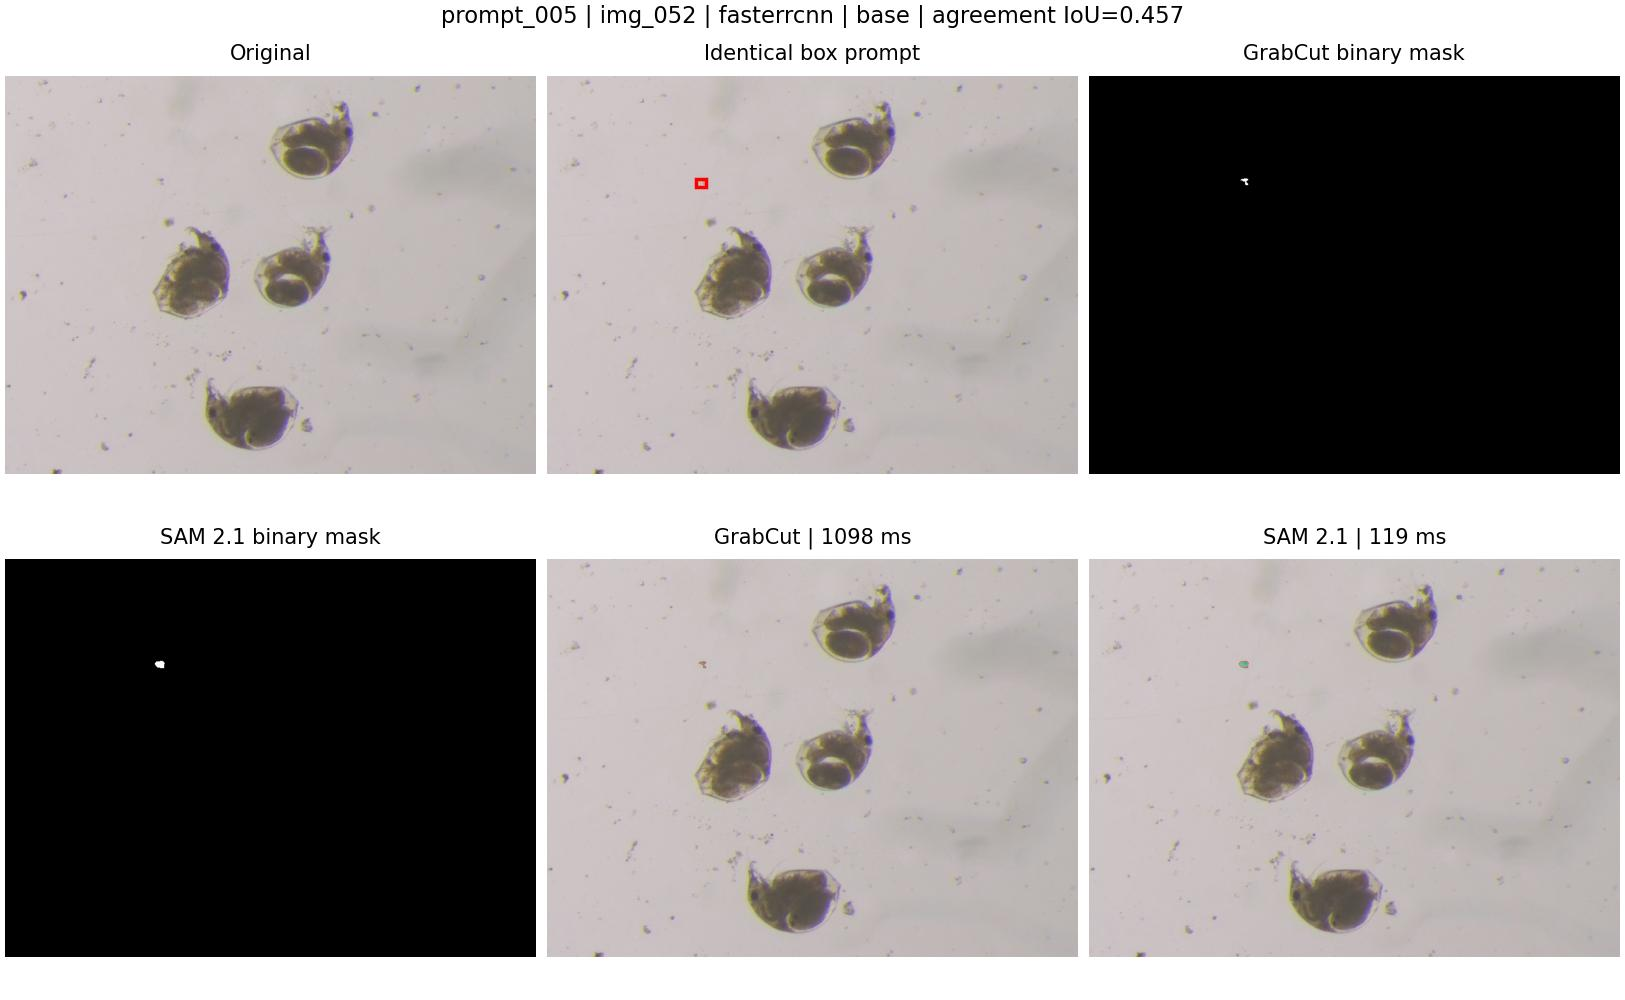

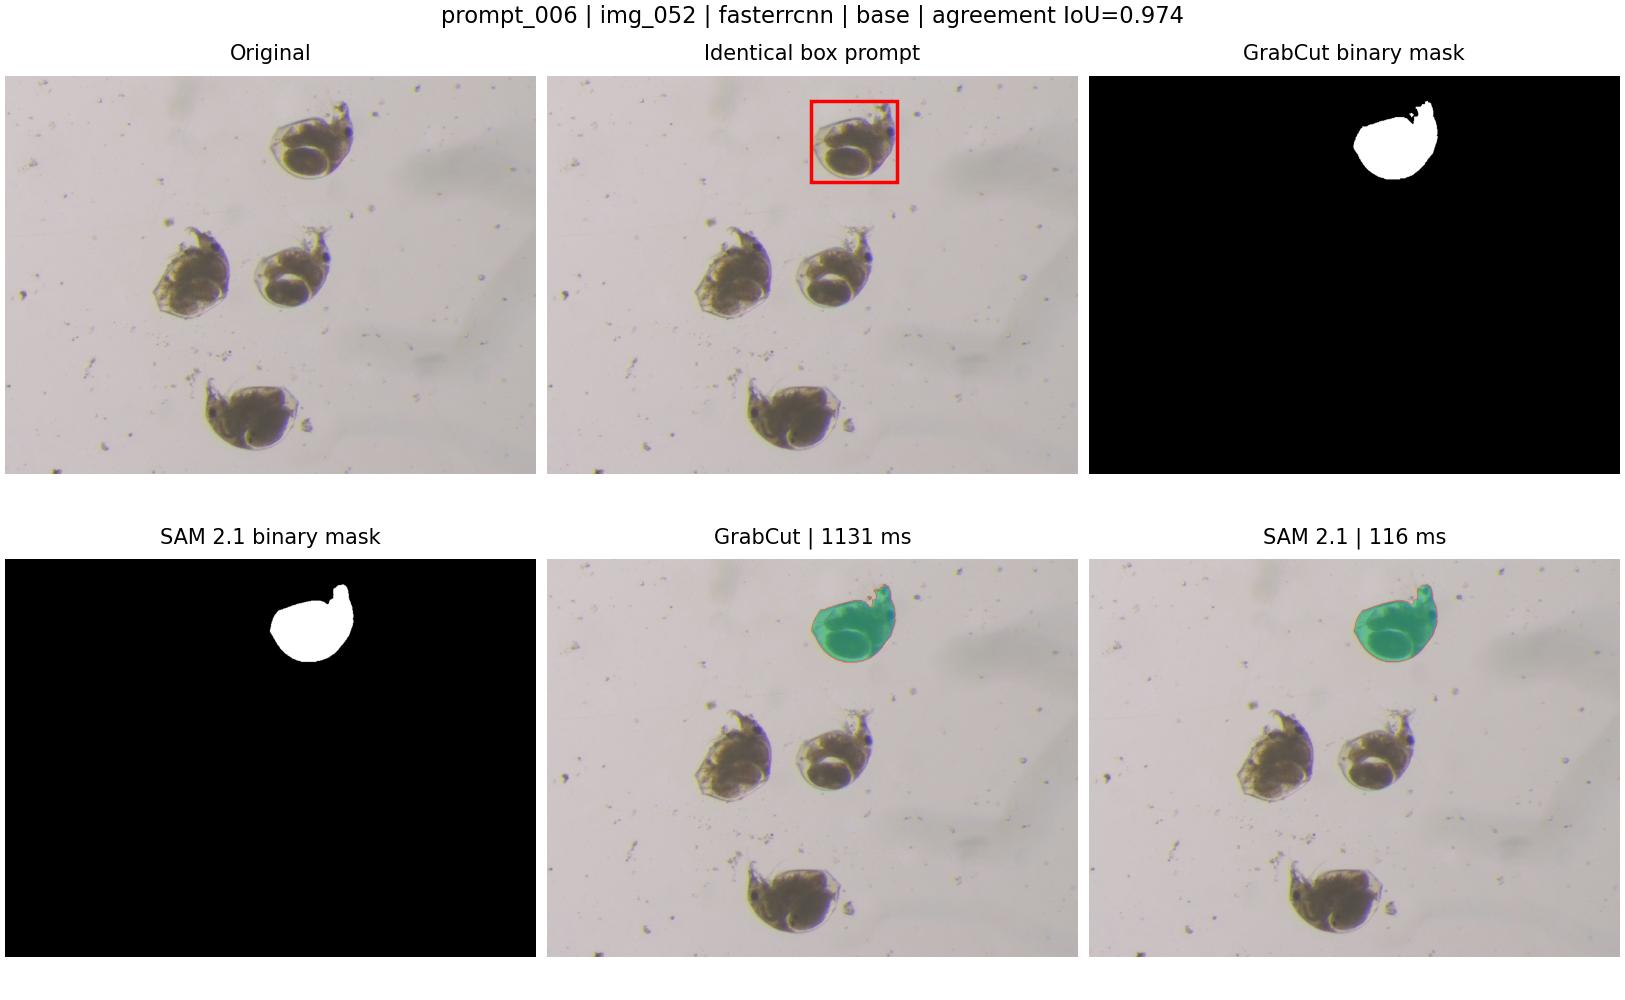

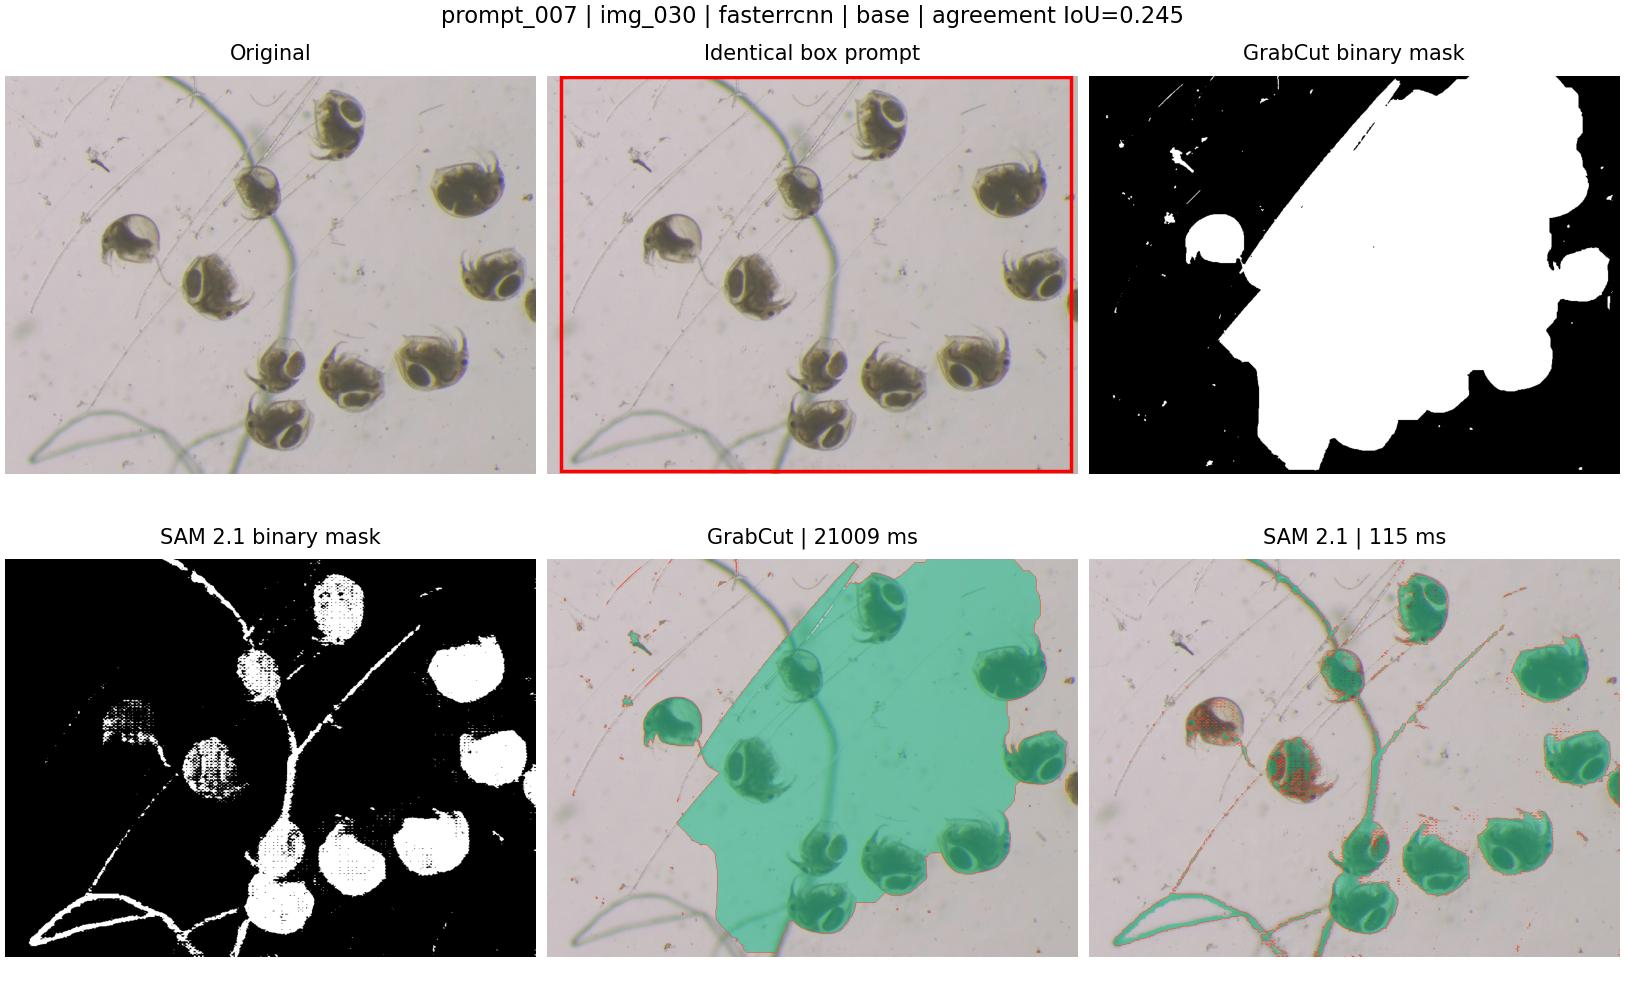

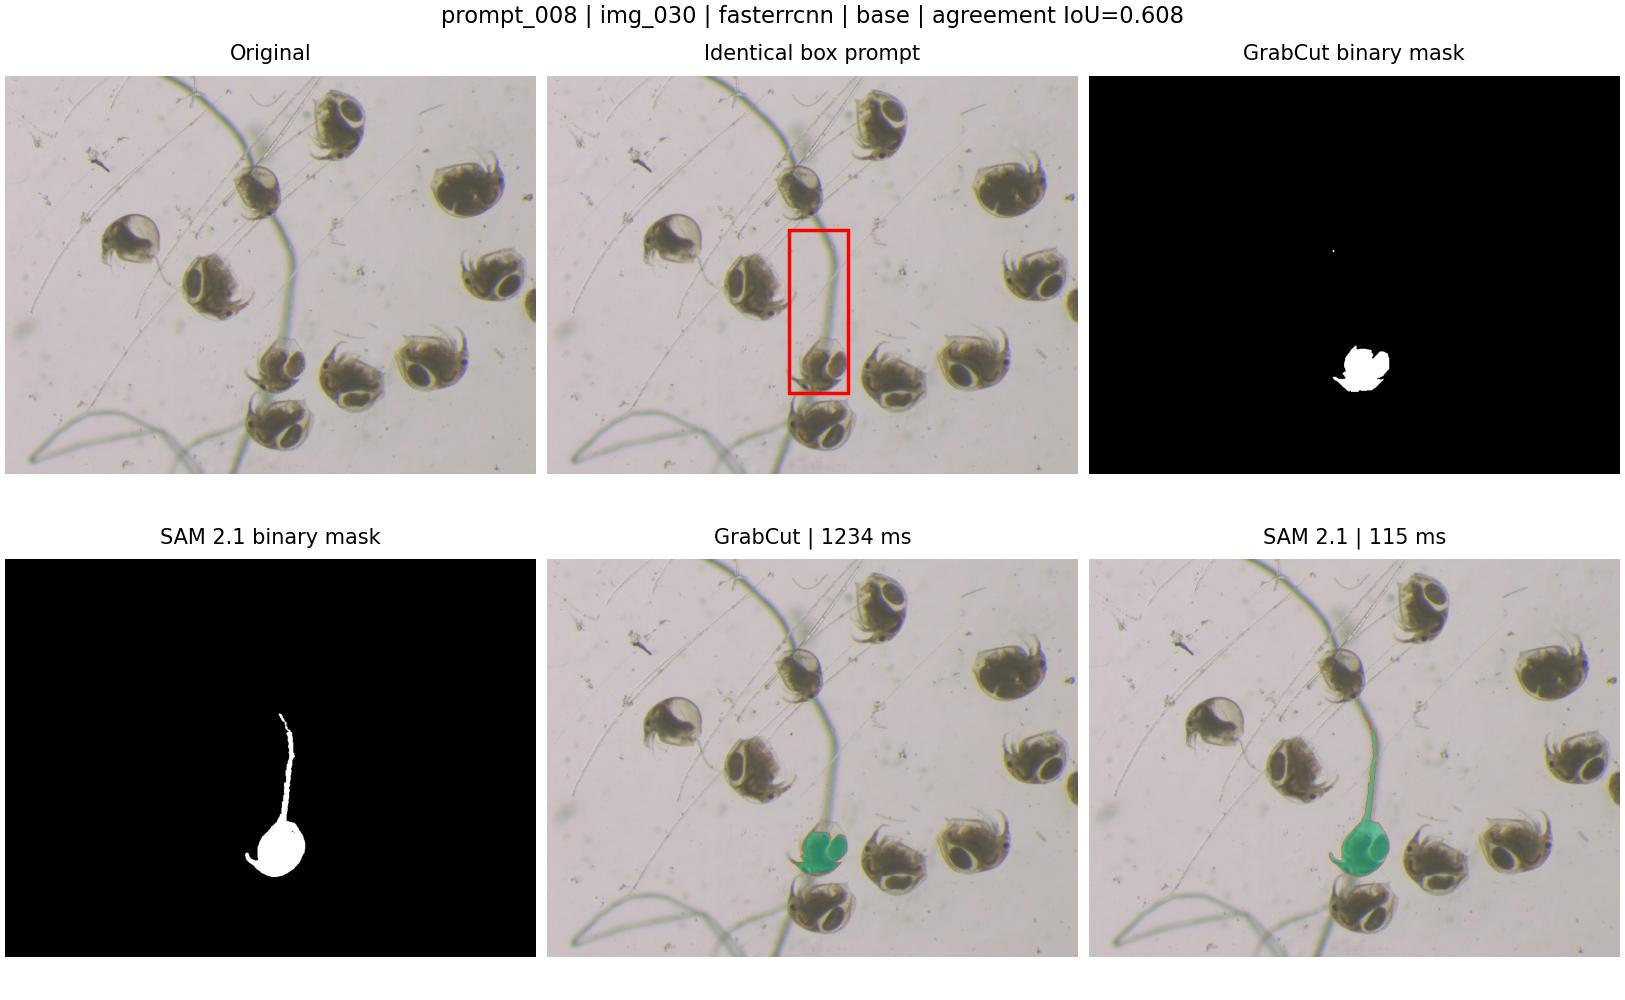

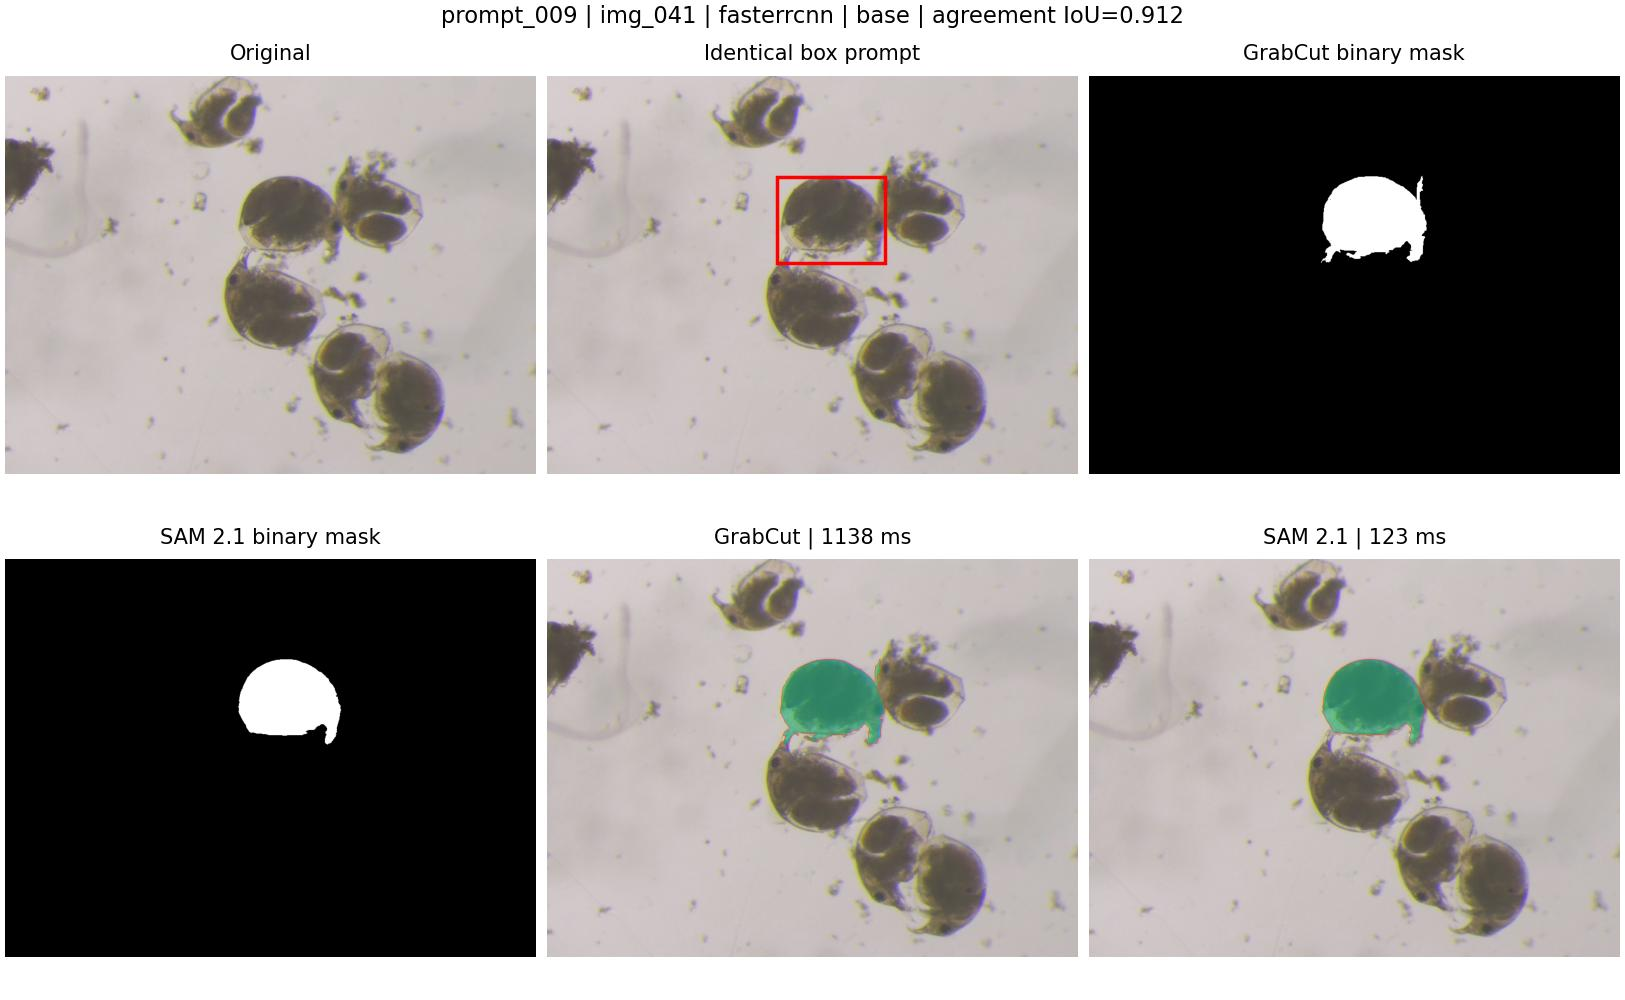

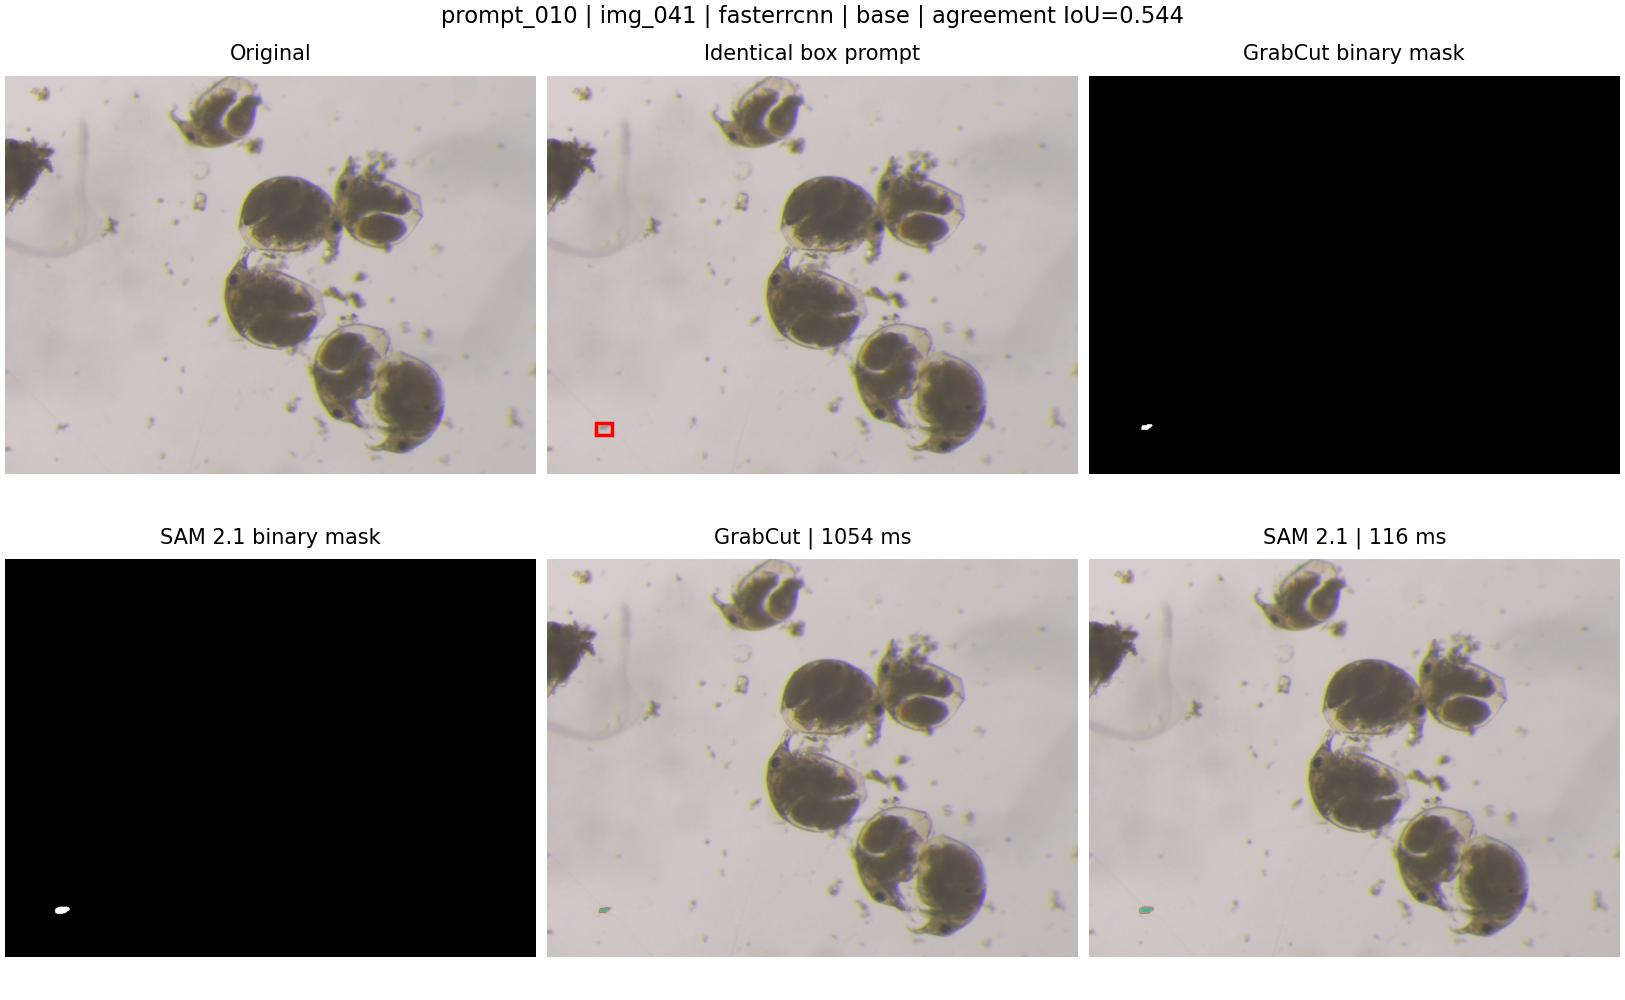

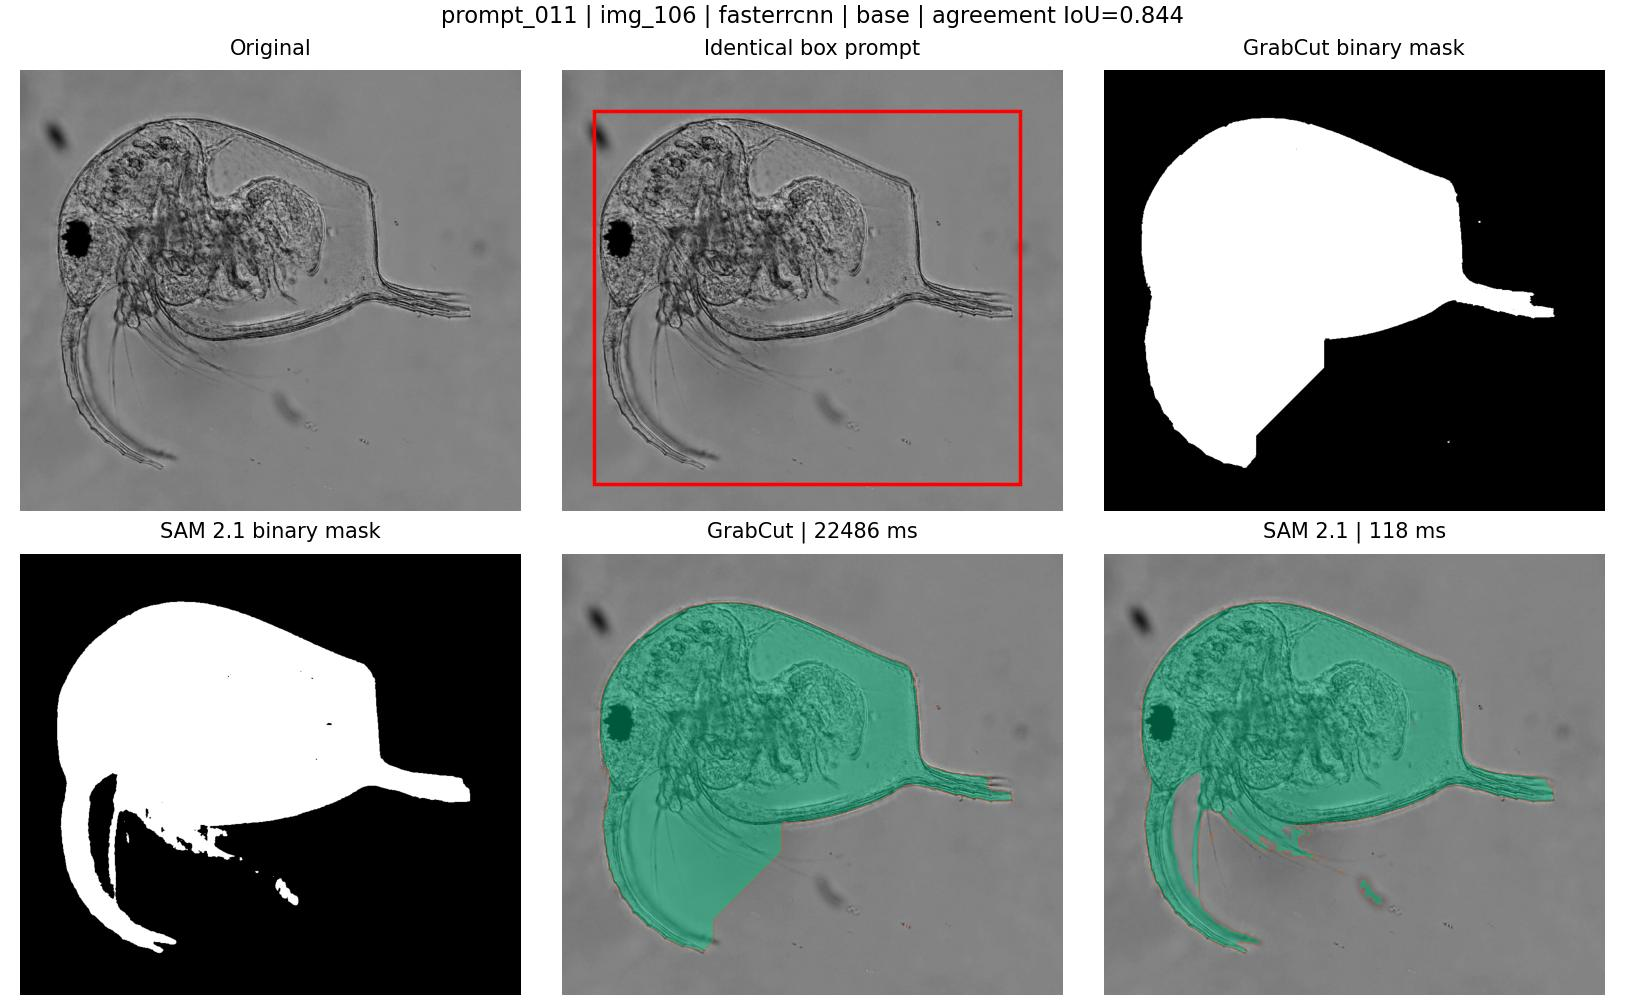

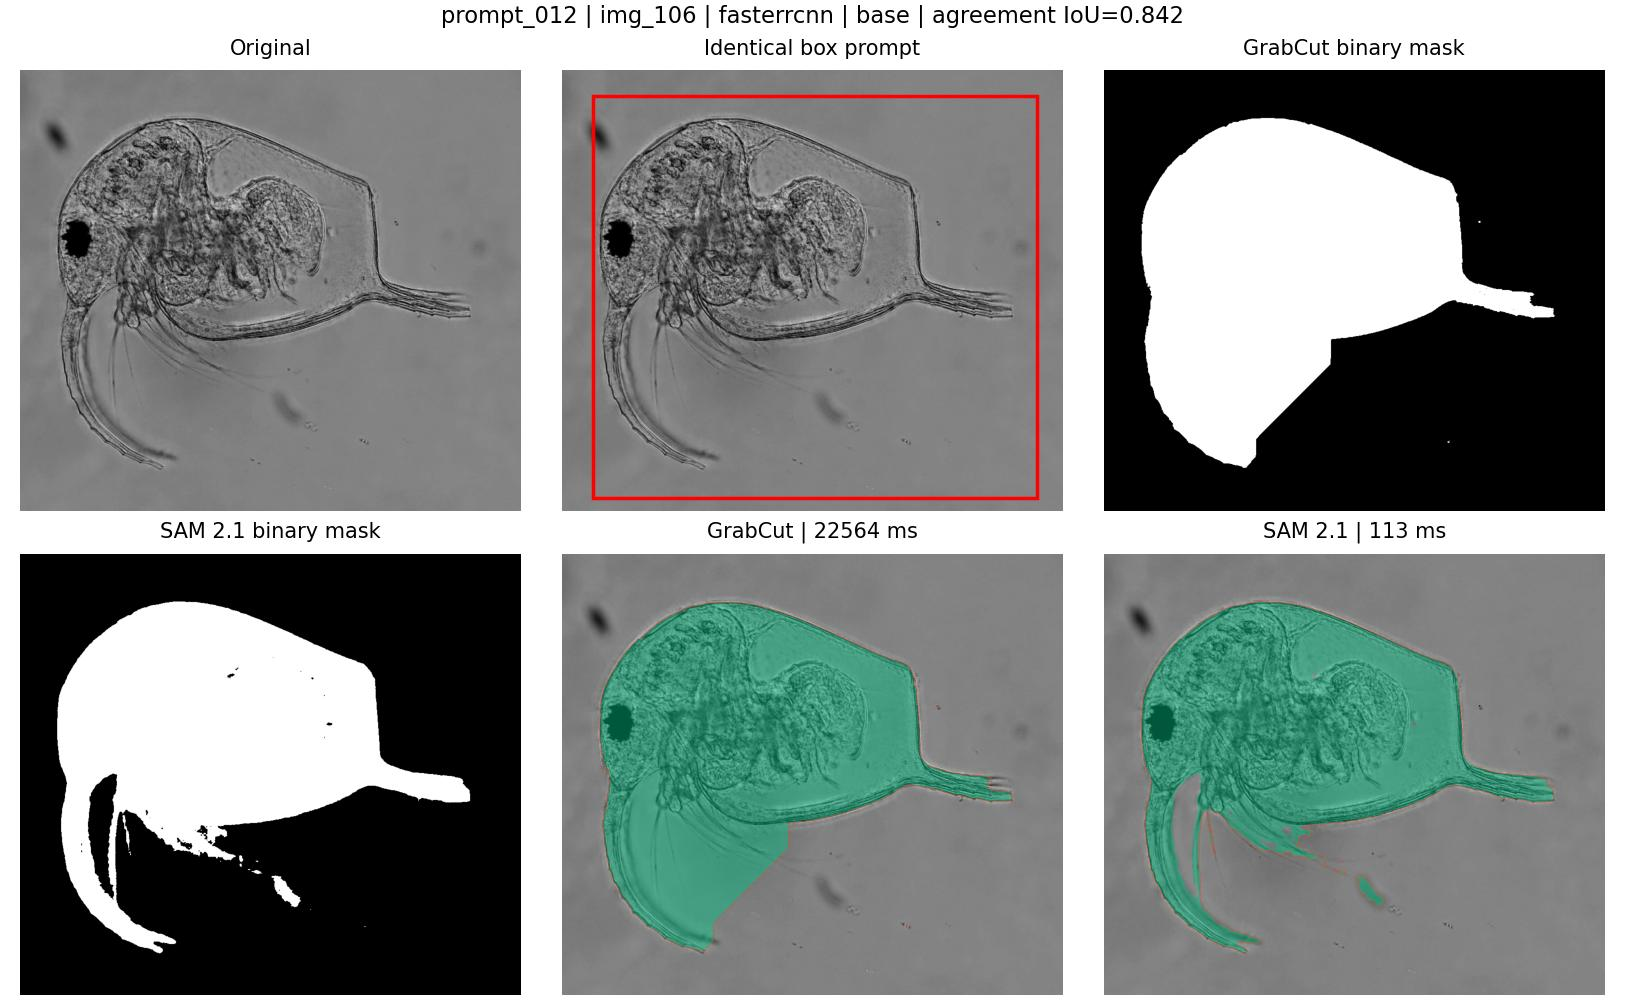

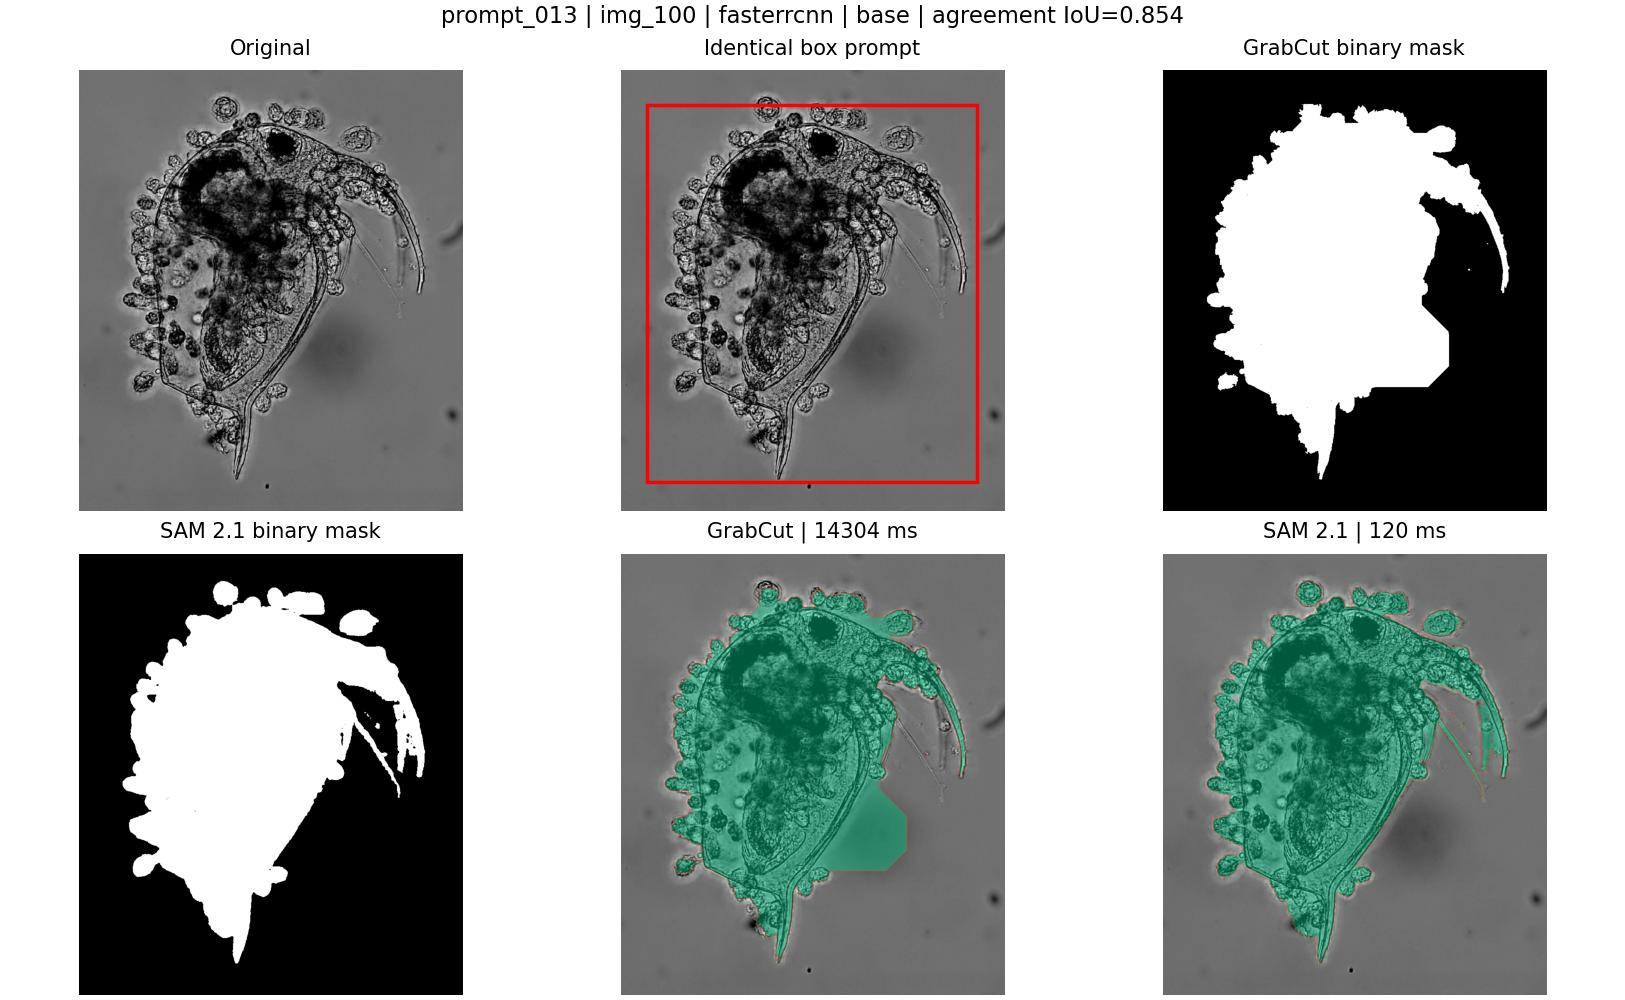

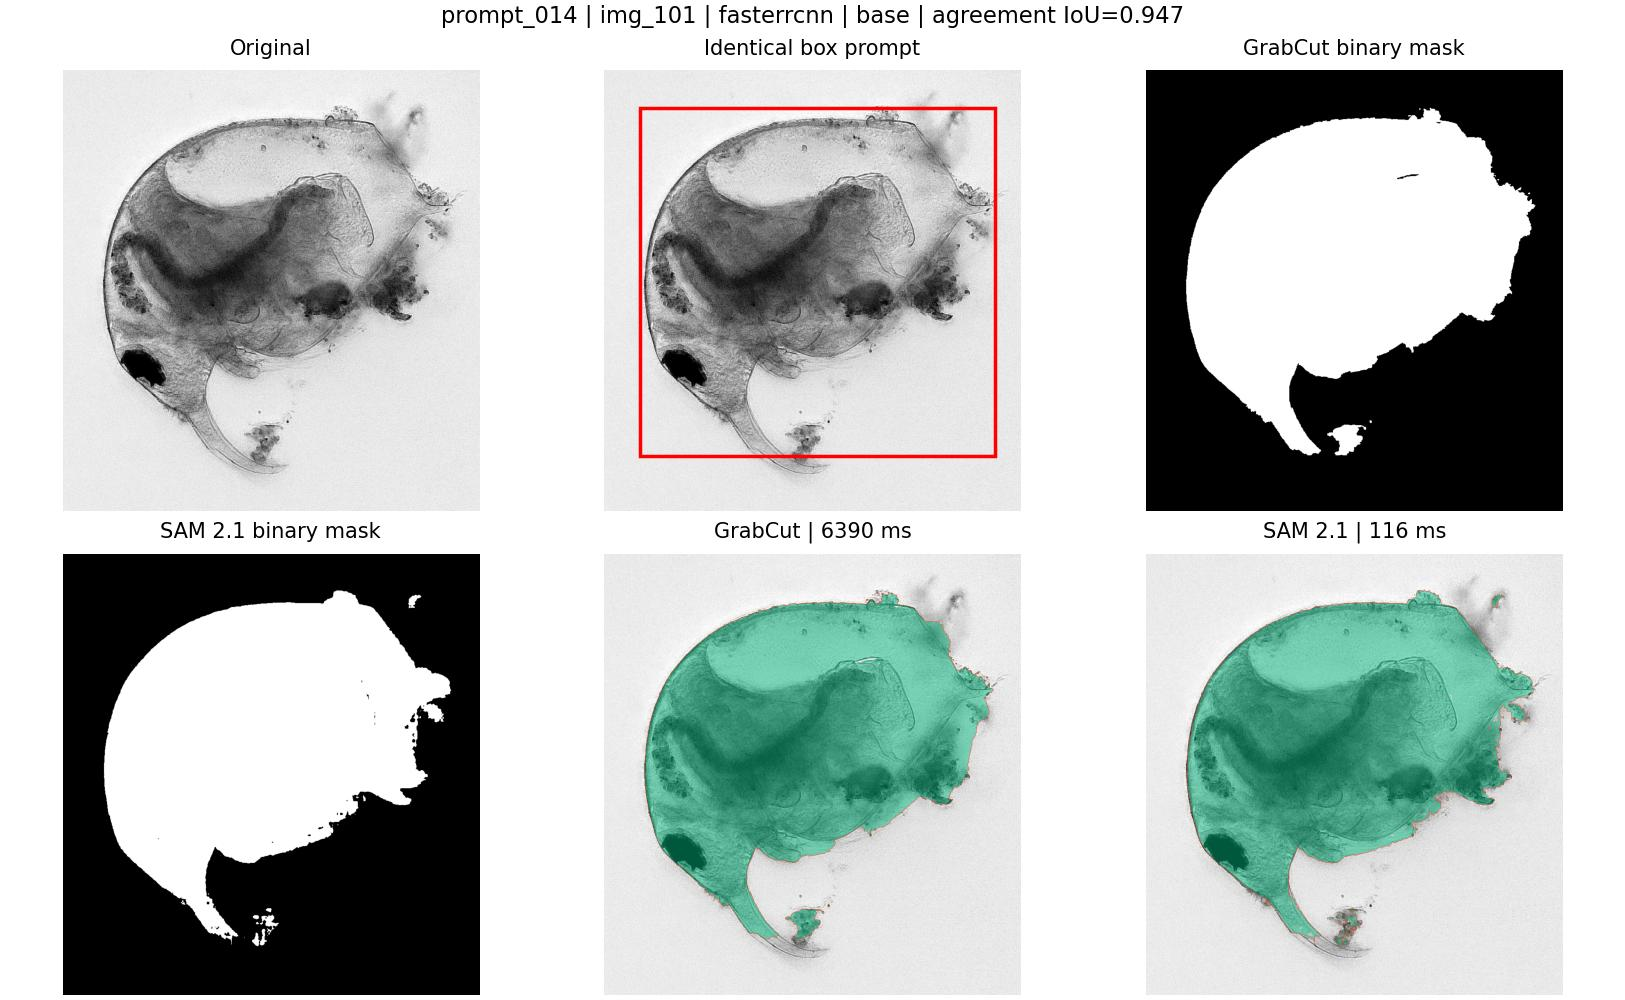

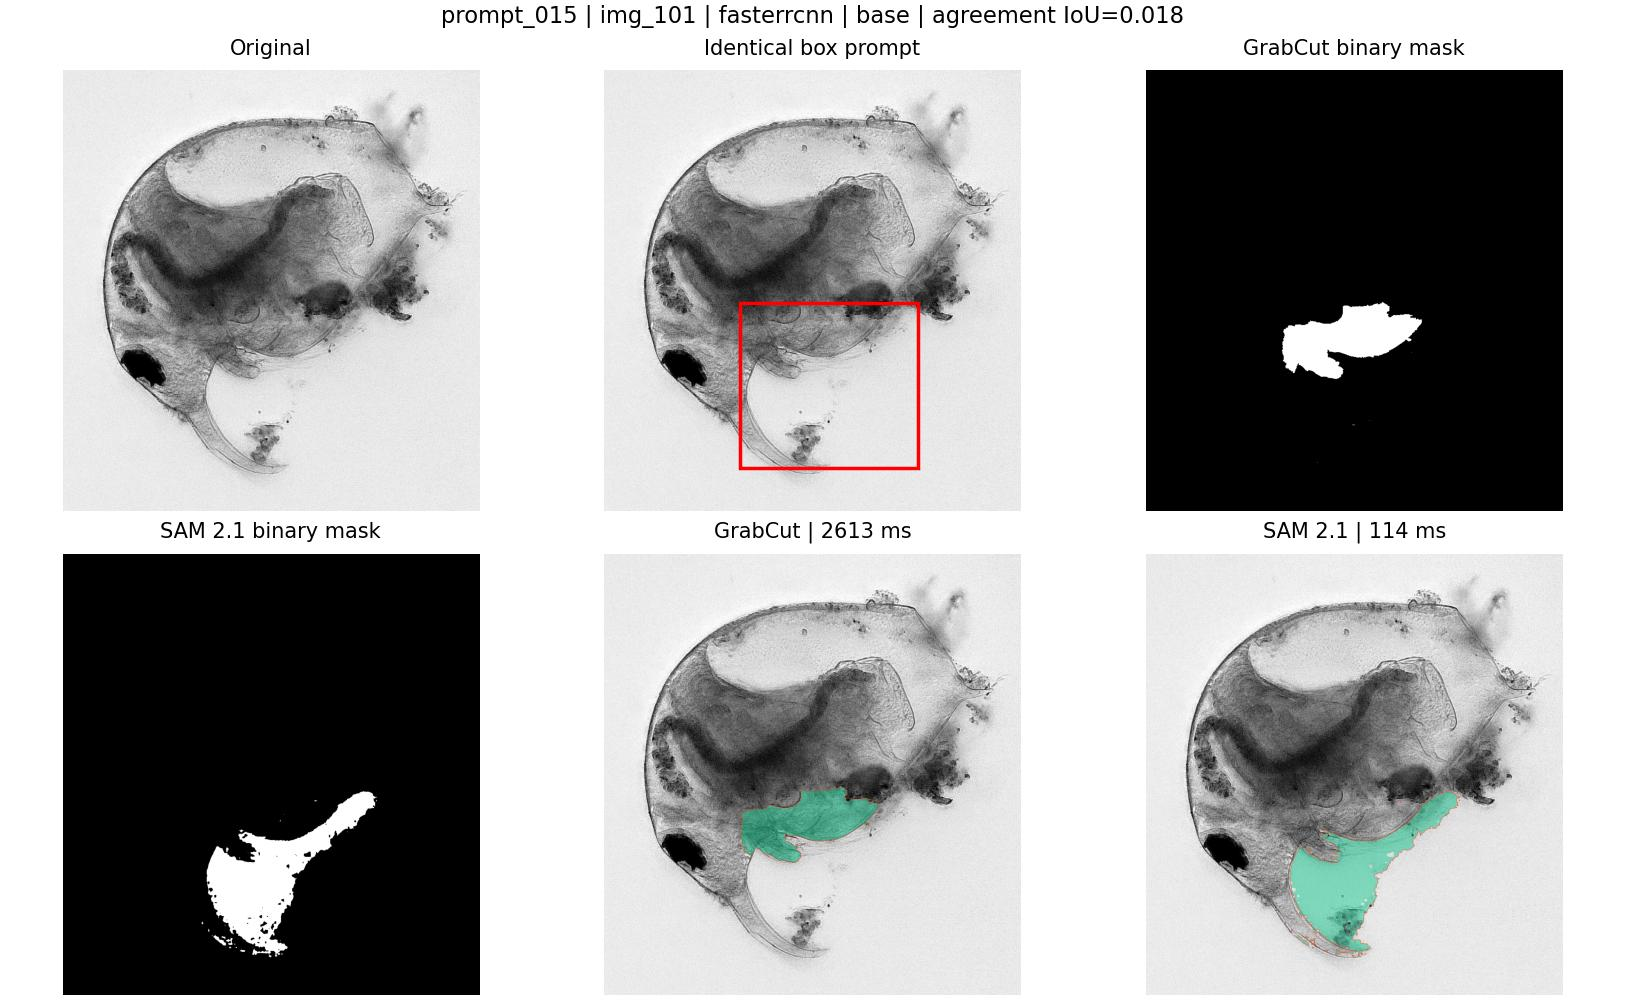

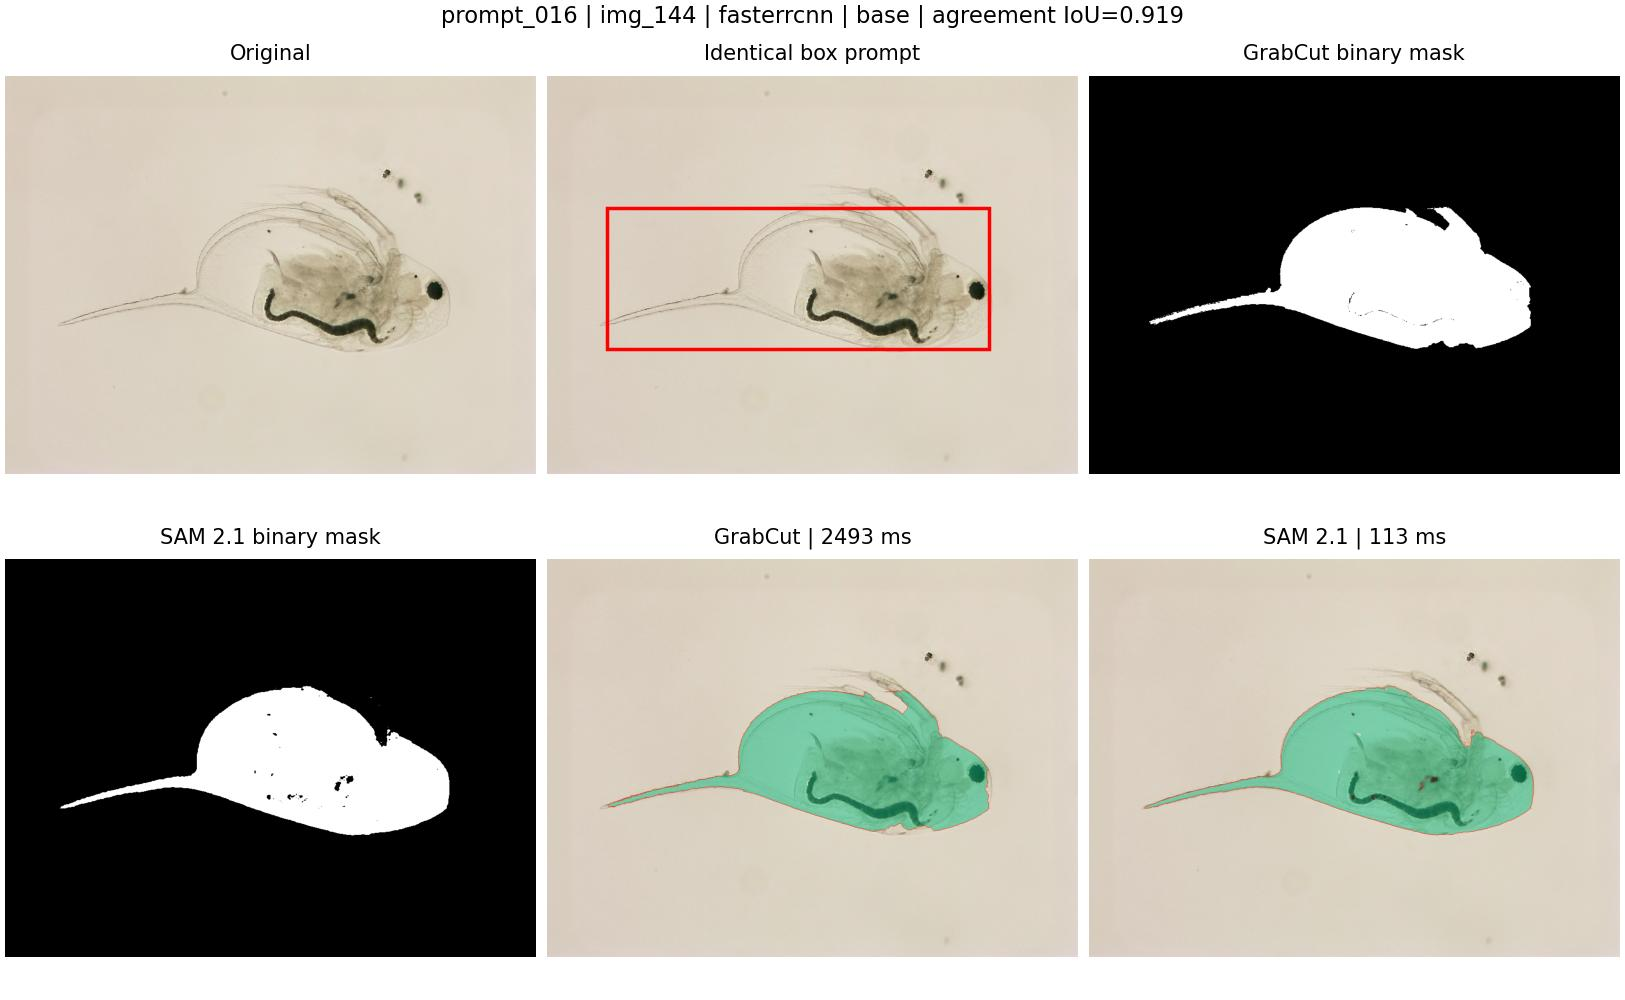

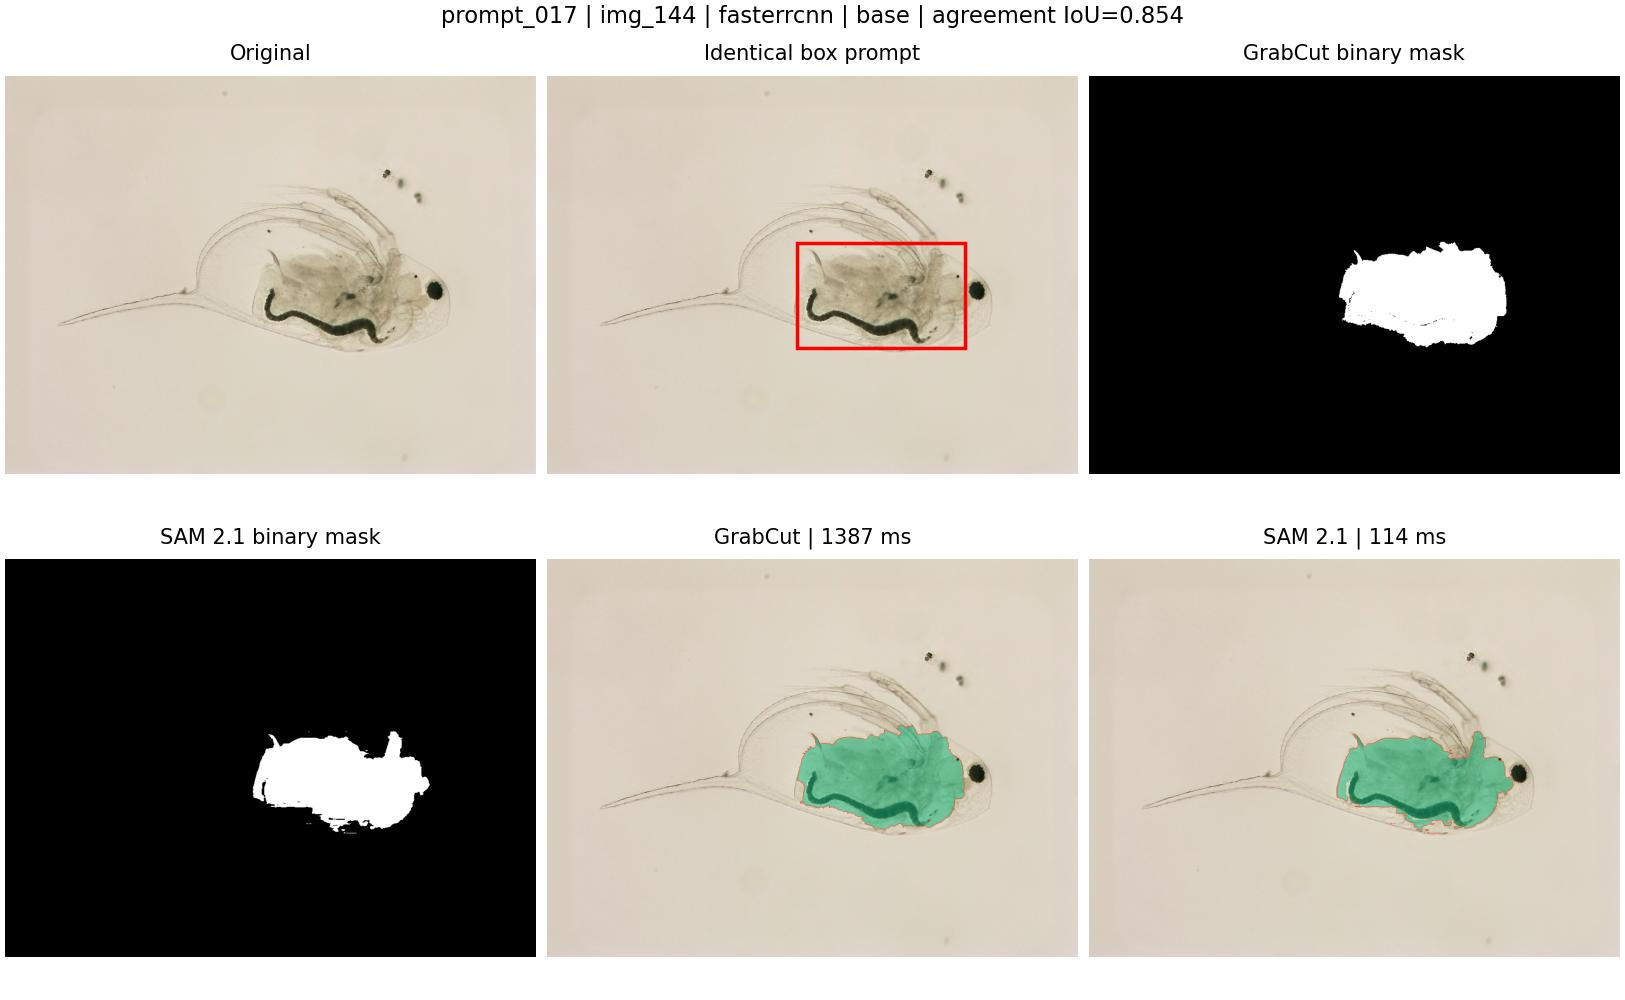

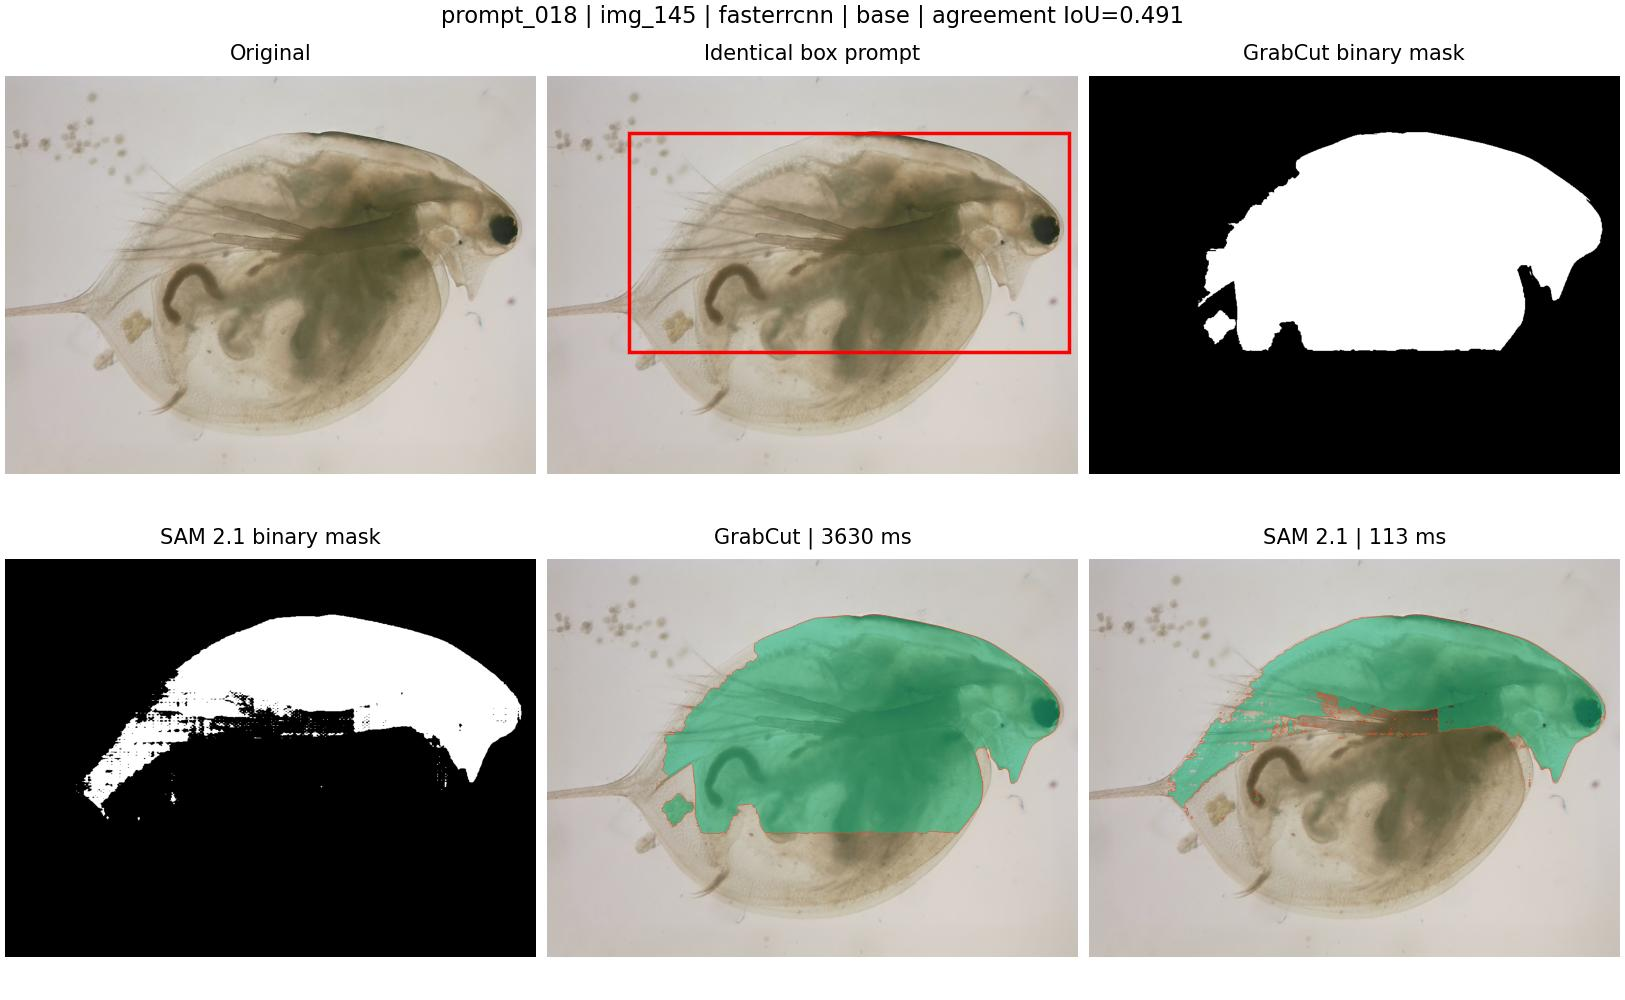

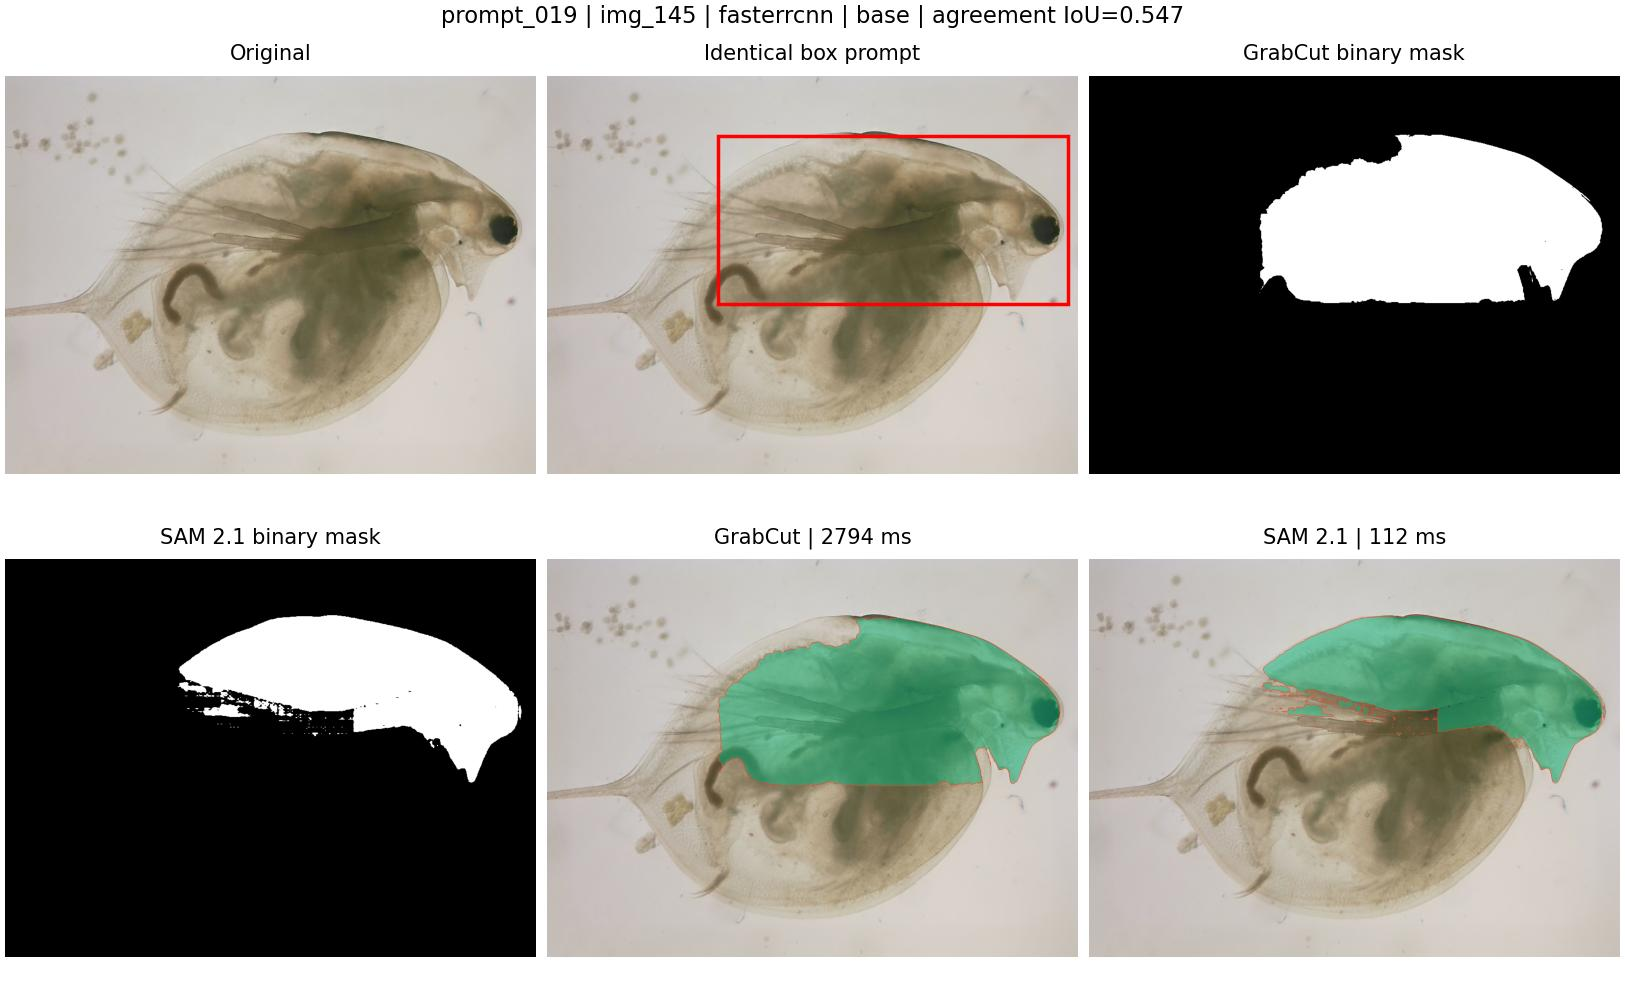

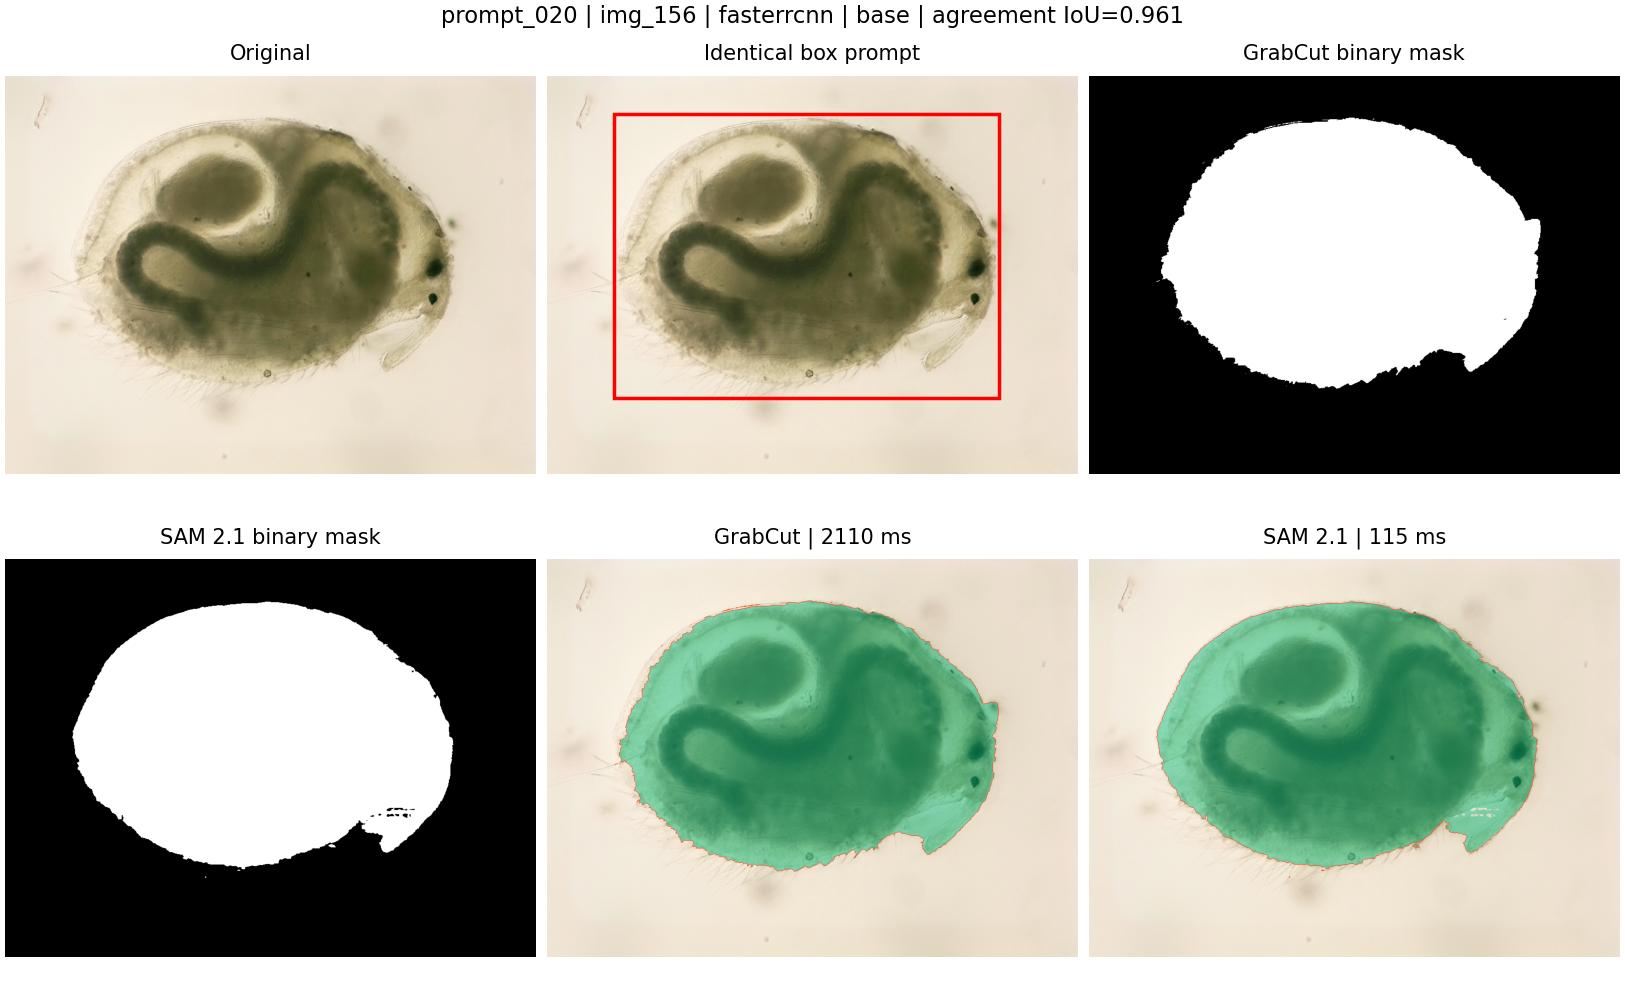

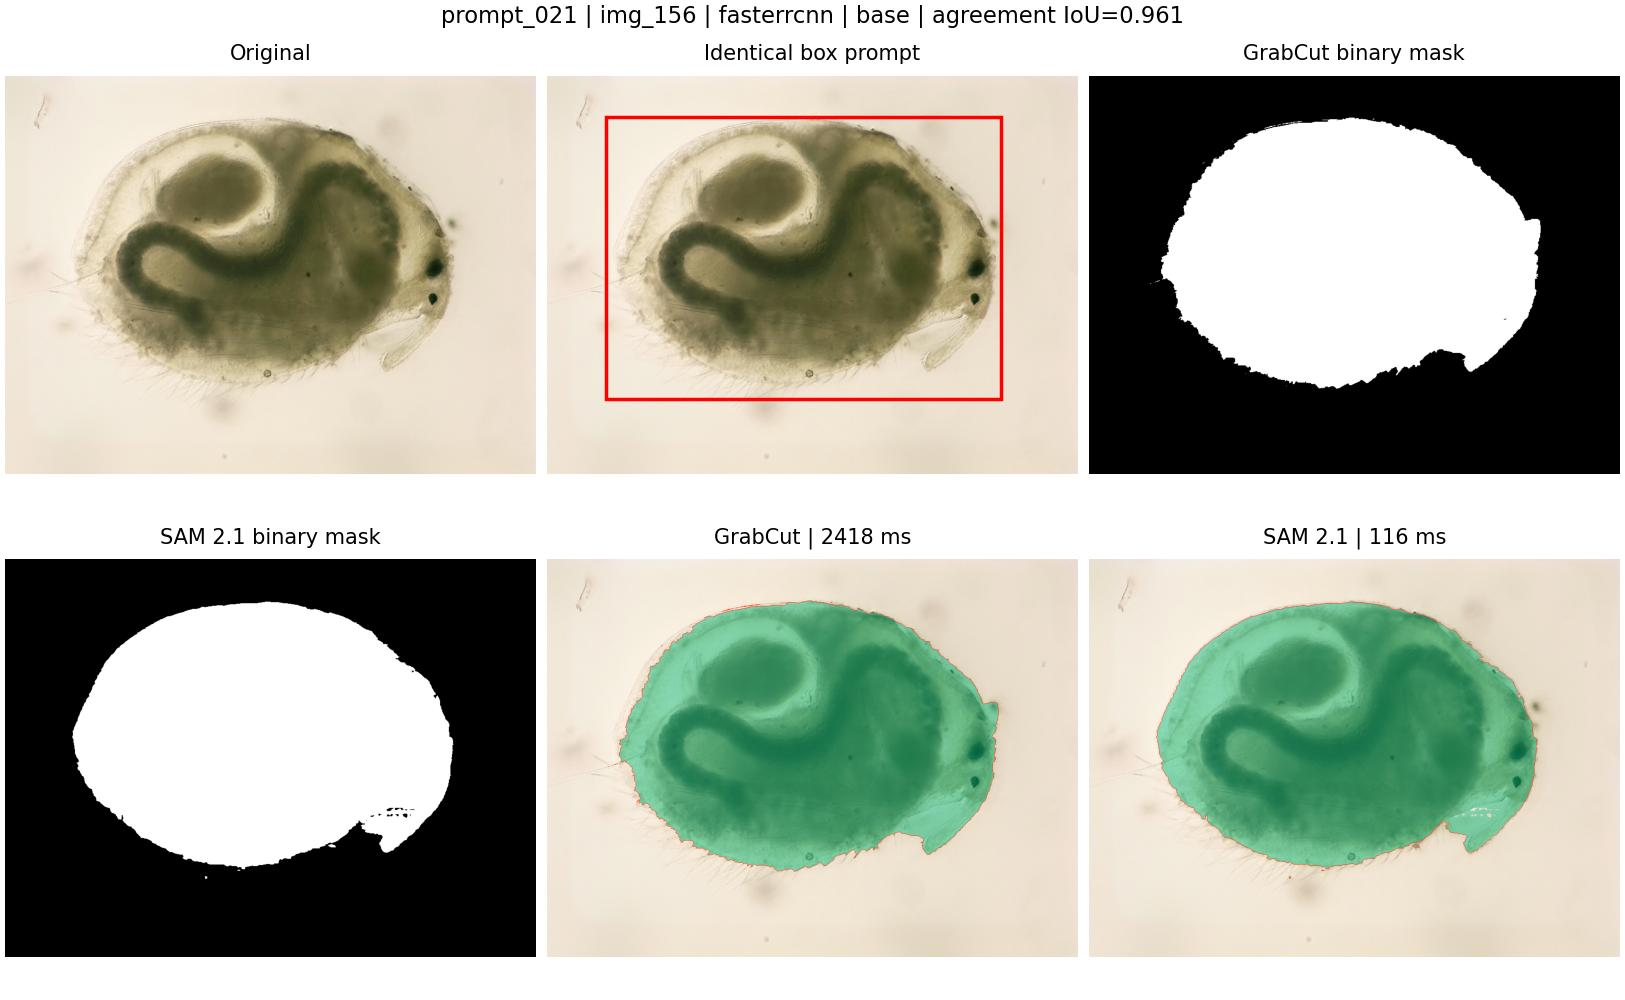

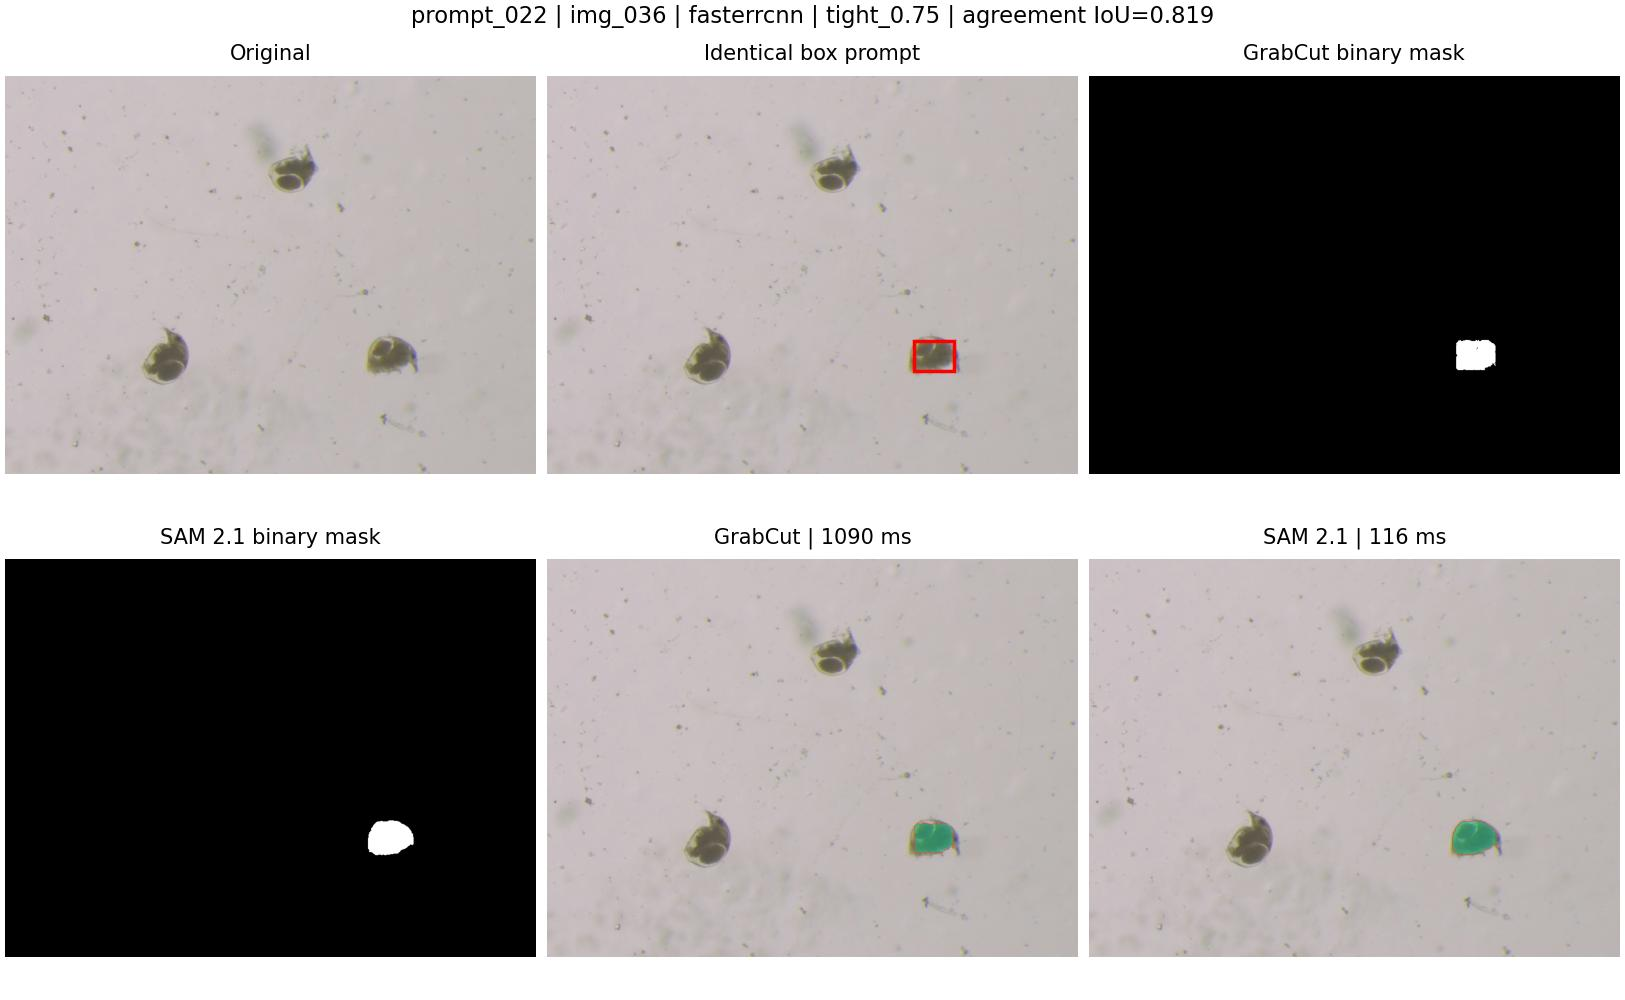

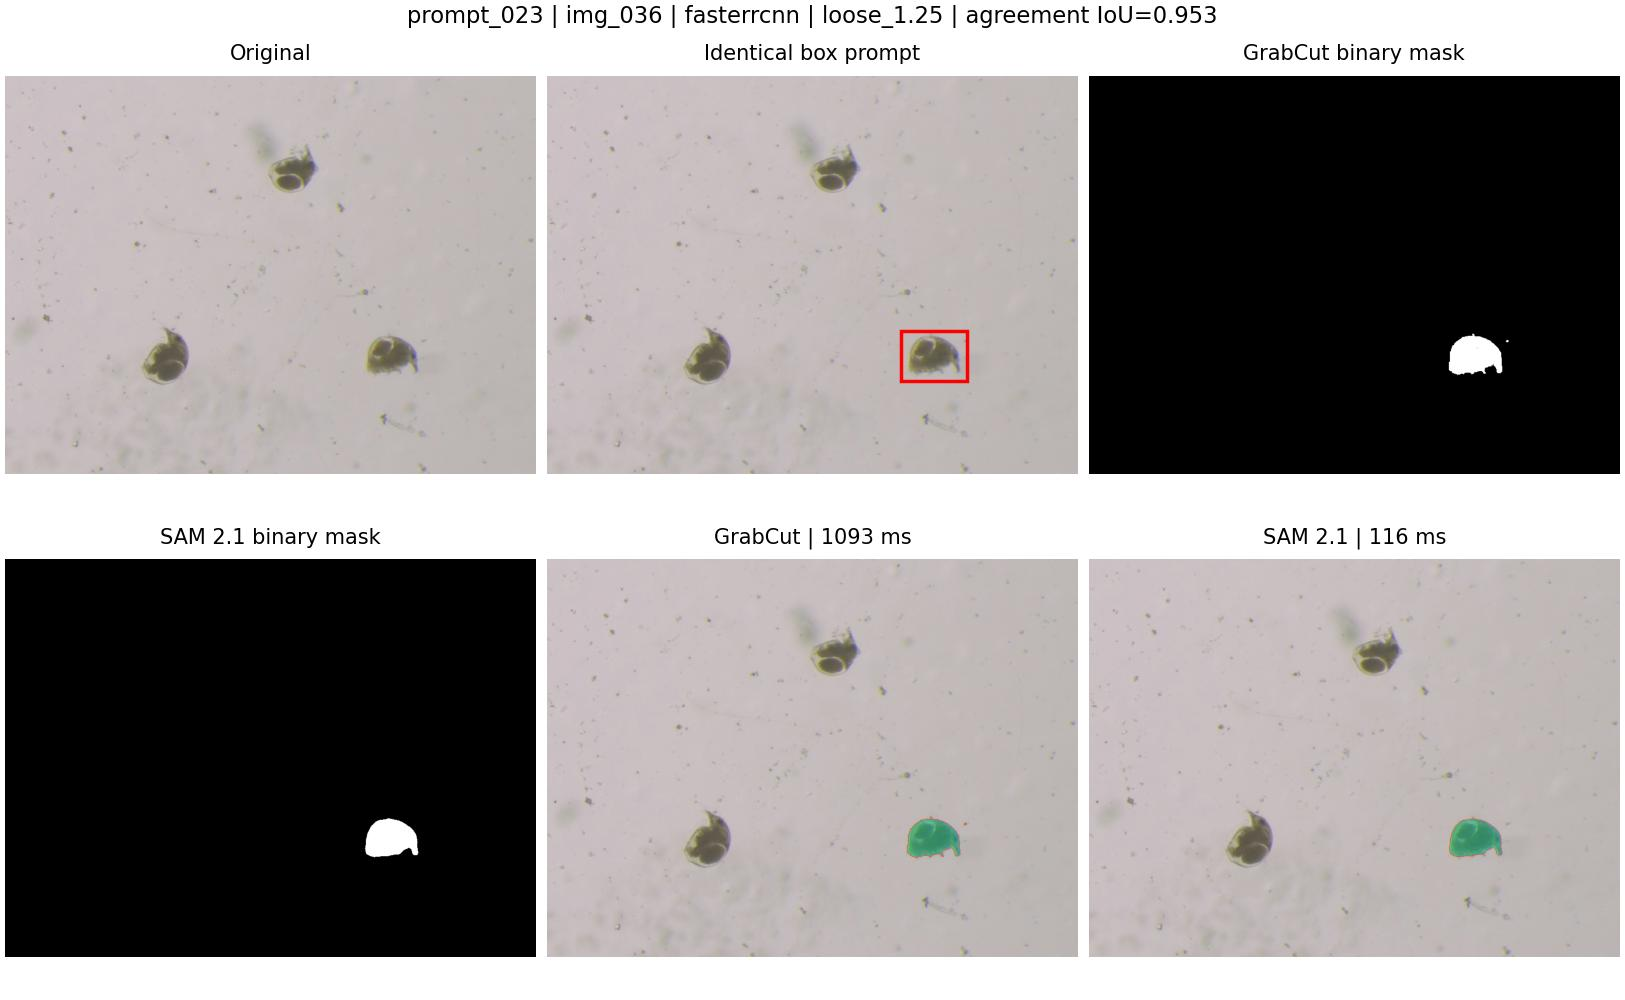

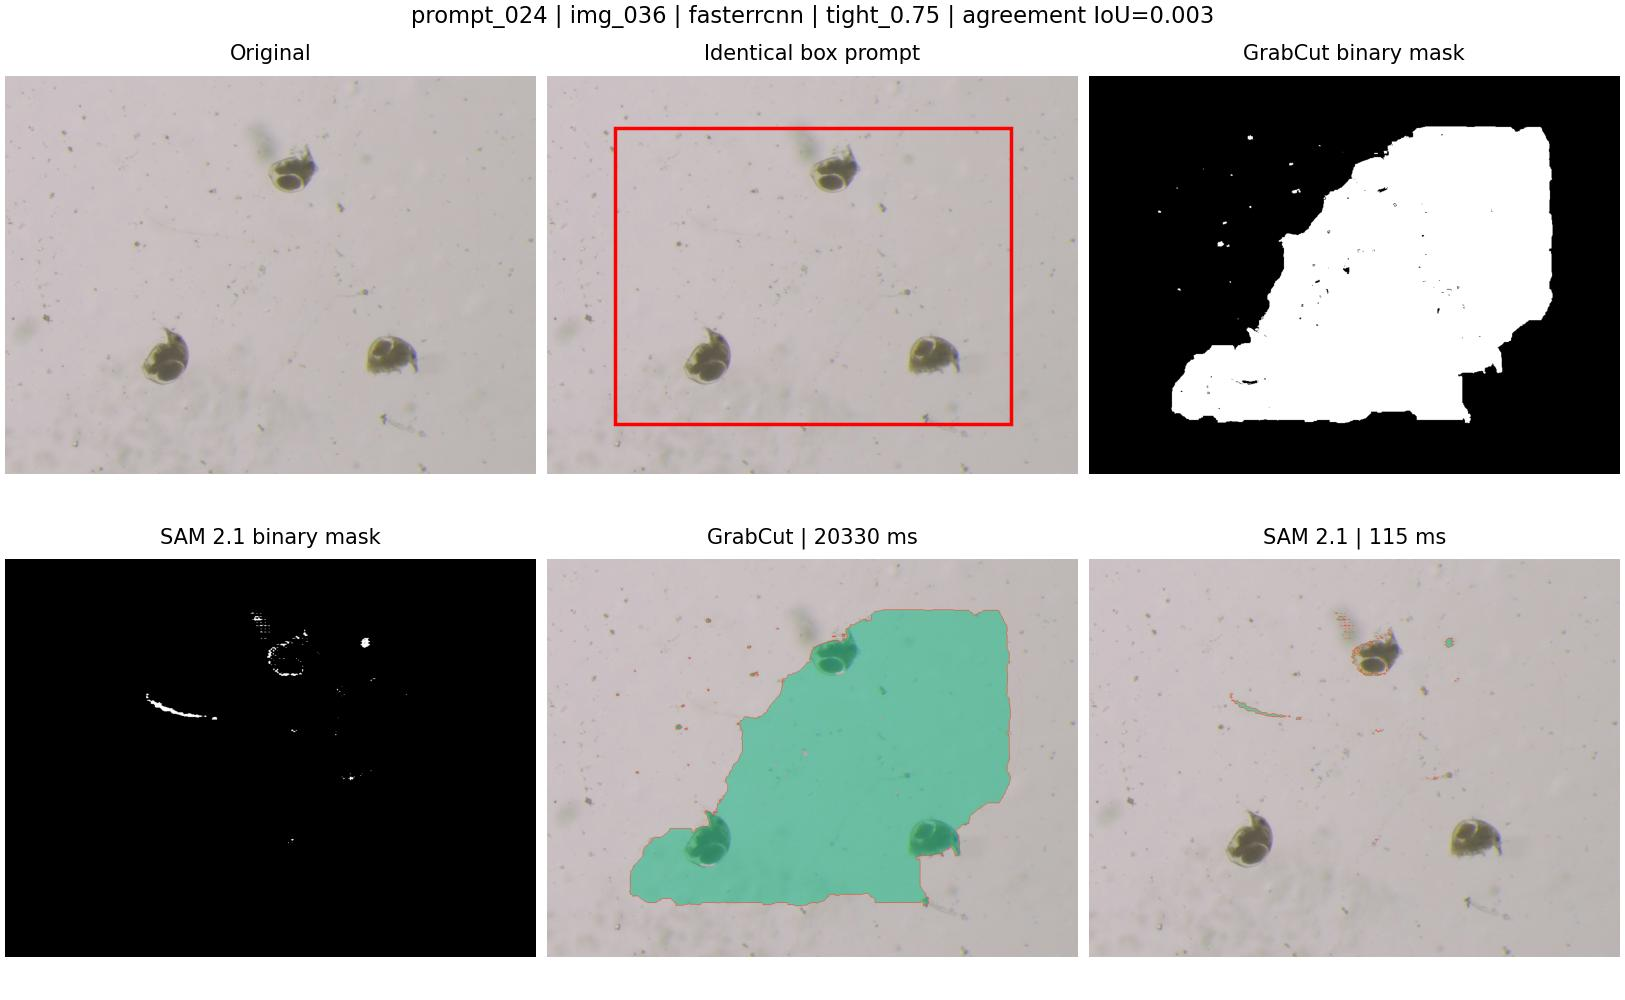

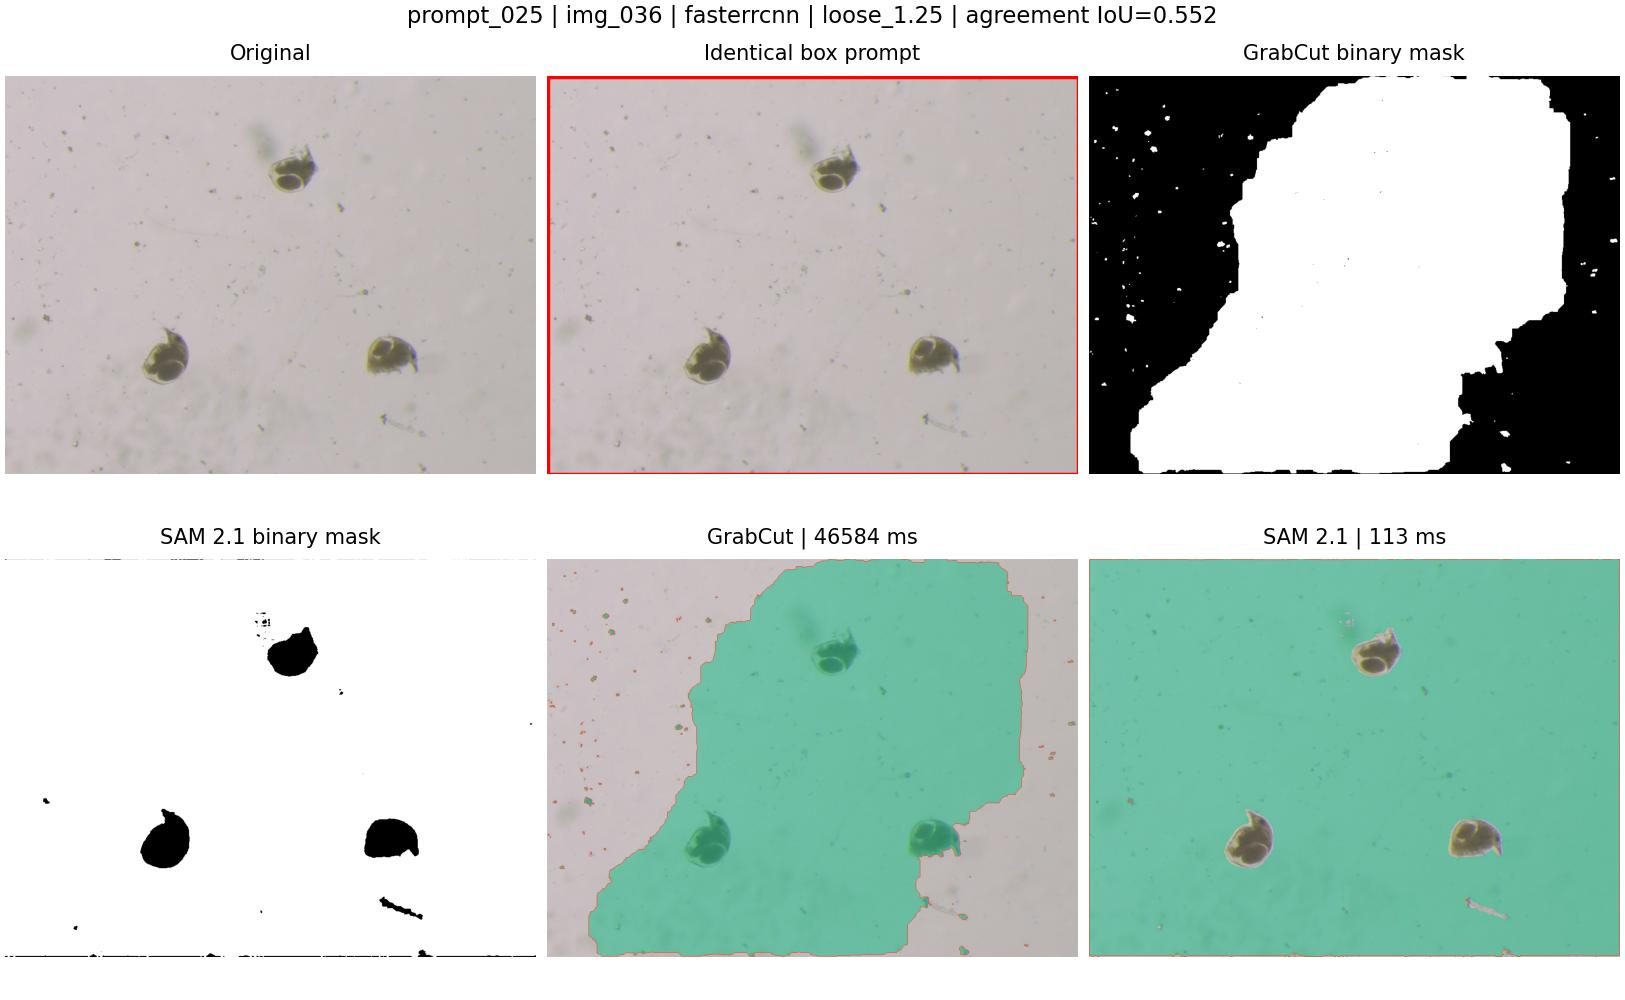

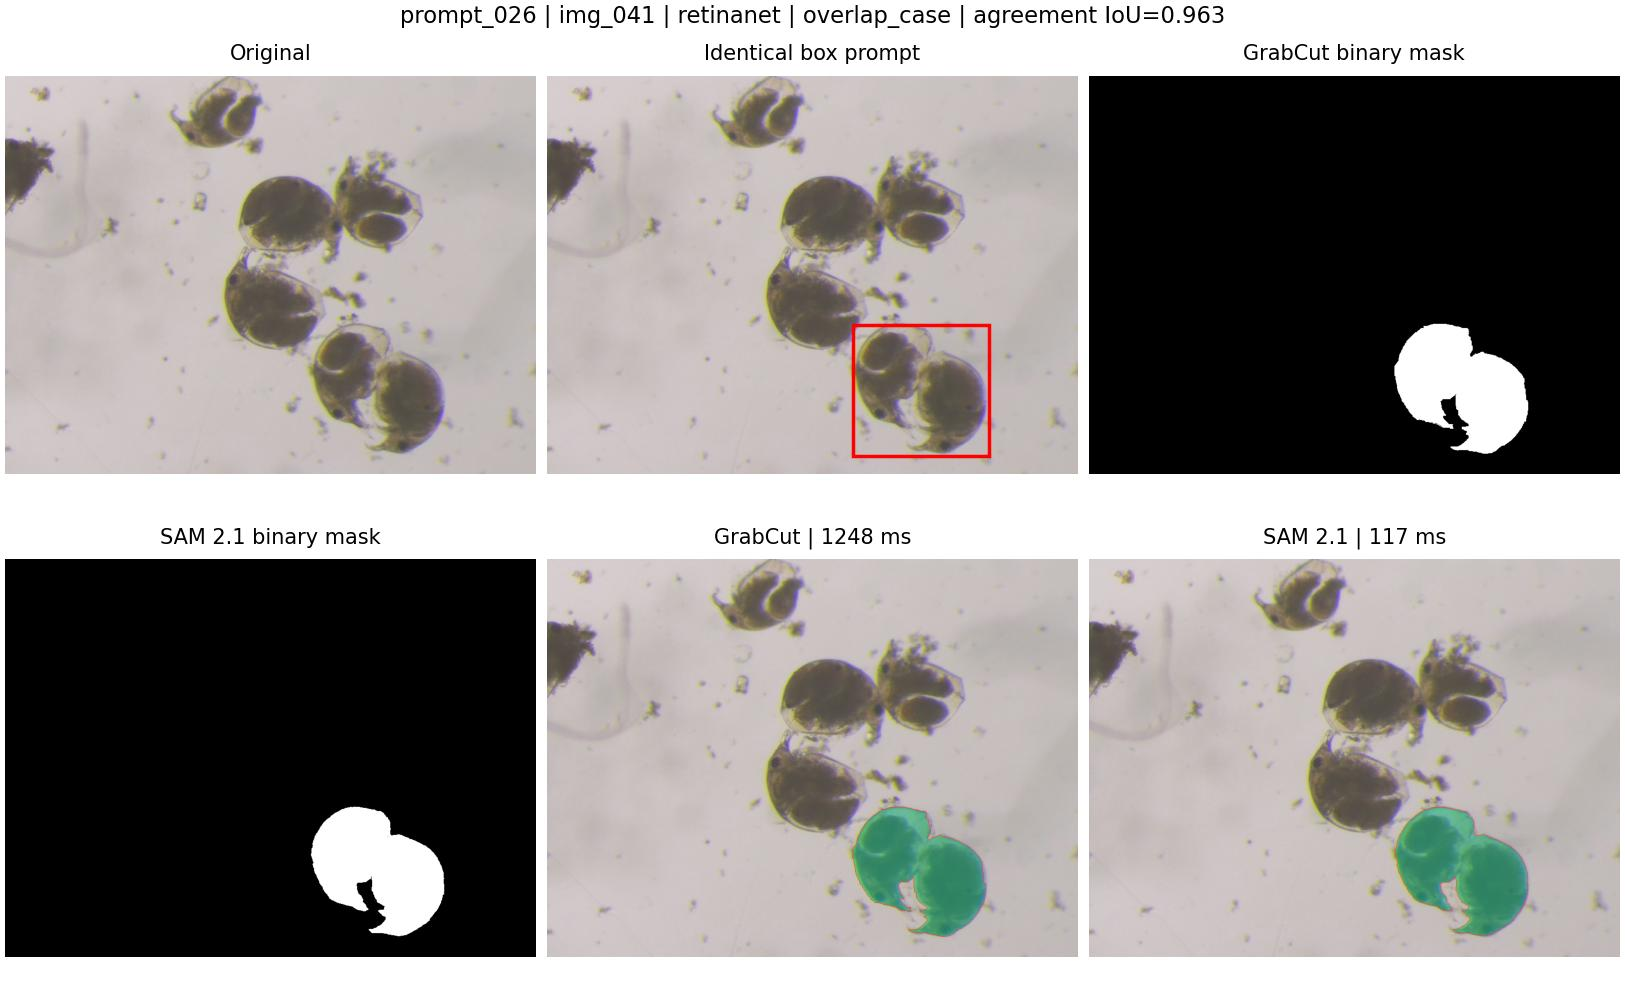

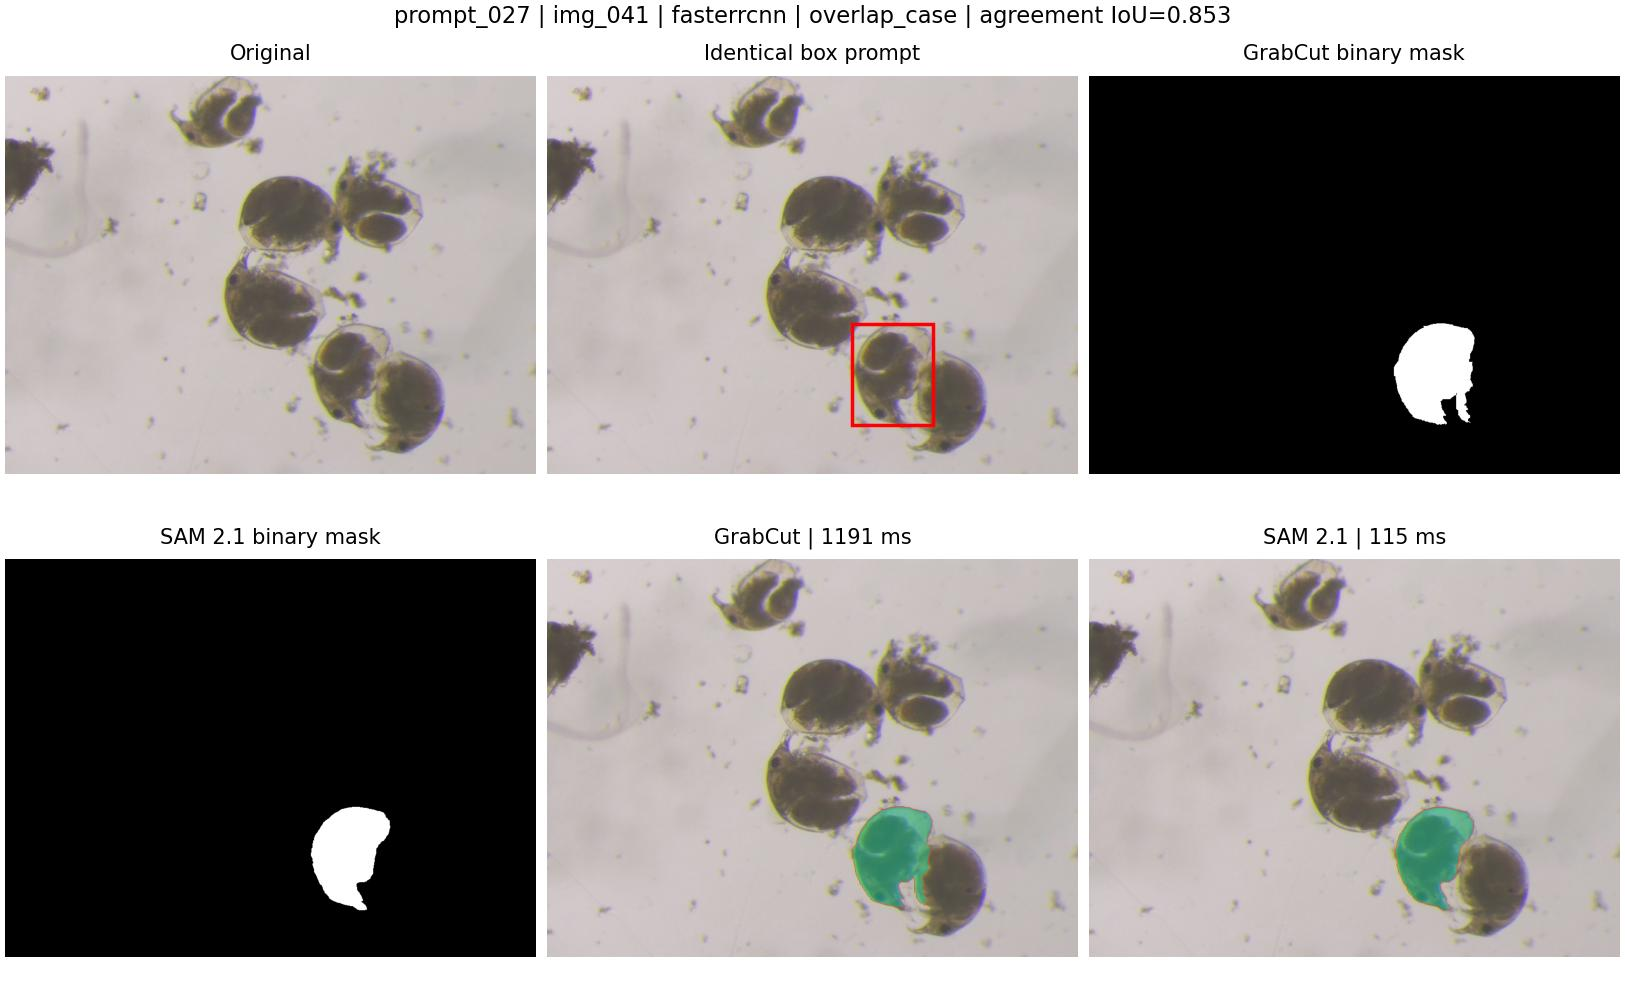

In [13]:
if RUN_EXPERIMENTS:
    segment(DATA_DIR, CHECKPOINT, Path('manual_prompts.json'))
display(pd.read_csv(RESULTS / 'tables/segmentation_summary.csv').round(3))
display(pd.read_csv(RESULTS / 'tables/segmentation_runs.csv').round(3))
# IoU below is agreement BETWEEN METHODS, not IoU against ground truth.
prompts = json.loads((RESULTS / 'segmentation_prompts.json').read_text(encoding='utf-8'))
for p in prompts:
    show_figure(RESULTS / 'segmentation' / f"{p['prompt_id']}_comparison.jpg")

## 5. Сводная таблица шести экспериментов

Четыре группы детекции и два метода сегментации представлены вместе.
Для сегментации сводка использует 22 основные одинаковые рамки; чувствительность
к размеру рамки и два выбранных после просмотра случая перекрытия приведены отдельно.

In [14]:
display(pd.read_csv(RESULTS / 'tables/experiment_comparison.csv').round(3))

,task,method,condition,input_pairs,median_ms,detected_boxes,parameters,observed_differences
0,detection,fasterrcnn,augmented,288,111.934,1052.0,score=0.25;NMS=0.5;FP32;long_side=1024;3 repeats,Сильное размытие/шум снижают сохранность исход...
1,detection,fasterrcnn,original,24,112.105,96.0,score=0.25;NMS=0.5;FP32;long_side=1024;3 repeats,"Больше рамок, но встречаются фоновые области п..."
2,detection,retinanet,augmented,288,59.297,841.0,score=0.25;NMS=0.5;FP32;long_side=1024;3 repeats,При contrast=0.5 меньше рамок; при noise=20 бо...
3,detection,retinanet,original,24,59.326,72.0,score=0.25;NMS=0.5;FP32;long_side=1024;3 repeats,Быстрее; встречаются пропуски мелких объектов ...
4,segmentation,GrabCut,same_22_boxes,22,2455.868,NaN,5 iterations CPU,Чувствителен к размеру рамки; может соединять ...
5,segmentation,SAM2,same_22_boxes,22,115.750,NaN,SAM2.1 Tiny GPU;encoder+decoder;FP32,В ряде примеров лучше сохраняет форму; неверна...


## 5.1. Анализ ошибок и выводы

Следующий раздел составлен по сохранённым числам и визуально просмотренным
примерам. Из-за отсутствия разметки видимые пропуски/ложные обнаружения
указываются качественно, без приписывания точности всему датасету.

# Результаты и анализ

Вычисления основного эксперимента выполнены 12 ноября 2026 года; оформление и
два дополнительных случая перекрытия — 14 ноября. Во всех разделах результаты
наблюдаемые: эталонных bounding boxes и масок нет, поэтому точность и полнота
не оцениваются. Ручные рамки не использовались.

## Данные

Исследованы 189 изображений: 180 JPEG, 8 BMP и 1 TIFF. Площадь изображения
составляет 0,342–9,849 Мп, медиана — 3,146 Мп; часто встречаются 2048×1536 и
2592×1944. Ориентация EXIF учитывается перед измерением и обработкой.
RMS-контраст серого изображения после рабочего resize: 12,08–93,86, медиана
33,13 в шкале 0–255. Средняя яркость: 94,56–220,19. Это характеристики
интенсивностей, а не оценка качества микроскопа или физической освещённости.

На `img_036` видны три небольших организма на светлом неоднородном фоне;
`img_063` содержит плотное поле с большим числом объектов и касаний;
`img_106` — крупный экземпляр с длинными изогнутыми структурами на сером фоне;
`img_144` — прозрачный малоконтрастный организм с тонким хвостовым отростком.
Различаются цветовой оттенок фона, фокусировка, мелкий мусор и протяжённые
волокна. На общих полях тела занимают небольшую часть кадра, на отдельных
снимках — большую. Без калибровки и разметки размеры в микрометрах и истинное
число организмов не определяются.

Выборка из 24 снимков охватывает диапазон контраста внутри трёх групп, но не
является случайной независимой выборкой. Серийные изображения могут быть
коррелированы. Выводы относятся к этому разведочному эксперименту.

## Четыре эксперимента детекции

| Модель / условие | Снимков × вариантов | Рамок при score≥0,25 | Рамок на обработанный снимок | Медиана времени, мс |
|---|---:|---:|---:|---:|
| RetinaNet / оригинал | 24 × 1 | 72 | 3,000 | 59,33 |
| RetinaNet / аугментации | 24 × 12 | 841 | 2,920 | 59,30 |
| Faster R-CNN / оригинал | 24 × 1 | 96 | 4,000 | 112,11 |
| Faster R-CNN / аугментации | 24 × 12 | 1052 | 3,653 | 111,93 |

Для каждого снимка/варианта сначала берётся медиана трёх повторов, затем медиана
по группе. Итоги для оригиналов и аугментаций нельзя сравнивать по суммарному
числу рамок напрямую: во второй группе в 12 раз больше входов. Поэтому
приведена нормировка на обработанный снимок. Время измерено на одной RTX 3060
Laptop, FP32, batch=1; границы замера описаны в README и environment.json.

RetinaNet примерно в 1,89 раза быстрее в этом протоколе. Одна из 24 исходных
картинок у неё не имеет рамок при выбранном пороге; у Faster R-CNN таких
картинок нет. Это не доказывает лучшую полноту Faster R-CNN: рамкой может быть
обведён фон или большой фрагмент сцены.

### Влияние преобразований

При снижении контраста до 0,5 среднее число рамок падает с 3,00 до 1,96 у
RetinaNet и с 4,00 до 2,46 у Faster R-CNN. Средняя по снимкам доля сохранившихся
исходных рамок составляет соответственно 0,467 и 0,521. При умеренном
осветлении ×1,15 — 0,896 и 0,813. Сильное размытие σ=2 даёт 0,602 и 0,537.

Добавление шума не имеет монотонного полезного эффекта. При σ=20 RetinaNet
выдаёт 3,92 рамки в среднем, однако на `img_030` рост с 1 до 7 включает
рамки почти на весь кадр наряду с отдельными организмами. У Faster R-CNN
при σ=5 число рамок возрастает до 4,75, а при σ=20 доля сохранившихся исходных
рамок снижается до 0,515. Большее число предсказаний может сочетать новые
полезные локализации, дубликаты и ложные области.

Даже после точного обратного преобразования координат отражение сохраняет
лишь 0,645 исходных рамок у RetinaNet и 0,760 у Faster R-CNN; поворот — 0,584
и 0,652. Следовательно, модели не полностью эквивариантны этим изменениям.
Высокий IoU *сопоставленных* рамок не компенсирует исчезнувшие рамки: он
условен по успешно найденным парам. Пустые исходные предсказания исключены
из среднего retained_fraction как неопределённые, а не как идеально устойчивые.

### Ошибки и выбор детектора

- `retinanet_img_036_original`: две нижние области локализованы, верхний
  видимый организм пропущен. Метки `apple` и `bird` не соответствуют биологическому
  смыслу; при этом ошибочная COCO-метка сама по себе не делает геометрию рамки
  бесполезной для сегментации.
- `retinanet_img_106_original`: рамка примерно охватывает крупный организм с
  выступающими структурами, хотя предсказан класс `cake`. Это полезное предложение
  области, а не распознавание вида.
- `fasterrcnn_img_041_original`: есть локальные рамки организмов, рамка на весь
  кадр и маленькая ложная область `kite` на фоне. Подобная ошибочная область
  далее действительно поступает в сегментацию (`prompt_010`).
- На 12 общих полях Faster R-CNN выдаёт 13 рамок площадью ≥80% кадра, RetinaNet —
  2. Это диагностический признак, не автоматический подсчёт false positives:
  на снимке одного крупного организма большая рамка может быть корректной.
  На полях с несколькими раздельными организмами она не локализует отдельный
  экземпляр. Числа сохранены в `box_diagnostics.csv`.

Для исходной системы генерации предложений выбираю **RetinaNet**: она быстрее,
а на рассмотренных общих полях реже обводит почти весь кадр. Это практический
выбор с обязательным просмотром рамок, а не доказательство большей точности.
Faster R-CNN местами локализует дополнительные экземпляры и устойчивее к
некоторым преобразованиям; универсального победителя по устойчивости нет.
Для демонстрации сегментации заранее выбрана единая схема рамок Faster R-CNN,
поэтому её не меняли задним числом после сравнения детекторов.

## GrabCut и SAM 2.1

| Метод | Основные подсказки | Медиана на рамку | Особенности наблюдений |
|---|---:|---:|---|
| GrabCut, CPU, 5 итераций | 22 | 2455,87 мс | Хорош при компактной контрастной области; может соединять тонкие структуры с фоном, чувствителен к тесной рамке |
| SAM 2.1 Tiny, GPU, FP32 | те же 22 | 115,75 мс | Часто сохраняет форму и отдельные выступы; при неверной подсказке может выбрать фон или часть организма |

Медиана encoder SAM — 98,70 мс, decoder — 18,37 мс. Это отдельные медианы,
поэтому их сумма не обязана совпадать с медианой полного времени. Encoder
пересчитывался для каждой рамки; его повторное использование ускорило бы
обработку нескольких рамок одного изображения. Сравнение CPU/GPU относится
к выбранным реализациям и оборудованию. Оно не устанавливает превосходство
вычислительной сложности одного алгоритма над другим.

Медиана IoU между масками двух методов на 22 основных рамках — **0,849**.
Это согласие методов, **не IoU с истинной маской и не качество сегментации**.
Пустых масок и исключений выполнения не было, но непустая маска также может
быть полностью неверной. Значение `sam_predicted_iou` — внутренняя оценка SAM,
не измеренная точность на планктоне.

### Просмотр успешных и неуспешных случаев

- `prompt_000`, `img_036`: оба метода выделяют компактное тело в точной рамке,
  межметодный IoU=0,942. Видимое отделение тела от светлого фона хорошее.
- `prompt_001`, тот же снимок: большая ложная рамка `sink` приводит у GrabCut
  к большой фоновой области, а у SAM — почти к инверсной маске с организмами
  как отверстиями. SAM не исправляет ошибку выбора целевого объекта автоматически.
- `prompt_011`, `img_106`: SAM лучше отделяет длинный изогнутый выступ от
  промежуточного фона. GrabCut заполняет пространство между телом и выступом
  крупной областью с прямолинейным краем. У SAM остаются мелкие фрагменты и
  неточности: сохранение всех щетинок не гарантируется.
- `prompt_014`, `img_101`: оба метода передают основную форму, но нижний тонкий
  выступ частично обрезан/искажён; рамка GrabCut жёстко ограничивает область.
- `prompt_016`, прозрачный `img_144`: оба метода находят тело и тонкий хвостовой
  отросток, но некоторые верхние прозрачные структуры остаются вне маски.
  Низкий контраст и тесная рамка мешают обоим методам.
- `prompt_022`: сужение хорошей рамки на 25% обрезает результат GrabCut по
  прямоугольнику; SAM выходит за подсказку и сохраняет более полный контур.
  Это не универсальное правило: для большой ошибочной рамки тот же приём
  (`prompt_024`) приводит к сильному расхождению, IoU между методами всего 0,003.
- `prompt_025`: расширенная ошибочная рамка даёт GrabCut 46,58 с на запрос,
  SAM — 0,113 с, но быстрая маска SAM выделяет почти весь фон. Высокая внутренняя
  оценка SAM около 0,991 в этом случае не подтверждает правильность цели.

Четыре варианта тесной/широкой рамки — анализ чувствительности на двух
исходных подсказках, а не независимая статистическая выборка.
Дополнительные `prompt_026` и `prompt_027` используют реальные рамки детекторов
для касающихся/перекрывающихся экземпляров `img_041`; они выбраны после
визуального просмотра и отделены в таблице как `overlap_case`.
В `prompt_026` общая рамка охватывает два организма: **оба** метода выдают
объединённую маску пары, несмотря на высокое согласие IoU=0,963. В `prompt_027`
более узкая рамка на левый экземпляр помогает обоим отделить его от соседа;
GrabCut захватывает тонкий фрагмент у границы контакта, маска SAM компактнее.
Разница связана прежде всего с подсказкой, поэтому эти два случая не являются
доказательством превосходства одного детектора на всех перекрытиях.
Полностью скрытые части организмов без дополнительных данных восстановить
достоверно нельзя, и задача полного разделения всех перекрытий здесь не решена.

## Вывод

Предобученные на обычных фотографиях детекторы дают полезные предложения
областей, но также пропуски, дубликаты, фоновые рамки и бессмысленные для
микроскопии классы. Умеренные изменения освещения обычно менее разрушительны,
чем сильная потеря контраста; шум и геометрические преобразования выявляют
существенную нестабильность. Ни число рамок, ни confidence не заменяют разметку.

При подходящей рамке SAM 2.1 практически предпочтителен для интерактивного
получения первичных масок на доступной GPU: он быстрее в измеренном протоколе
и в некоторых примерах лучше сохраняет форму тонких структур. GrabCut остаётся
доступной CPU-базой для простого контрастного фона. Главный предел всей цепочки —
выбор правильного экземпляра и рамки: оба сегментатора наследуют ошибки детектора.
Для автоматического подсчёта и морфометрии необходимы проверка экспертом,
калибровка и небольшая независимая контрольная разметка. Эксперимент не
подтверждает готовность методов к автономному биологическому анализу.

## 6. Воспроизводимость и источники

Seed=20261112. В `results/environment.json` записаны фактические версии,
оборудование, параметры и границы замера времени. В `weights_manifest.json`
сохранены SHA256 весов; `dataset_inventory.csv` содержит SHA256 всех снимков.
Структурированные предсказания включают рамки в аугментированных, рабочих
исходных и нативных координатах. Время на другом устройстве будет отличаться;
полная побитовая идентичность CUDA между версиями не гарантируется.

- [Focal Loss / RetinaNet, Lin et al., 2017](https://arxiv.org/abs/1708.02002).
- [Faster R-CNN, Ren et al., 2015](https://arxiv.org/abs/1506.01497).
- [Torchvision: модели и веса](https://docs.pytorch.org/vision/0.21/models.html).
- [GrabCut: документация OpenCV](https://docs.opencv.org/4.x/d8/d83/tutorial_py_grabcut.html).
- [SAM 2: статья](https://arxiv.org/abs/2408.00714).
- [Официальный SAM 2 / инструкции и лицензия](https://github.com/facebookresearch/sam2).
- [Официальные веса SAM 2.1 Tiny](https://huggingface.co/facebook/sam2.1-hiera-tiny).

Результаты не доказывают пригодность к автоматическому подсчёту или определению
видов. Для количественной валидации потребуется небольшая независимая экспертная
разметка; полная ручная разметка не создавалась.